# CNNs vs. Vision Transformers under Data Scarcity
### A parameter-matched comparison across CNN, ViT and CCT architectures on CIFAR-10

---
Antonescu Victor-Gabriel (3245562) &middot;
Di Pietro Letizia (3240910)&middot;
Lukanov Martin (3240480) &middot;
Stoica Alexandru (3260547) &middot;
Troiano Antonio (3198640) 

---

## Motivation

Convolutional Neural Networks (CNNs) and Vision Transformers (ViTs) encode fundamentally
different inductive biases. CNNs exploit **locality** and **translation equivariance** through
shared convolutional filters — a prior that is essential for sample-efficient
visual recognition. ViTs, instead, rely on **global
self-attention** with minimal built-in spatial structure, delegating the task of learning spatial
relationships entirely to the data.

These differences are expected to be most consequential in **low-data regimes**, where inductive
biases act as implicit regularizers. Touvron et al. (2021) showed that ViTs can match CNNs
even at moderate data scales when trained carefully (DeiT), but the question of *how much data*
each architecture truly requires — and *why* — remains actively debated.

This project extends the standard two-way comparison by introducing a third architecture: the
**Compact Convolutional Transformer (CCT)**, proposed by Hassani et al. (2021). The CCT
integrates a convolutional tokenizer into the Transformer framework, injecting locality bias
while retaining the attention mechanism. This three-way comparison allows us to **disentangle**
the contributions of locality, weight sharing, and global attention more finely than a pure
CNN-vs-ViT study can.

---

## Research Questions

| # | Question |
|---|----------|
| 1 | At what data scale does the vanilla ViT close the accuracy gap with the CNN? |
| 2 | Does the CCT outperform both in the low-data regime, thanks to its hybrid inductive bias? |
| 3 | Do data augmentations benefit one architecture disproportionately? |
| 4 | How do representational similarity differ across the three architectures?

---

## Experimental Design

We structure the study in **two parameter-matched regimes**:

- **Primary regime (~5 M parameters):** CNN_large · ViT_large · CCT_large.  
  At this scale the CNN and ViT are both well-specified; the most informative comparison is
  **CNN vs. ViT**. The CCT is acknowledged to be over-parameterised relative to the task.

- **Secondary regime (~0.75 M parameters):** CNN_small · ViT_small · CCT_small.  
  Here the ViT is relatively under-parameterised and struggles the most; the emphasis shifts to
  **CNN vs. CCT**, with the ViT serving as a lower-bound reference.

Each model is trained on CIFAR-10 at five **data fractions** — 10 %, 25 %, 50 %, 75 %, 100 % —
using a fixed seed for reproducibility. All models share the same optimizer (AdamW), learning-rate
schedule (cosine annealing with linear warm-up), and loss function (cross-entropy with label
smoothing 0.1). Two augmentation conditions are evaluated: **with** and **without** standard
random-crop + horizontal-flip augmentation.

---

## References

**Architectures**
- LeCun, Y. et al. (1998). *Gradient-Based Learning Applied to Document Recognition.* Proceedings of the IEEE, 86(11), 2278–2324.
- He, K. et al. (2016). *Deep Residual Learning for Image Recognition.* CVPR 2016.
- Dosovitskiy, A. et al. (2021). *An Image is Worth 16×16 Words: Transformers for Image Recognition at Scale.* ICLR 2021.
- Hassani, A. et al. (2021). *Escaping the Big Data Paradigm with Compact Transformers.* arXiv:2104.05704.

**Dataset**
- Krizhevsky, A. (2009). *Learning Multiple Layers of Features from Tiny Images.* Technical Report, University of Toronto.

**Analysis methods**
- Kornblith, S. et al. (2019). *Similarity of Neural Network Representations Revisited.* ICML 2019. *(CKA)*
- Raghu, M. et al. (2021). *Do Vision Transformers See Like Convolutional Neural Networks?* NeurIPS 2021. *(CKA + attention distance + linear probes)*
- Alain, G. & Bengio, Y. (2016). *Understanding Intermediate Layers Using Linear Classifier Probes.* ICLR Workshop 2017. *(linear probes)*
- Simonyan, K. et al. (2014). *Deep Inside Convolutional Networks: Visualising Image Classification Models and Saliency Maps.* ICLR Workshop 2014. *(gradient saliency / ERF)*


---
## 0 · Setup
---

This section imports all required libraries and defines the global constants used throughout the notebook.

- **PyTorch / torchvision** — model definition, training, and dataset loading
- **NumPy / Matplotlib / Seaborn** — numerical computation and visualisation
- **scikit-learn** — logistic regression for the linear-probe analysis
- **Path constants** — `PT_DIR` / `JSON_DIR` point to the pre-saved model checkpoints and per-epoch JSON histories; results were produced on GPU and are loaded here rather than re-trained, so the notebook runs on CPU without re-executing the full training loop.


In [1]:
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import json, sys, random
from pathlib import Path
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
from torch.autograd import Function

plt.rcParams.update({
    'figure.dpi': 130,
    'font.family': 'sans-serif',
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.alpha': 0.3,
})

CLASSES = ['airplane', 'automobile', 'bird', 'cat', 'deer',
           'dog', 'frog', 'horse', 'ship', 'truck']

In [2]:
BASE_DIR      = Path('.')
PT_DIR        = BASE_DIR / 'parameters_aug'
JSON_DIR      = BASE_DIR / 'resultsxepochs_aug'
PT_DIR_NOAUG    = BASE_DIR / 'parameters_noaug'
JSON_DIR_NOAUG  = BASE_DIR / 'resultsxepochs_noaug'

SEED      = 0
FRACTIONS = [0.1, 0.25, 0.5, 0.75, 1.0]
N_TRAIN   = 50_000
SAMPLES   = [int(N_TRAIN * f) for f in FRACTIONS]

JSON_SUBFOLDERS = {
    'cnn_small': 'CNN(0.75M)', 'vit_small': 'ViT(0.75M)', 'cct_small': 'CCT(0.75M)',
    'cnn_large': 'CNN(5M)',    'vit_large': 'ViT(5M)',     'cct_large': 'CCT(5M)',
}
SMALL_MODELS = ['cnn_small', 'vit_small', 'cct_small']
LARGE_MODELS = ['cnn_large', 'vit_large', 'cct_large']
ALL_MODELS   = SMALL_MODELS + LARGE_MODELS

DISPLAY = {'cnn_small': 'CNN', 'vit_small': 'ViT', 'cct_small': 'CCT',
           'cnn_large': 'CNN', 'vit_large': 'ViT', 'cct_large': 'CCT'}
COLORS  = {'cnn_small': '#E74C3C', 'cnn_large': '#C0392B',
           'vit_small': '#3498DB', 'vit_large': '#1A6FA3',
           'cct_small': '#27AE60', 'cct_large': '#1E8449'}
MARKERS = {'cnn_small': 'o', 'cnn_large': 'o',
           'vit_small': 's', 'vit_large': 's',
           'cct_small': '^', 'cct_large': '^'}


In [3]:
def set_seed(seed):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

set_seed(SEED)

device = torch.device(
    'cuda' if torch.cuda.is_available() else
    'mps'  if torch.backends.mps.is_available() else
    'cpu'
)
print(f'Device: {device}')

Device: mps


---
# 1 · Dataset & Augmentation Pipeline

---

## CIFAR-10

CIFAR-10 (Krizhevsky, 2009) is the standard benchmark for image classification at small scale.
It consists of **60,000 colour images** of size 32×32 pixels, evenly split across **10 semantic
classes**: airplane, automobile, bird, cat, deer, dog, frog, horse, ship, truck.

| Split | Samples | Per class |
|-------|--------:|----------:|
| Training | 50,000 | 5,000 |
| Test | 10,000 | 1,000 |

The images are low-resolution by modern standards, which makes CIFAR-10 an appropriate testbed
for the data-scarcity regime we study: even at 100 % of the training set (50k images), models
are far from the ImageNet-scale data that ViTs were originally designed for. At our lowest
fraction (10 %, i.e. 5,000 images), the task is genuinely hard and inductive biases matter most.

The dataset is **class-balanced** by construction, so accuracy is a reliable performance metric
and there is no need for class-weighted losses.

---

## Data Fractions

To simulate data scarcity, we sub-sample the training set at five fractions, keeping the test
set fixed at 10,000 images across all conditions:

| Fraction | Training samples |
|----------|----------------:|
| 10 % | 5,000 |
| 25 % | 12,500 |
| 50 % | 25,000 |
| 75 % | 37,500 |
| 100 % | 50,000 |

Sub-sampling is stratified by class (uniform random shuffle with fixed seed) so that the
class balance is preserved at every fraction. The **same subset is used across all models and
seeds**, ensuring that accuracy differences reflect architecture rather than data order.

---

## Augmentation Pipeline

We evaluate two augmentation conditions — **with** and **without** standard geometric
augmentation — to assess whether one architecture benefits disproportionately.

### Augmented condition (training only)
| Step | Description |
|---|---|
| `RandomCrop(32, padding=4)` | Pads by 4 pixels on each side, crops a random 32×32 patch → shift invariance |
| `RandomHorizontalFlip(p=0.5)` | Flips horizontally → doubles effective diversity |
| `ToTensor()` | PIL → float tensor in [0, 1] |
| `Normalize(μ, σ)` | Per-channel standardisation using CIFAR-10 train statistics |

The **test set is never augmented** — only ToTensor + Normalize.

Normalisation constants: μ = (0.4914, 0.4822, 0.4465), σ = (0.2023, 0.1994, 0.2010)

In [4]:
raw_train = datasets.CIFAR10(root='./dataset', train=True,  download=False, transform=None)
raw_test  = datasets.CIFAR10(root='./dataset', train=False, download=False, transform=None)

print(f'Train : {len(raw_train):,} images')
print(f'Test  : {len(raw_test):,}  images')
print(f'Classes ({len(CLASSES)}): {CLASSES}')

/opt/anaconda3/envs/project13/lib/python3.11/site-packages/torchvision/datasets/cifar.py:83: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  entry = pickle.load(f, encoding="latin1")


Train : 50,000 images
Test  : 10,000  images
Classes (10): ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


A random sample of CIFAR-10: one image per class, shown without any preprocessing.

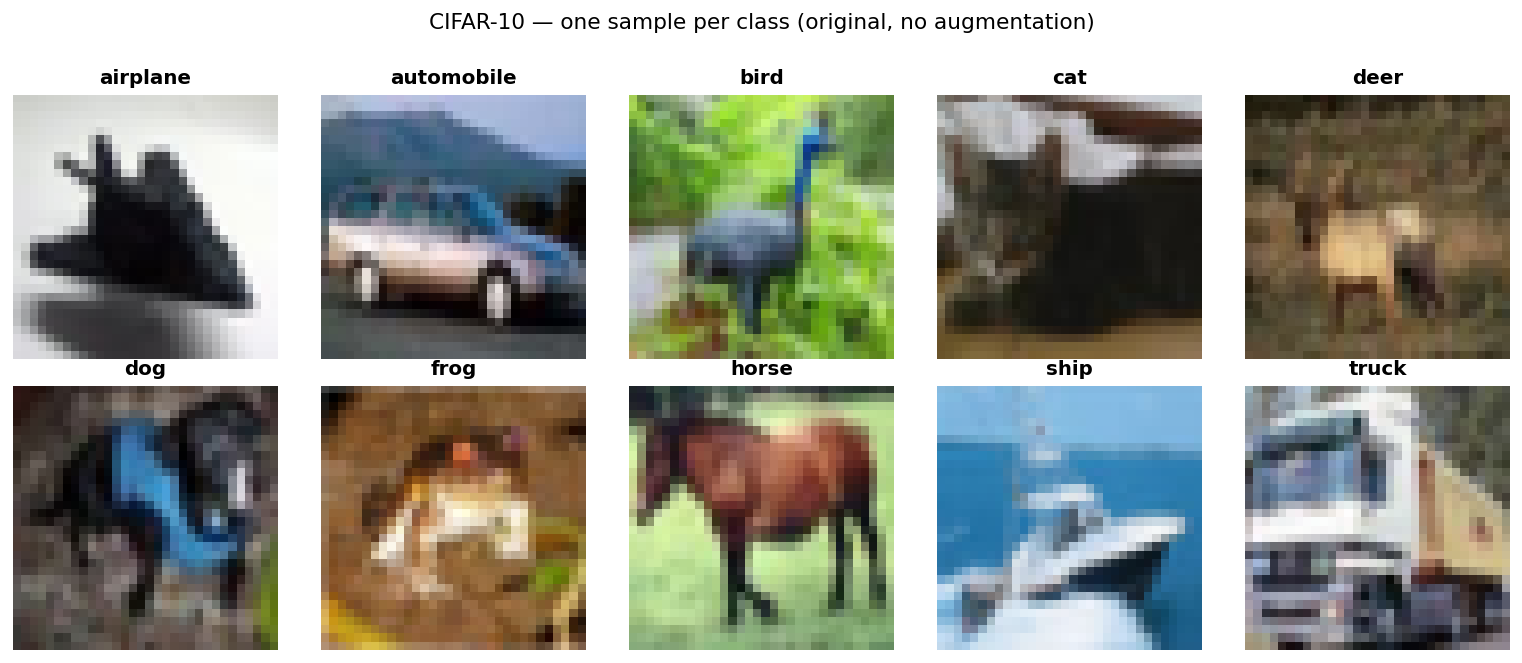

In [5]:
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
seen = {i: False for i in range(10)}

for img, label in raw_train:
    if not seen[label]:
        ax = axes[label // 5][label % 5]
        ax.imshow(img)
        ax.set_title(CLASSES[label], fontsize=11, fontweight='bold')
        ax.axis('off')
        seen[label] = True
    if all(seen.values()):
        break

fig.suptitle('CIFAR-10 — one sample per class (original, no augmentation)', fontsize=12, y=1.01)
plt.tight_layout()
plt.show()

Four classes shown before and after augmentation. Each row pairs the original image (left)
with several augmented variants — random crop and horizontal flip — to illustrate the
distribution shift the model sees during training.

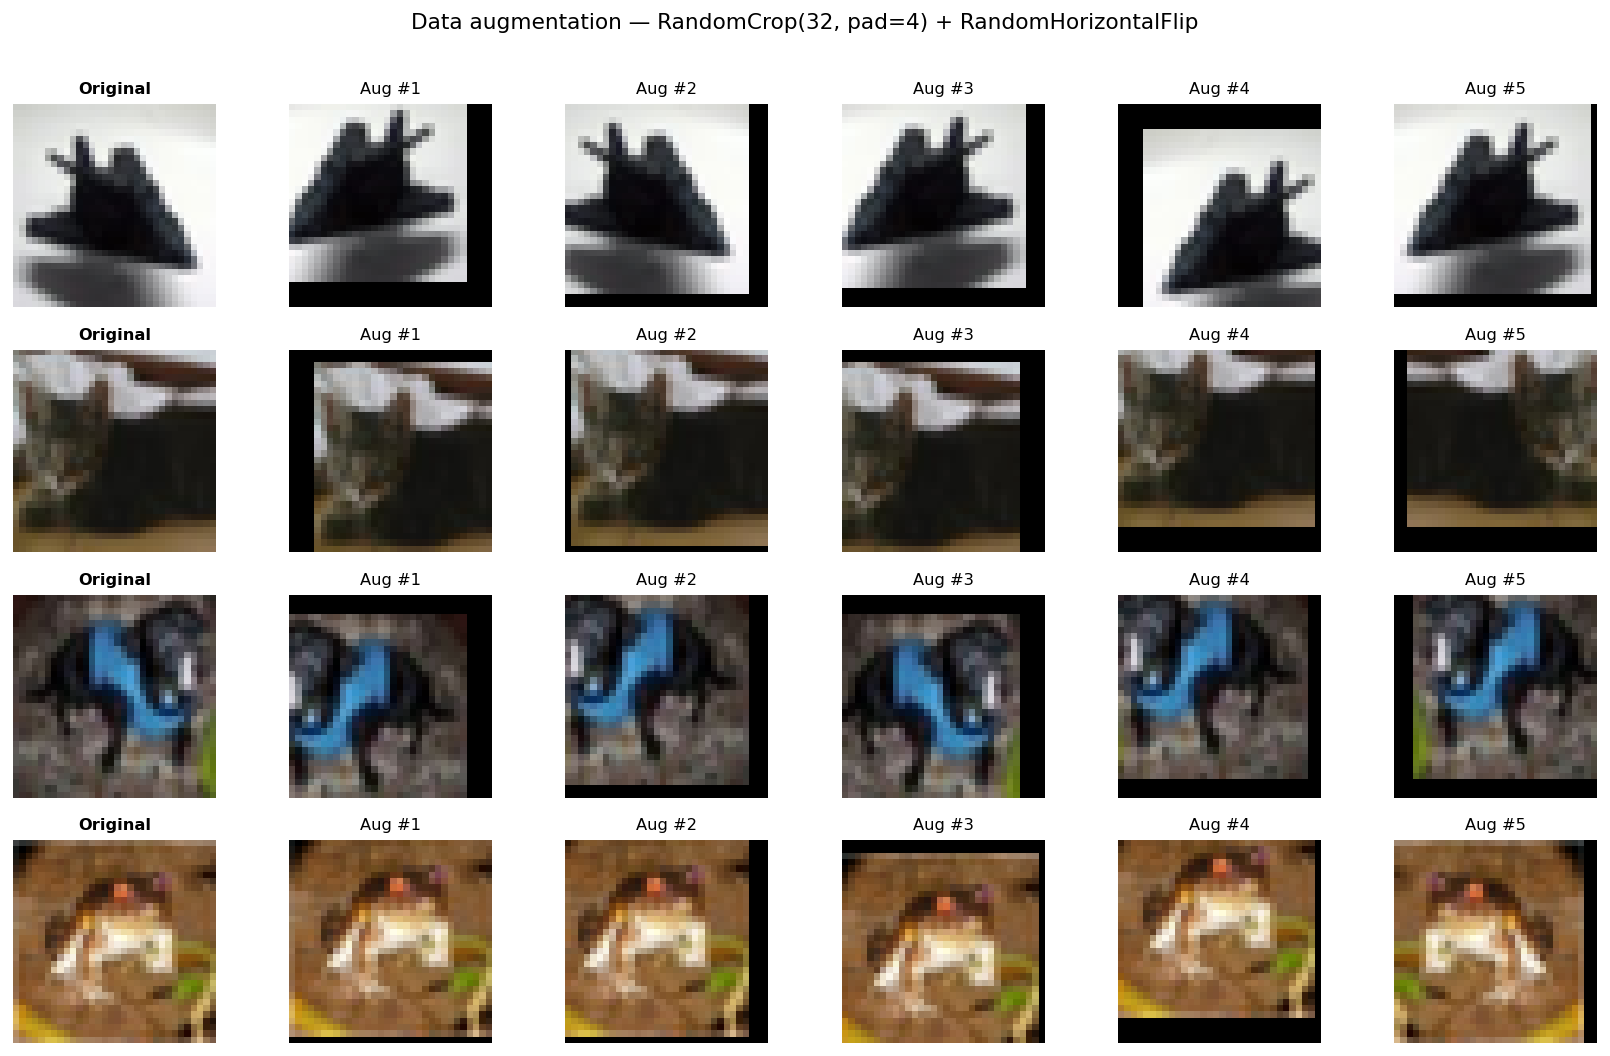

In [6]:
train_transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize((0.4914, 0.4822, 0.4465), (0.2023, 0.1994, 0.2010)),
])

def denormalize(t):
    mean = torch.tensor([0.4914, 0.4822, 0.4465]).view(3, 1, 1)
    std  = torch.tensor([0.2023, 0.1994, 0.2010]).view(3, 1, 1)
    return (t * std + mean).clamp(0, 1)

show_labels = [0, 3, 5, 6]   # airplane, cat, dog, frog
samples = {}
for img, label in raw_train:
    if label in show_labels and label not in samples:
        samples[label] = img
    if len(samples) == len(show_labels):
        break

fig, axes = plt.subplots(len(show_labels), 6, figsize=(13, 8))
for row, label in enumerate(show_labels):
    img = samples[label]
    axes[row, 0].imshow(img)
    axes[row, 0].set_title('Original', fontsize=9, fontweight='bold')
    axes[row, 0].set_ylabel(CLASSES[label], fontsize=10, rotation=90, labelpad=4)
    for col in range(1, 6):
        aug = denormalize(train_transform(img)).permute(1, 2, 0).numpy()
        axes[row, col].imshow(aug)
        axes[row, col].set_title(f'Aug #{col}', fontsize=9)
    for ax in axes[row]:
        ax.axis('off')

fig.suptitle('Data augmentation — RandomCrop(32, pad=4) + RandomHorizontalFlip', fontsize=12, y=1.01)
plt.tight_layout()
plt.show()

---
## 2 · Architecture Overview

All six models share the same dataset (CIFAR-10, 32 × 32 RGB), optimizer, and training
protocol. They differ only in **how they tokenize the image** and **how they mix spatial
information** — the two axes that determine inductive bias and, ultimately, sample efficiency.

---

### CNN — Convolutional Neural Network

**Inductive bias: strong** — locality, weight sharing, translation equivariance.

A CNN processes the image through a stack of convolutional layers, each applying a small
3 × 3 kernel to a local spatial neighbourhood. This hard-wires two assumptions: nearby pixels
are more informative than distant ones, and the same feature detector is useful everywhere in
the image. LeCun et al. showed that this prior dramatically reduces effective degrees of
freedom, making CNNs remarkably sample-efficient even at low parameter counts.

|  | **CNN\_small** (~0.77 M) | **CNN\_large** (~4.9 M) |
|---|---|---|
| **Stem** | Conv 3×3 → BN → ReLU | Conv 3×3 → BN → GELU |
| **Body** | 3 stages (64 → 128 → 256), MaxPool 2×2 | 3 stages (96 → 192 → 320), stride-2 residual blocks |
| **Skip connections** | — | ✓ ResNet-style (identity + 1×1 projection) |
| **Pooling** | MaxPool ×3 | AdaptiveAvgPool |
| **Head** | Flatten → Linear(4096 → 96) → ReLU → Linear(96 → 10) | Linear(320 → 10) |
| **Dropout** | 0.5 | 0.2 |

The large CNN is a **ResNet-12 variant**: each residual block applies `Conv 3×3 → BN → GELU`
twice, with a skip connection that uses a 1×1 convolution to match dimensions when the channel
count changes. Skip connections ease gradient flow and allow higher capacity without
destabilising training.

---

### ViT — Vision Transformer

**Inductive bias: minimal** — only a learnable positional embedding.

Following Dosovitskiy et al. (2021), the image is divided into non-overlapping **4×4 patches**
(64 patches for a 32×32 image) via a strided Conv2d acting as a linear projection. A **CLS
token** is prepended to the sequence, and a learnable absolute positional embedding is added
to every token. The sequence is then processed by a stack of standard Transformer encoder
blocks, each following the Pre-LN residual pattern:
`x → LayerNorm → MultiHeadAttention → + x → LayerNorm → MLP (GELU) → + x`.

Classification is read from the CLS token after the final LayerNorm.

|  | **ViT\_small** (~0.76 M) | **ViT\_large** (~4.98 M) |
|---|---|---|
| **Patch size** | 4 × 4 | 4 × 4 |
| **Embedding dim** | 128 | 320 |
| **Transformer blocks** | 5 | 6 |
| **Attention heads** | 4 | 4 |
| **MLP dim** | 320 | 640 |
| **Dropout** | 0.1 | 0.1 |

Because the ViT has no spatial prior, it must learn from scratch that nearby patches are
related. Raghu et al. (2021) showed that ViTs develop more uniform representations across
layers compared to CNNs and rely on global attention from the very first block — an asset at
scale, but a liability when training data are scarce.

---

### CCT — Compact Convolutional Transformer

**Inductive bias: hybrid** — convolutional tokenizer + global attention + sequence pooling.

Proposed by Hassani et al. (2021) to address the ViT's data hunger, the CCT replaces the
patch-projection stem with a **convolutional tokenizer**: two `Conv 3×3 → BN → ReLU → MaxPool
3×3 (stride 2)` blocks that reduce 32×32 input to an 8×8 feature map, yielding 64 overlapping
token embeddings. This gives the model an explicit locality prior *before* attention begins.

Two further departures from vanilla ViT:

- **No CLS token.** CCT uses **sequence pooling**: a small linear layer learns a scalar
  attention score for each token, and the final representation is their weighted average.
  This is strictly more expressive than a fixed CLS token.
- **Pre-LN Transformer** (`norm_first=True`), which improves gradient flow and training
  stability in low-data settings.

|  | **CCT\_small** (~0.73 M) | **CCT\_large** (~5.26 M) |
|---|---|---|
| **Tokenizer** | Conv 3×3 (×2) + MaxPool → 64 tokens | same |
| **Embedding dim** | 160 | 300 |
| **Transformer blocks** | 4 | 7 |
| **Attention heads** | 4 | 4 |
| **MLP dim** | 160 | 600 |
| **Pooling** | Sequence pooling (learned) | same |
| **Dropout** | 0.1 | 0.1 |

The CCT occupies a deliberate middle ground: the convolutional tokenizer handles *what* local
features look like, while the Transformer asks *where* to direct attention globally. The
hypothesis is that this hybrid is especially advantageous when training data are scarce,
because the convolutional prior reduces the search space the attention mechanism must cover.

---

### Why is the CCT over-parameterised at ~5 M?

Hassani et al. (2021) report that **CCT-7/3×1 reaches 95.04% on CIFAR-10 with just 3.76 M
parameters**. Scaling to 5 M (CCT-7/3×2 with `mlp_dim = 2 · embed_dim`) overshoots the
capacity sweet-spot: the convolutional tokenizer already provides the inductive bias that lets
a *smaller* CCT match a *larger* ViT, so adding more parameters yields diminishing returns.
At 5 M the compactness advantage disappears, and the cleanest signal is **CNN vs. ViT**.

### Why is the ViT under-parameterised at ~0.75 M?

The vanilla ViT has zero locality bias — it must compensate entirely with capacity and data.
At 0.75 M parameters and 5 000 training images (10% regime) the model's flexibility becomes a
liability rather than a strength. The CCT, by contrast, enjoys free locality from its conv
tokenizer, making it a fair competitor to the CNN at this scale and a natural baseline for
the small-model regime.



In [7]:
sys.path.insert(0, str(BASE_DIR / 'models'))

import cct_small_script, cct_large_script
import cnn_small_script, cnn_large_script
import vit_small_script, vit_large_script

# ViT large uses non-default constructor args
def _vit_large():
    return vit_large_script.ViT_large(
        emb_dim=320, n_layers=6, heads=4, mlp_dim=640, dropout=0.1
    )

MODEL_CLASSES = {
    'cnn_small': cnn_small_script.CNN_small,
    'vit_small': vit_small_script.ViT_small,
    'cct_small': cct_small_script.CCT_small,
    'cnn_large': cnn_large_script.CNN_large,
    'vit_large': _vit_large,
    'cct_large': cct_large_script.CCT_large,
}

ARCH_DETAIL = {
    'cnn_small': '3 conv stages, MaxPool, FC head',
    'vit_small': 'patch=4, emb=128, layers=5, heads=4, mlp=320',
    'cct_small': 'conv tokenizer, emb=160, layers=4, heads=4, seq-pool',
    'cnn_large': 'ResNet-style residual blocks, AdaptiveAvgPool',
    'vit_large': 'patch=4, emb=320, layers=6, heads=4, mlp=640',
    'cct_large': 'conv tokenizer, emb=300, layers=7, heads=4, seq-pool',
}

print(f"{'Model':<12}  {'Params':>10}  Details")
print('─' * 70)
param_counts = {}
for name, cls in MODEL_CLASSES.items():
    m = cls()
    n = sum(p.numel() for p in m.parameters() if p.requires_grad)
    param_counts[name] = n
    print(f"{name:<12}  {n:>10,}  {ARCH_DETAIL[name]}")

Model             Params  Details
──────────────────────────────────────────────────────────────────────
cnn_small        765,546  3 conv stages, MaxPool, FC head
vit_small        760,906  patch=4, emb=128, layers=5, heads=4, mlp=320
cct_small        727,467  conv tokenizer, emb=160, layers=4, heads=4, seq-pool
cnn_large      4,904,522  ResNet-style residual blocks, AdaptiveAvgPool
vit_large      4,976,970  patch=4, emb=320, layers=6, heads=4, mlp=640
cct_large      5,261,467  conv tokenizer, emb=300, layers=7, heads=4, seq-pool


/opt/anaconda3/envs/project13/lib/python3.11/site-packages/torch/nn/modules/transformer.py:379: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  warnings.warn(


Trainable parameter counts for all six models, split by regime (~5 M and ~0.75 M).
Confirms that the three large and three small models are approximately matched in capacity.

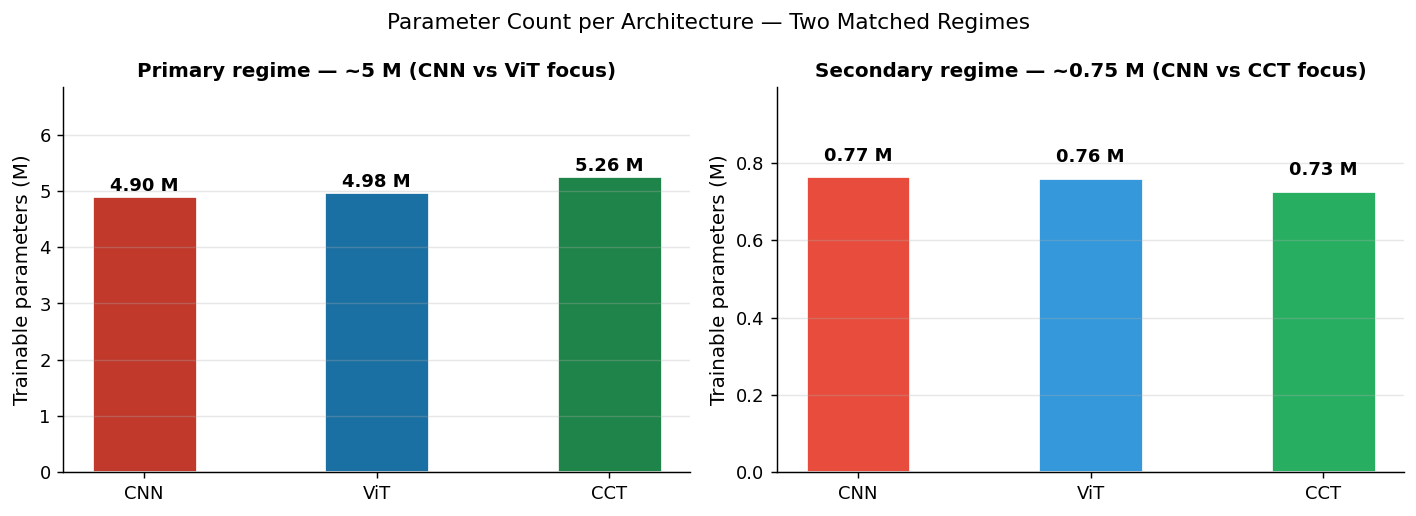

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

for ax, models, title in zip(
    axes,
    [LARGE_MODELS, SMALL_MODELS],
    ['Primary regime — ~5 M (CNN vs ViT focus)',
     'Secondary regime — ~0.75 M (CNN vs CCT focus)'],
):
    names  = [DISPLAY[m] for m in models]
    counts = [param_counts[m] / 1e6 for m in models]
    colors = [COLORS[m] for m in models]
    bars   = ax.bar(names, counts, color=colors, width=0.45, edgecolor='white', linewidth=1.5)
    for bar, c in zip(bars, counts):
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.03,
                f'{c:.2f} M', ha='center', va='bottom', fontsize=10, fontweight='bold')
    ax.set_ylabel('Trainable parameters (M)', fontsize=11)
    ax.set_title(title, fontsize=11, fontweight='bold')
    ax.set_ylim(0, max(counts) * 1.3)
    ax.grid(axis='x', alpha=0)

fig.suptitle('Parameter Count per Architecture — Two Matched Regimes', fontsize=12)
plt.tight_layout()
plt.show()

In [9]:
# Architecture hyper-parameters 
ARCH_SPECS = {
    'cnn_small': {
        'family':       'CNN — plain convolutional',
        'depth':        '3 conv stages',
        'channels':     '3 → 64 → 128 → 256',
        'tokenizer':    '—',
        'embed_dim':    '—',
        'heads':        '—',
        'mlp_dim':      'FC bottleneck = 96',
        'dropout':      0.5,
        'pooling':      'MaxPool 2x2 x3',
        'head':         'Flatten → Linear(4096→96) → ReLU → Linear(96→10)',
        'inductive_bias':'Strong (locality, weight sharing, translation equivariance)',
    },
    'cnn_large': {
        'family':       'CNN — ResNet-style residual',
        'depth':        '3 stages x 2 residual blocks (≈ ResNet-12)',
        'channels':     '3 → 96 → 192 → 320',
        'tokenizer':    '—',
        'embed_dim':    '—',
        'heads':        '—',
        'mlp_dim':      '—',
        'dropout':      0.2,
        'pooling':      'AdaptiveAvgPool',
        'head':         'AvgPool → Linear(320→10)',
        'inductive_bias':'Strong (locality + skip connections ease optimisation)',
    },
    'vit_small': {
        'family':       'Vision Transformer (vanilla)',
        'depth':        '5 transformer blocks',
        'channels':     '—',
        'tokenizer':    'Patch 4x4, strided Conv2d (no overlap)',
        'embed_dim':    128,
        'heads':        4,
        'mlp_dim':      320,
        'dropout':      0.1,
        'pooling':      'CLS token',
        'head':         'LayerNorm(CLS) → Linear(128→10)',
        'inductive_bias':'None (only learnable positional embedding)',
    },
    'vit_large': {
        'family':       'Vision Transformer (vanilla)',
        'depth':        '6 transformer blocks',
        'channels':     '—',
        'tokenizer':    'Patch 4x4, strided Conv2d (no overlap)',
        'embed_dim':    320,
        'heads':        4,
        'mlp_dim':      640,
        'dropout':      0.1,
        'pooling':      'CLS token',
        'head':         'LayerNorm(CLS) → Linear(320→10)',
        'inductive_bias':'None (only learnable positional embedding)',
    },
    'cct_small': {
        'family':       'Compact Convolutional Transformer',
        'depth':        '4 transformer blocks',
        'channels':     '—',
        'tokenizer':    'Conv tokenizer (3x3 conv + ReLU + MaxPool, overlapping)',
        'embed_dim':    160,
        'heads':        4,
        'mlp_dim':      160,
        'dropout':      0.1,
        'pooling':      'Sequence pooling (learned attention, no CLS)',
        'head':         'SeqPool → Linear(160→10)',
        'inductive_bias':'Mixed (conv tokenizer adds locality to a Transformer body)',
    },
    'cct_large': {
        'family':       'Compact Convolutional Transformer',
        'depth':        '7 transformer blocks',
        'channels':     '—',
        'tokenizer':    'Conv tokenizer (3x3 conv + ReLU + MaxPool, overlapping)',
        'embed_dim':    300,
        'heads':        4,
        'mlp_dim':      600,
        'dropout':      0.1,
        'pooling':      'Sequence pooling (learned attention, no CLS)',
        'head':         'SeqPool → Linear(300→10)',
        'inductive_bias':'Mixed (conv tokenizer adds locality to a Transformer body)',
    },
}


---
## 3 · Training Protocol
---

All six models were trained **on GPU** with the same protocol. Results are loaded from pre-saved checkpoints.

| Hyperparameter | Value |
|---|---|
| Epochs per fraction | 150 |
| Optimizer | AdamW (β₁ = 0.9, β₂ = 0.999) |
| Peak LR | 1 × 10⁻³ |
| Weight decay | 5 × 10⁻² |
| LR schedule | Linear warmup (≈ 7 epochs) → cosine annealing to 0 |
| Batch size | 256 |
| Loss function | CrossEntropyLoss with label smoothing ε = 0.1 |
| Gradient clipping | max\_norm = 1.0 |
| Mixed precision | AMP (GPU only) |
| Data fractions | 0.10, 0.25, 0.50, 0.75, 1.00 |
| Seeds | seed = 0 (multi-seed runs pending) |

**Nested subset sampling**: at each fraction the training indices are shuffled with the same fixed seed
and the first `N × fraction` samples are selected — so smaller fractions are always strict subsets of larger ones.

Each `.json` file in `resultsxepochs/` stores `[{epoch, loss, acc}, ...]` with `loss` = average training loss
over all batches in the epoch and `acc` = test accuracy at end of epoch.

---
## 4 · Load Results
---

Results for all models and data fractions are loaded from pre-saved JSON files (one per model × fraction × augmentation condition).
Each file contains a list of epoch-level records: `[{epoch, loss, acc}, ...]`, where `loss` is the mean training loss over all batches in that epoch and `acc` is the test accuracy evaluated at the end of the epoch.
The helper `load_history(model_name, frac, aug)` wraps path resolution and JSON parsing; `final_acc` extracts the last-epoch test accuracy for a given (model, fraction) pair.


In [10]:
def load_history(model_name: str, frac: float, aug: bool = True) -> list:
    subfolder = JSON_SUBFOLDERS[model_name]
    if aug:
        path = JSON_DIR / subfolder / f'{model_name}_seed{SEED}_frac{frac}.json'
    else:
        path = JSON_DIR_NOAUG / subfolder / f'{model_name}_noaug_seed{SEED}_frac{frac}.json'
        # Fallback for cct_large / frac=0.75 which is stored as 'newnoaug'
        if not path.exists():
            alt = JSON_DIR_NOAUG / subfolder / f'{model_name}_newnoaug_seed{SEED}_frac{frac}.json'
            if alt.exists():
                path = alt
    with open(path) as f:
        return json.load(f)

results = {
    model: {frac: load_history(model, frac, aug=True) for frac in FRACTIONS}
    for model in ALL_MODELS
}
results_noaug = {
    model: {frac: load_history(model, frac, aug=False) for frac in FRACTIONS}
    for model in ALL_MODELS
}

def epochs(model, frac):     return [h['epoch'] for h in results[model][frac]]
def train_loss(model, frac): return [h['loss']  for h in results[model][frac]]
def test_acc(model, frac):   return [h['acc'] * 100 for h in results[model][frac]]
def final_acc(model, frac):  return results[model][frac][-1]['acc'] * 100
def best_acc(model, frac):   return max(h['acc'] for h in results[model][frac]) * 100

def final_acc_noaug(model, frac): return results_noaug[model][frac][-1]['acc'] * 100
def best_acc_noaug(model, frac):  return max(h['acc'] for h in results_noaug[model][frac]) * 100
def test_acc_noaug(model, frac):  return [h['acc'] * 100 for h in results_noaug[model][frac]]
def train_loss_noaug(model, frac):return [h['loss']  for h in results_noaug[model][frac]]

print(f"{'Model':<12}  {'10%':>7}  {'25%':>7}  {'50%':>7}  {'75%':>7}  {'100%':>7}")
print('─' * 54)
print('AUGMENTED:')
for model in ALL_MODELS:
    row = '  '.join(f'{final_acc(model, f):7.2f}' for f in FRACTIONS)
    print(f'{model:<12}  {row}')
print('NO AUGMENTED:')
for model in ALL_MODELS:
    row = '  '.join(f'{final_acc_noaug(model, f):7.2f}' for f in FRACTIONS)
    print(f'{model:<12}  {row}')


Model             10%      25%      50%      75%     100%
──────────────────────────────────────────────────────
AUGMENTED:
cnn_small       77.40    83.41    87.07    88.28    89.27
vit_small       53.73    65.52    74.08    79.58    82.60
cct_small       68.11    79.19    84.90    87.62    89.65
cnn_large       79.80    88.57    92.18    93.94    94.91
vit_large       54.40    68.28    77.53    82.43    85.80
cct_large       70.47    81.13    86.55    89.36    90.84
NO AUGMENTED:
cnn_small       68.10    74.34    78.23    80.24    81.73
vit_small       50.27    58.10    64.95    69.45    73.15
cct_small       65.18    76.05    81.81    84.96    86.70
cnn_large       67.50    78.61    84.74    87.66    90.03
vit_large       50.96    58.81    67.41    71.92    76.19
cct_large       66.19    77.24    83.76    86.94    88.79


---
# 5 · Primary Analysis — ~5 M Parameters
---
## CNN vs. ViT at Scale
At ~5 M parameters, both the CNN and the ViT are adequately sized for CIFAR-10: neither is
starved of capacity nor trivially over-fit. Any performance gap between them therefore reflects
**inductive bias** rather than a capacity mismatch — making this the cleanest regime for
isolating the effect of architectural prior. The CCT is included for completeness, but at this
scale its compactness advantage has dissolved.

### Reading Guide: 5M Regime (CNN vs. ViT)

* **Accuracy Gap (CNN − ViT)**: we anticipate a positive performance gap in favor of the CNN at lower data fractions. This delta is expected to narrow monotonically as the dataset size increases; the point of near-parity (or crossover) identifies the threshold at which the lack of **locality bias** ceases to be a significant bottleneck for the Vision Transformer.
* **Learning Curve Dynamics**: the ViT typically exhibits slower convergence and stabilizes at a lower accuracy plateau when trained on smaller data subsets. Conversely, the CNN achieves high performance rapidly due to its strong inductive biases, deriving diminishing returns from extended training epochs once it has successfully modeled the signal.
* **Within-Model CKA (Representational Hierarchy)**:
    1) **CNNs** are expected to display a clear layer-wise hierarchy, characterized by low CKA similarity between distant layers as the features become increasingly specialized.
    2) **ViTs** often show a more uniform inter-layer similarity throughout the architecture; this "global" representation style is typically more pronounced when the model is starved for data.
* **Cross-Architecture CKA**: as data availability increases, the internal representations of the CNN and ViT should converge toward similar structures. Notably, very high similarity between **CCT and CNN** at low data fractions would support the hypothesis that the CCT’s representation is dominated by the inductive priors of its **convolutional tokenizer**.

**Test accuracy vs. training set size (log scale)** for the three large models.  
The x-axis spans five data fractions (10 %–100 %); the y-axis shows final test accuracy.

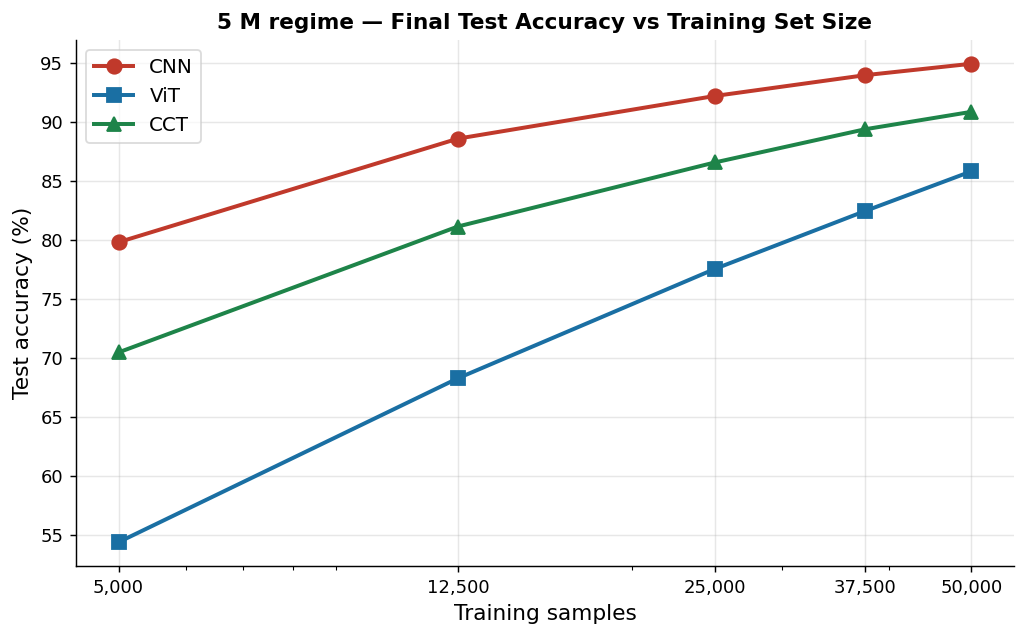

In [11]:
# ── Final test accuracy vs data fraction — large (5M) regime ──────────────────
fig, ax = plt.subplots(figsize=(8, 5))

for model in LARGE_MODELS:
    accs = [final_acc(model, f) for f in FRACTIONS]
    ax.plot(SAMPLES, accs, color=COLORS[model], marker=MARKERS[model],
            linewidth=2.2, markersize=8, label=DISPLAY[model])

ax.set_xscale('log')
ax.set_xticks(SAMPLES)
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{int(x):,}'))
ax.set_xlabel('Training samples', fontsize=12)
ax.set_ylabel('Test accuracy (%)', fontsize=12)
ax.set_title('5 M regime — Final Test Accuracy vs Training Set Size', fontsize=12, fontweight='bold')
ax.legend(fontsize=11, framealpha=0.7)
plt.tight_layout()
plt.savefig('fig1_acc_5M.pdf', bbox_inches='tight')
plt.show()

**CNN accuracy minus ViT / CCT accuracy at each data fraction**.  
Positive values mean the CNN outperforms; the slope of the curve shows whether the gap widens or narrows with more data.

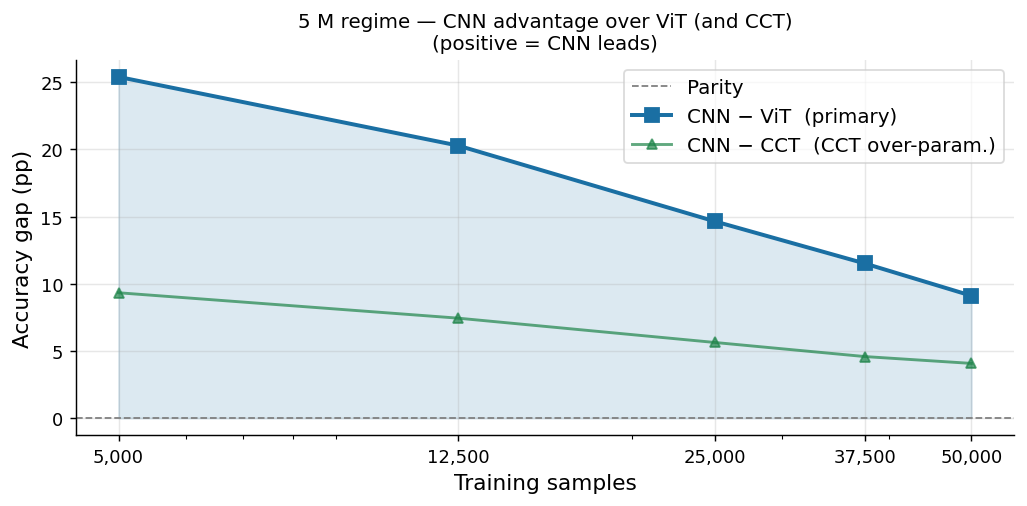

In [12]:
# ── CNN vs ViT gap (primary comparison at 5 M) ────────────────────────────────
cnn_l = np.array([final_acc('cnn_large', f) for f in FRACTIONS])
vit_l = np.array([final_acc('vit_large', f) for f in FRACTIONS])
cct_l = np.array([final_acc('cct_large', f) for f in FRACTIONS])

fig, ax = plt.subplots(figsize=(8, 4))
ax.axhline(0, color='gray', linewidth=1.0, linestyle='--', label='Parity')
ax.fill_between(SAMPLES, 0, cnn_l - vit_l, alpha=0.15, color='#1A6FA3')
ax.plot(SAMPLES, cnn_l - vit_l, color='#1A6FA3', marker='s',
        linewidth=2.2, markersize=8, label='CNN − ViT  (primary)')
ax.plot(SAMPLES, cnn_l - cct_l, color='#1E8449', marker='^',
        linewidth=1.6, markersize=6, alpha=0.7, label='CNN − CCT  (CCT over-param.)')

ax.set_xscale('log')
ax.set_xticks(SAMPLES)
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{int(x):,}'))
ax.set_xlabel('Training samples', fontsize=12)
ax.set_ylabel('Accuracy gap (pp)', fontsize=12)
ax.set_title('5 M regime — CNN advantage over ViT (and CCT)\n'
             '(positive = CNN leads)', fontsize=11)
ax.legend(fontsize=11, framealpha=0.7)
plt.tight_layout()
plt.savefig('fig2_gap_5M.pdf', bbox_inches='tight')
plt.show()

**Per-model learning curves at all five data fractions.**  
Each row is one architecture; the two columns show training loss and test accuracy over epochs. Useful for spotting overfitting and
convergence speed.

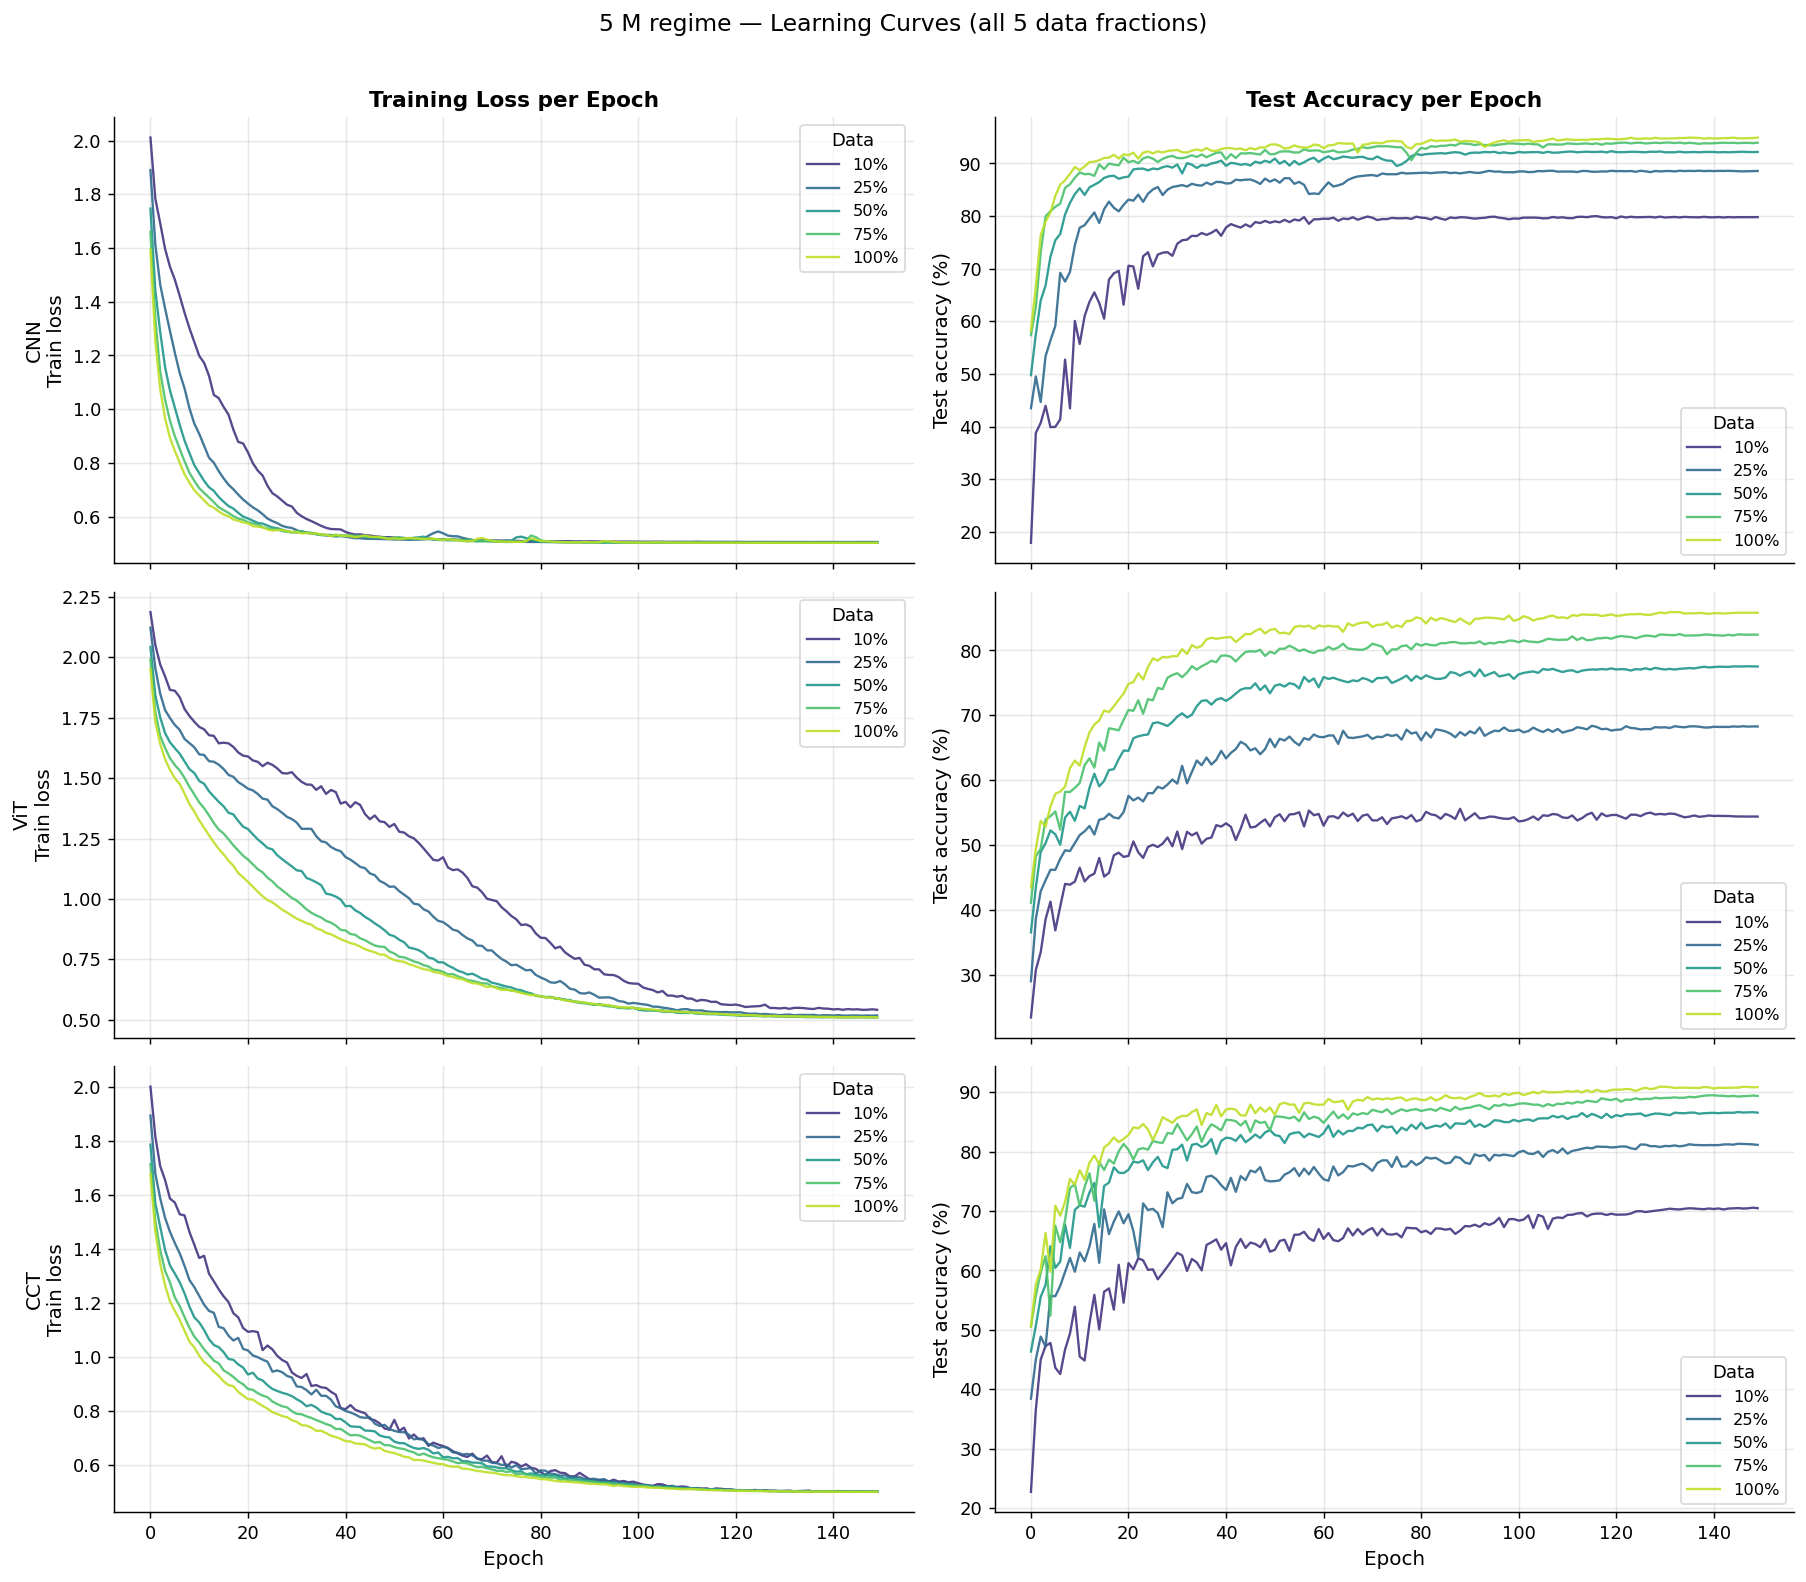

In [13]:
# ── Learning curves at 5 M — one row per architecture, all 5 fractions ────────
fig, axes = plt.subplots(3, 2, figsize=(14, 12), sharex=True)
frac_colors = plt.cm.viridis(np.linspace(0.15, 0.9, len(FRACTIONS)))

for row, model in enumerate(LARGE_MODELS):
    ax_loss, ax_acc = axes[row, 0], axes[row, 1]
    arch_name = DISPLAY[model]

    for frac, fc in zip(FRACTIONS, frac_colors):
        ep = epochs(model, frac)
        ax_loss.plot(ep, train_loss(model, frac), color=fc, linewidth=1.3,
                     alpha=0.9, label=f'{int(frac*100)}%')
        ax_acc.plot( ep, test_acc(model, frac),   color=fc, linewidth=1.3,
                     alpha=0.9, label=f'{int(frac*100)}%')

    ax_loss.set_ylabel(f'{arch_name}\nTrain loss', fontsize=11)
    ax_acc.set_ylabel('Test accuracy (%)', fontsize=11)
    ax_loss.legend(title='Data', fontsize=9, framealpha=0.7)
    ax_acc.legend( title='Data', fontsize=9, framealpha=0.7)

for ax in axes[-1]:
    ax.set_xlabel('Epoch', fontsize=11)

axes[0, 0].set_title('Training Loss per Epoch', fontsize=12, fontweight='bold')
axes[0, 1].set_title('Test Accuracy per Epoch', fontsize=12, fontweight='bold')

fig.suptitle('5 M regime — Learning Curves (all 5 data fractions)', fontsize=13, y=1.01)
plt.tight_layout()
plt.savefig('fig3_lc_per_arch_5M.pdf', bbox_inches='tight')
plt.show()

**Cross-architecture comparison of loss and accuracy trajectories at three representative fractions (10 %, 50 %, 100 %).**  
All models on the same axes to make convergence speed and
final performance directly comparable.

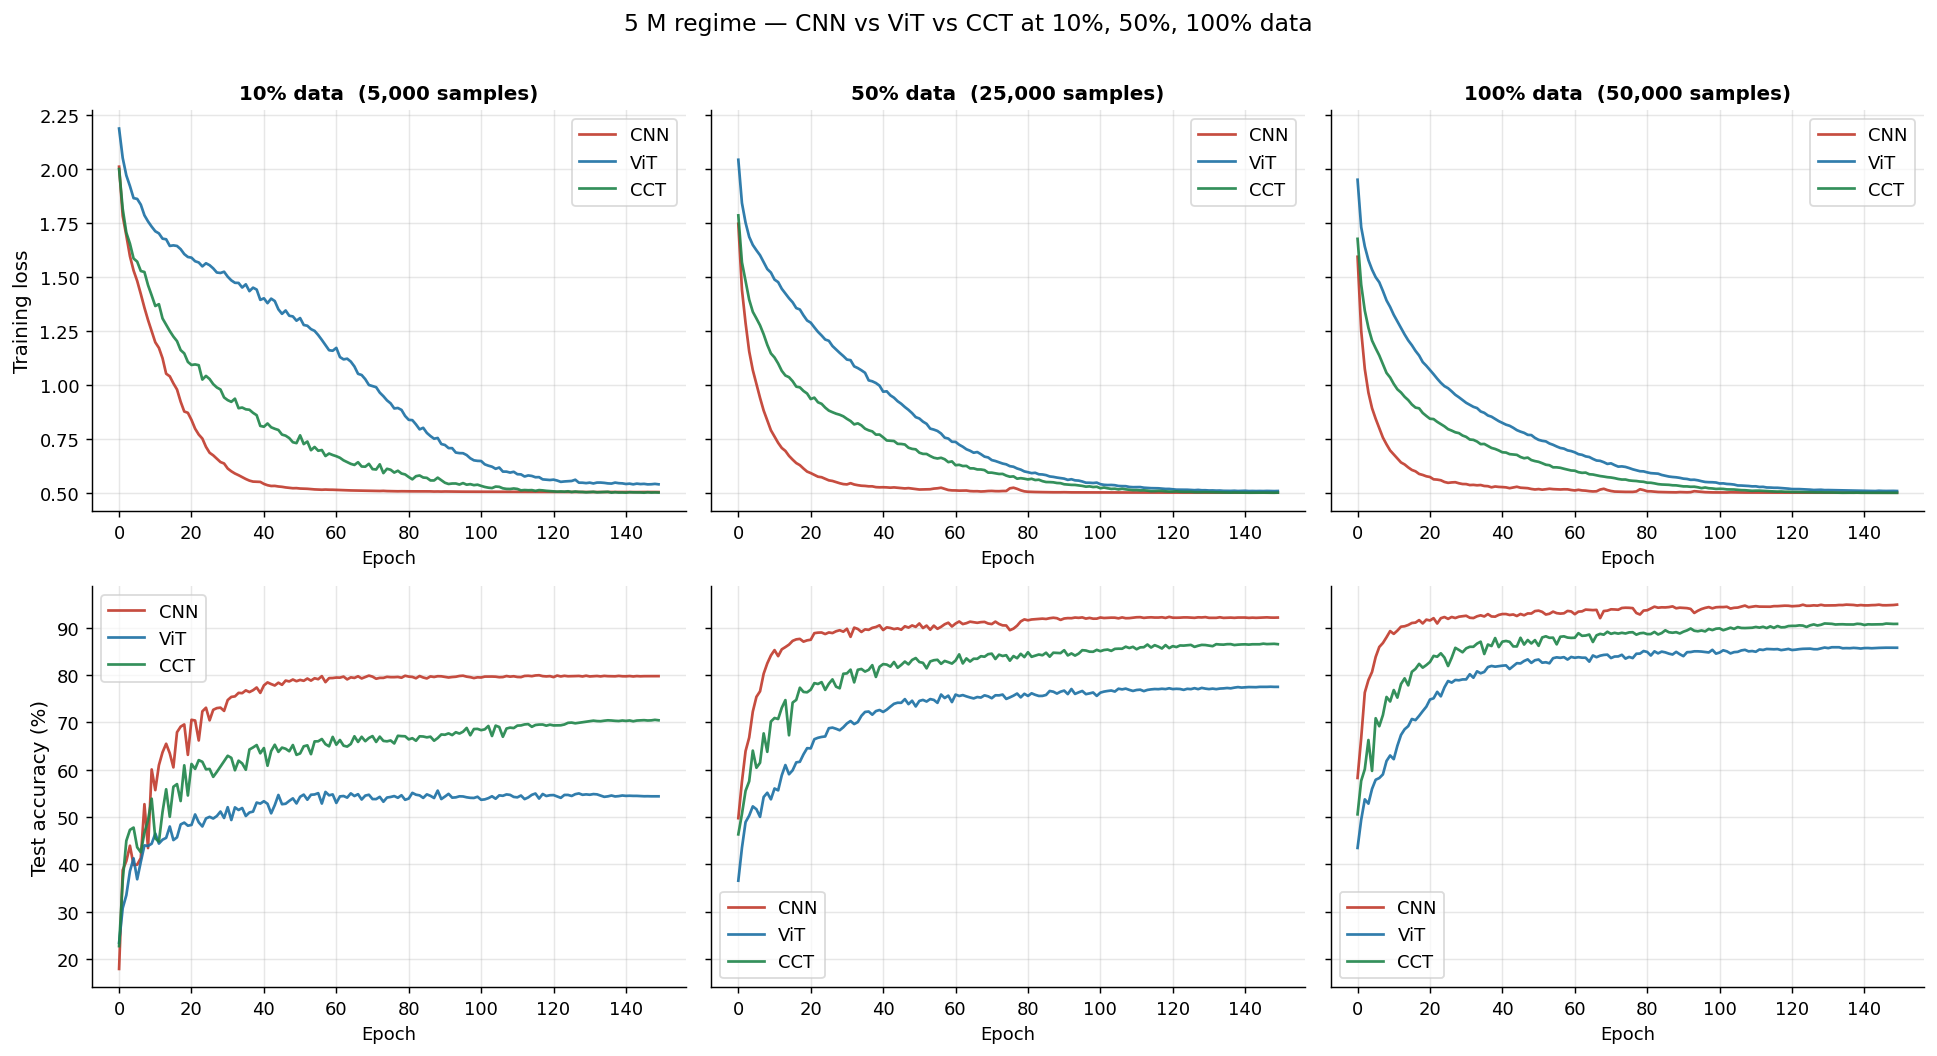

In [14]:
# ── Cross-architecture comparison at 5 M, key fractions ───────────────────────
KEY_FRACS = [0.1, 0.5, 1.0]
fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharey='row')

for col, frac in enumerate(KEY_FRACS):
    ax_loss, ax_acc = axes[0, col], axes[1, col]
    title = f'{int(frac*100)}% data  ({int(N_TRAIN*frac):,} samples)'

    for model in LARGE_MODELS:
        ep = epochs(model, frac)
        ax_loss.plot(ep, train_loss(model, frac), color=COLORS[model],
                     linewidth=1.5, label=DISPLAY[model], alpha=0.9)
        ax_acc.plot( ep, test_acc(model, frac),   color=COLORS[model],
                     linewidth=1.5, label=DISPLAY[model], alpha=0.9)

    ax_loss.set_title(title, fontsize=11, fontweight='bold')
    ax_loss.legend(fontsize=10, framealpha=0.7)
    ax_acc.legend( fontsize=10, framealpha=0.7)
    ax_loss.set_xlabel('Epoch', fontsize=10)
    ax_acc.set_xlabel('Epoch', fontsize=10)

axes[0, 0].set_ylabel('Training loss', fontsize=11)
axes[1, 0].set_ylabel('Test accuracy (%)', fontsize=11)

fig.suptitle('5 M regime — CNN vs ViT vs CCT at 10%, 50%, 100% data', fontsize=13, y=1.01)
plt.tight_layout()
plt.savefig('fig4_lc_cross_5M.pdf', bbox_inches='tight')
plt.show()

Left: **final training loss by data fraction** — lower means the model fit the training set more tightly.   
Right: **generalisation gap** (best validation accuracy minus final validation accuracy) — larger values indicate late-epoch instability or overfitting.

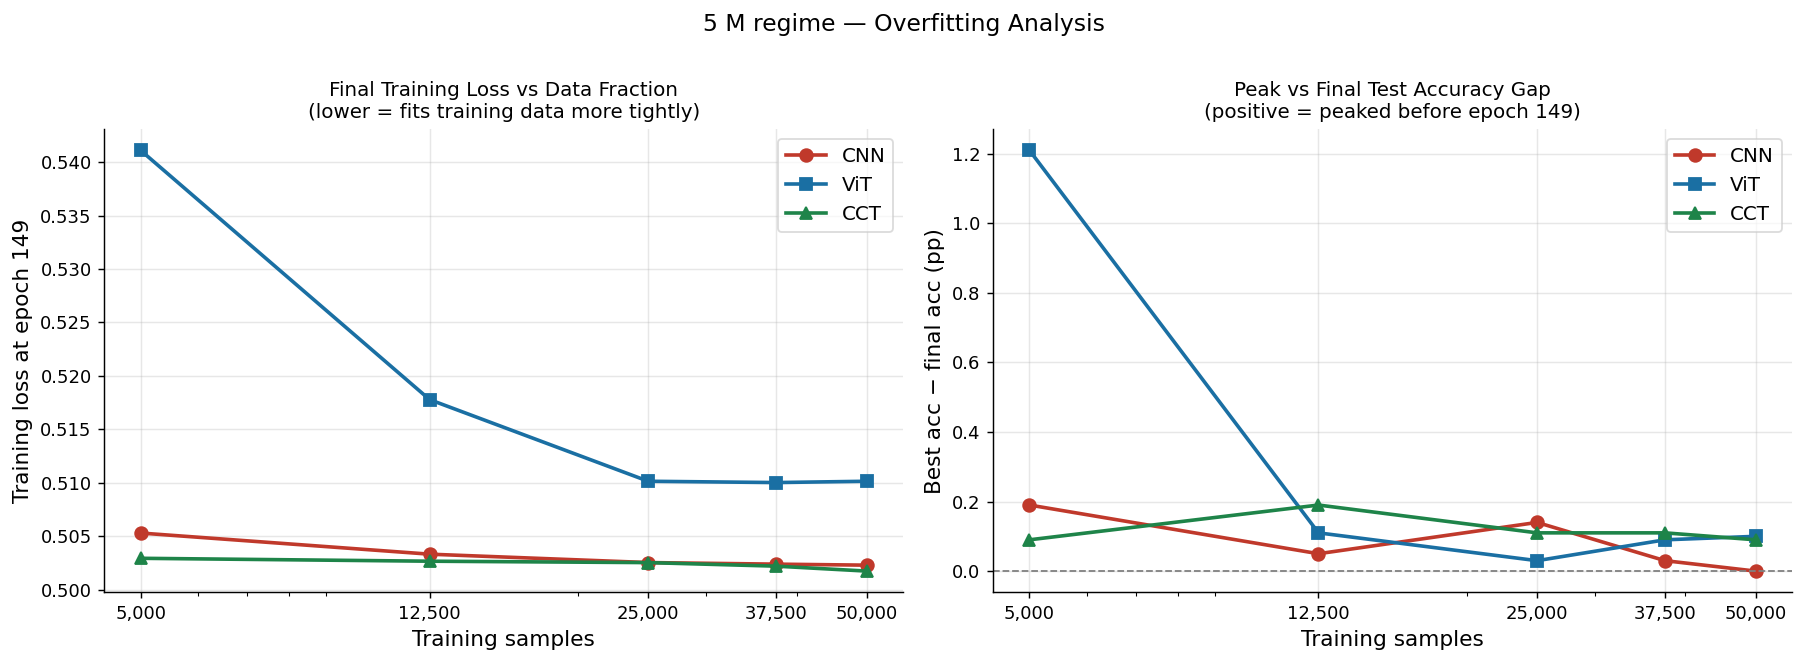

In [15]:
# ── Overfitting analysis at 5 M ───────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax = axes[0]
for model in LARGE_MODELS:
    final_losses = [results[model][f][-1]['loss'] for f in FRACTIONS]
    ax.plot(SAMPLES, final_losses, color=COLORS[model], marker=MARKERS[model],
            linewidth=2, markersize=7, label=DISPLAY[model])
ax.set_xscale('log')
ax.set_xticks(SAMPLES)
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{int(x):,}'))
ax.set_xlabel('Training samples', fontsize=12)
ax.set_ylabel('Training loss at epoch 149', fontsize=12)
ax.set_title('Final Training Loss vs Data Fraction\n(lower = fits training data more tightly)', fontsize=11)
ax.legend(fontsize=11, framealpha=0.7)

ax = axes[1]
for model in LARGE_MODELS:
    gaps = [best_acc(model, f) - final_acc(model, f) for f in FRACTIONS]
    ax.plot(SAMPLES, gaps, color=COLORS[model], marker=MARKERS[model],
            linewidth=2, markersize=7, label=DISPLAY[model])
ax.axhline(0, color='gray', linewidth=1.0, linestyle='--')
ax.set_xscale('log')
ax.set_xticks(SAMPLES)
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{int(x):,}'))
ax.set_xlabel('Training samples', fontsize=12)
ax.set_ylabel('Best acc − final acc (pp)', fontsize=12)
ax.set_title('Peak vs Final Test Accuracy Gap\n(positive = peaked before epoch 149)', fontsize=11)
ax.legend(fontsize=11, framealpha=0.7)

fig.suptitle('5 M regime — Overfitting Analysis', fontsize=13, y=1.01)
plt.tight_layout()
plt.savefig('fig5_overfit_5M.pdf', bbox_inches='tight')
plt.show()

### Interpretation — Primary Regime — Accuracy & Convergence (5 M)

The primary analysis confirms that $inductive$ $bias$ has a measurable and sustained impact on sample efficiency at this parameter scale. The CNN's advantage is not restricted to the most extreme low-data conditions — it holds across every data fraction tested, and the performance ordering between architectures remains stable throughout. What changes with more data is not the ranking but the $magnitude$ of the gap: the ViT closes in gradually, demonstrating that data can compensate — at least partially — for the absence of spatial priors.

What the curves also reveal is that the $CCT's$ $hybrid$ $design$ has a meaningful effect. By injecting locality through its convolutional tokenizer, the CCT avoids the ViT's steep low-data penalty while retaining the attention mechanism for flexible feature integration. The result is a model that follows the CNN more closely than the ViT across all conditions — evidence that the choice of tokenizer is not a minor implementation detail but a substantive architectural decision with real performance consequences.

The $learning$ $dynamics$ add an important dimension to this picture. The CNN stabilises early and does not gain much from prolonged training; the ViT, lacking spatial guidance, requires far more epochs to extract useful structure and its trajectory is noisier, especially at low data fractions. The CCT occupies an intermediate position: its attention layers benefit from the stable early representation delivered by the convolutional tokenizer, converging faster than the ViT and more smoothly.

Crucially, the $overfitting$ $analysis$ rules out a competing explanation: the performance differences across architectures are not driven by differences in capacity or regularisation. All three models show comparable generalisation gaps, and none exhibits severe overfitting. The observed accuracy ordering is genuinely a consequence of how efficiently each architecture extracts signal from limited examples — not of how well it avoids fitting noise.


---
## Representational Similarity — Centered Kernel Alignment (CKA)
---

*(Kornblith et al., ICML 2019; Raghu et al., NeurIPS 2021)*

### Why CKA?

A natural question beyond accuracy is: **do these architectures learn similar internal representations?**
Accuracy alone cannot tell us this. Two models could both reach 85 % on CIFAR-10 while organising their internal representations in completely different ways — one relying on local texture, the other on global shape. Knowing *how* a model represents the world matters for understanding why it succeeds or fails when data are scarce.

This is more useful than asking whether the raw activation values match: two layers can produce very different activation values while still encoding the same information (e.g., one might be a rotated or scaled version of the other). CKA is invariant to such transformations.

---

### Mathematical definition

Given two representation matrices $\mathbf{X} \in \mathbb{R}^{n \times p}$ and $\mathbf{Y} \in \mathbb{R}^{n \times q}$ (n images, p and q neurons), linear CKA is defined as:

$$\text{CKA}(\mathbf{X}, \mathbf{Y}) = \frac{\|\mathbf{Y}^\top \mathbf{X}\|_F^2}{\|\mathbf{X}^\top \mathbf{X}\|_F \, \|\mathbf{Y}^\top \mathbf{Y}\|_F}$$

CKA is invariant to orthogonal transformations and isotropic scaling, making it suitable for comparing representations across architectures with different widths.

- **CKA close to 1** → the two layers organise images in the same way: they are learning the same "concept", regardless of the specific neuron values.
- **CKA close to 0** → the two layers structure information differently: each has learned to extract distinct features.

---

### What we measure

| Mode | What it reveals |
|----|----|
| **Within-model CKA** (layer $i$ vs. layer $j$ of the same model) | How much representations change with depth. A high score between distant layers means the network reuses the same representation without further specialisation — a sign of redundancy or data starvation. |
| **Cross-architecture CKA** (CNN layer vs. ViT/CCT layer) | Whether different architectures converge to similar solutions. High similarity suggests inductive bias matters less than expected; low similarity confirms that architectures build fundamentally different representations. |
| **Cross-fraction CKA** (same model, different data amounts) | How much extra data shifts what the network learns. A large shift indicates the model was genuinely learning new structure; a small shift suggests the network saturated early. |

### Probed layers

| Model | Probed layers |
|-------|--------------|
| CNN_small | After each MaxPool (×3) |
| CNN_large | After each residual stage (×3) |
| ViT_small / ViT_large | Output of each Transformer block |
| CCT_small / CCT_large | Output of each Transformer block |


In [16]:
# ── Pre-trained model loader ──────────────────────────────────────────────────
def load_model(model_name: str, frac: float):
    model = MODEL_CLASSES[model_name]()
    pt_file = PT_DIR / f'{model_name}_seed{SEED}_frac{frac}.pt'
    state_dict = torch.load(pt_file, map_location=device, weights_only=True)
    model.load_state_dict(state_dict)
    model.eval()
    return model.to(device)

# ── Test loader (no augmentation) ─────────────────────────────────────────────
test_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.4914, 0.4822, 0.4465), (0.2023, 0.1994, 0.2010)),
])
test_dataset = datasets.CIFAR10(root='./dataset', train=False,
                                 download=False, transform=test_transform)
test_loader  = DataLoader(test_dataset, batch_size=256, shuffle=False, num_workers=0)

# ── Linear CKA ───────────────────────────────────────────────────────────────
def linear_cka(X: torch.Tensor, Y: torch.Tensor) -> float:
    X = X - X.mean(0); Y = Y - Y.mean(0)
    XXT = X @ X.T;     YYT = Y @ Y.T
    num = (XXT * YYT).sum()
    den = (XXT * XXT).sum().sqrt() * (YYT * YYT).sum().sqrt()
    return (num / den).item()

# ── Hook-based representation extractor ──────────────────────────────────────
def get_reps(model, loader, layers: list, max_batches: int = 6) -> list:
    buffers = [[] for _ in layers]
    handles = []
    for buf, layer in zip(buffers, layers):
        def _hook(m, inp, out, b=buf):
            val = out[0] if isinstance(out, tuple) else out
            b.append(val.detach().cpu())
        handles.append(layer.register_forward_hook(_hook))
    model.eval()
    with torch.no_grad():
        for i, (x, _) in enumerate(loader):
            if i >= max_batches:
                break
            model(x.to(device))
    for h in handles:
        h.remove()
    return [torch.cat(b, dim=0).flatten(1) for b in buffers]

# ── Per-architecture layer hooks ──────────────────────────────────────────────
def get_internal_layers(model, model_name: str) -> list:
    if model_name == 'cnn_small':
        return [model.features[3], model.features[7], model.features[11]]   # after each MaxPool
    if model_name == 'cnn_large':
        return [model.layer1, model.layer2, model.layer3]                    # 3 residual stages
    if model_name in ('vit_small', 'vit_large'):
        return list(model.layers)                                            # transformer blocks
    if model_name in ('cct_small', 'cct_large'):
        return list(model.transformer.layers)                                # encoder layers
    return []

def get_final_rep_layer(model, model_name: str):
    if model_name == 'cnn_small':
        return model.classifier[2]   # ReLU output (96-d)
    if model_name == 'cnn_large':
        return model.head[1]         # Flatten output (320-d)
    if model_name in ('vit_small', 'vit_large'):
        return model.head[0]         # LayerNorm on CLS token
    if model_name in ('cct_small', 'cct_large'):
        return model.norm            # LayerNorm after transformer
    return None

print('CKA utilities ready.')

CKA utilities ready.


/opt/anaconda3/envs/project13/lib/python3.11/site-packages/torchvision/datasets/cifar.py:83: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  entry = pickle.load(f, encoding="latin1")


**Within-model CKA heatmaps**: each cell $(i, j)$ is the representational similarity between layer $i$
and layer $j$ of the same model. Block structure indicates reuse of representations across depth;
a diagonal stripe indicates rapid representation change layer by layer.

/opt/anaconda3/envs/project13/lib/python3.11/site-packages/torch/nn/modules/transformer.py:379: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  warnings.warn(
/opt/anaconda3/envs/project13/lib/python3.11/site-packages/torch/nn/modules/transformer.py:379: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  warnings.warn(
/opt/anaconda3/envs/project13/lib/python3.11/site-packages/torch/nn/modules/transformer.py:379: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  warnings.warn(
/opt/anaconda3/envs/project13/lib/python3.11/site-packages/torch/nn/modules/transformer.py:379: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  warnings.warn(
/opt/anaconda3/envs/project13/lib/python3.11/site-packages/torch

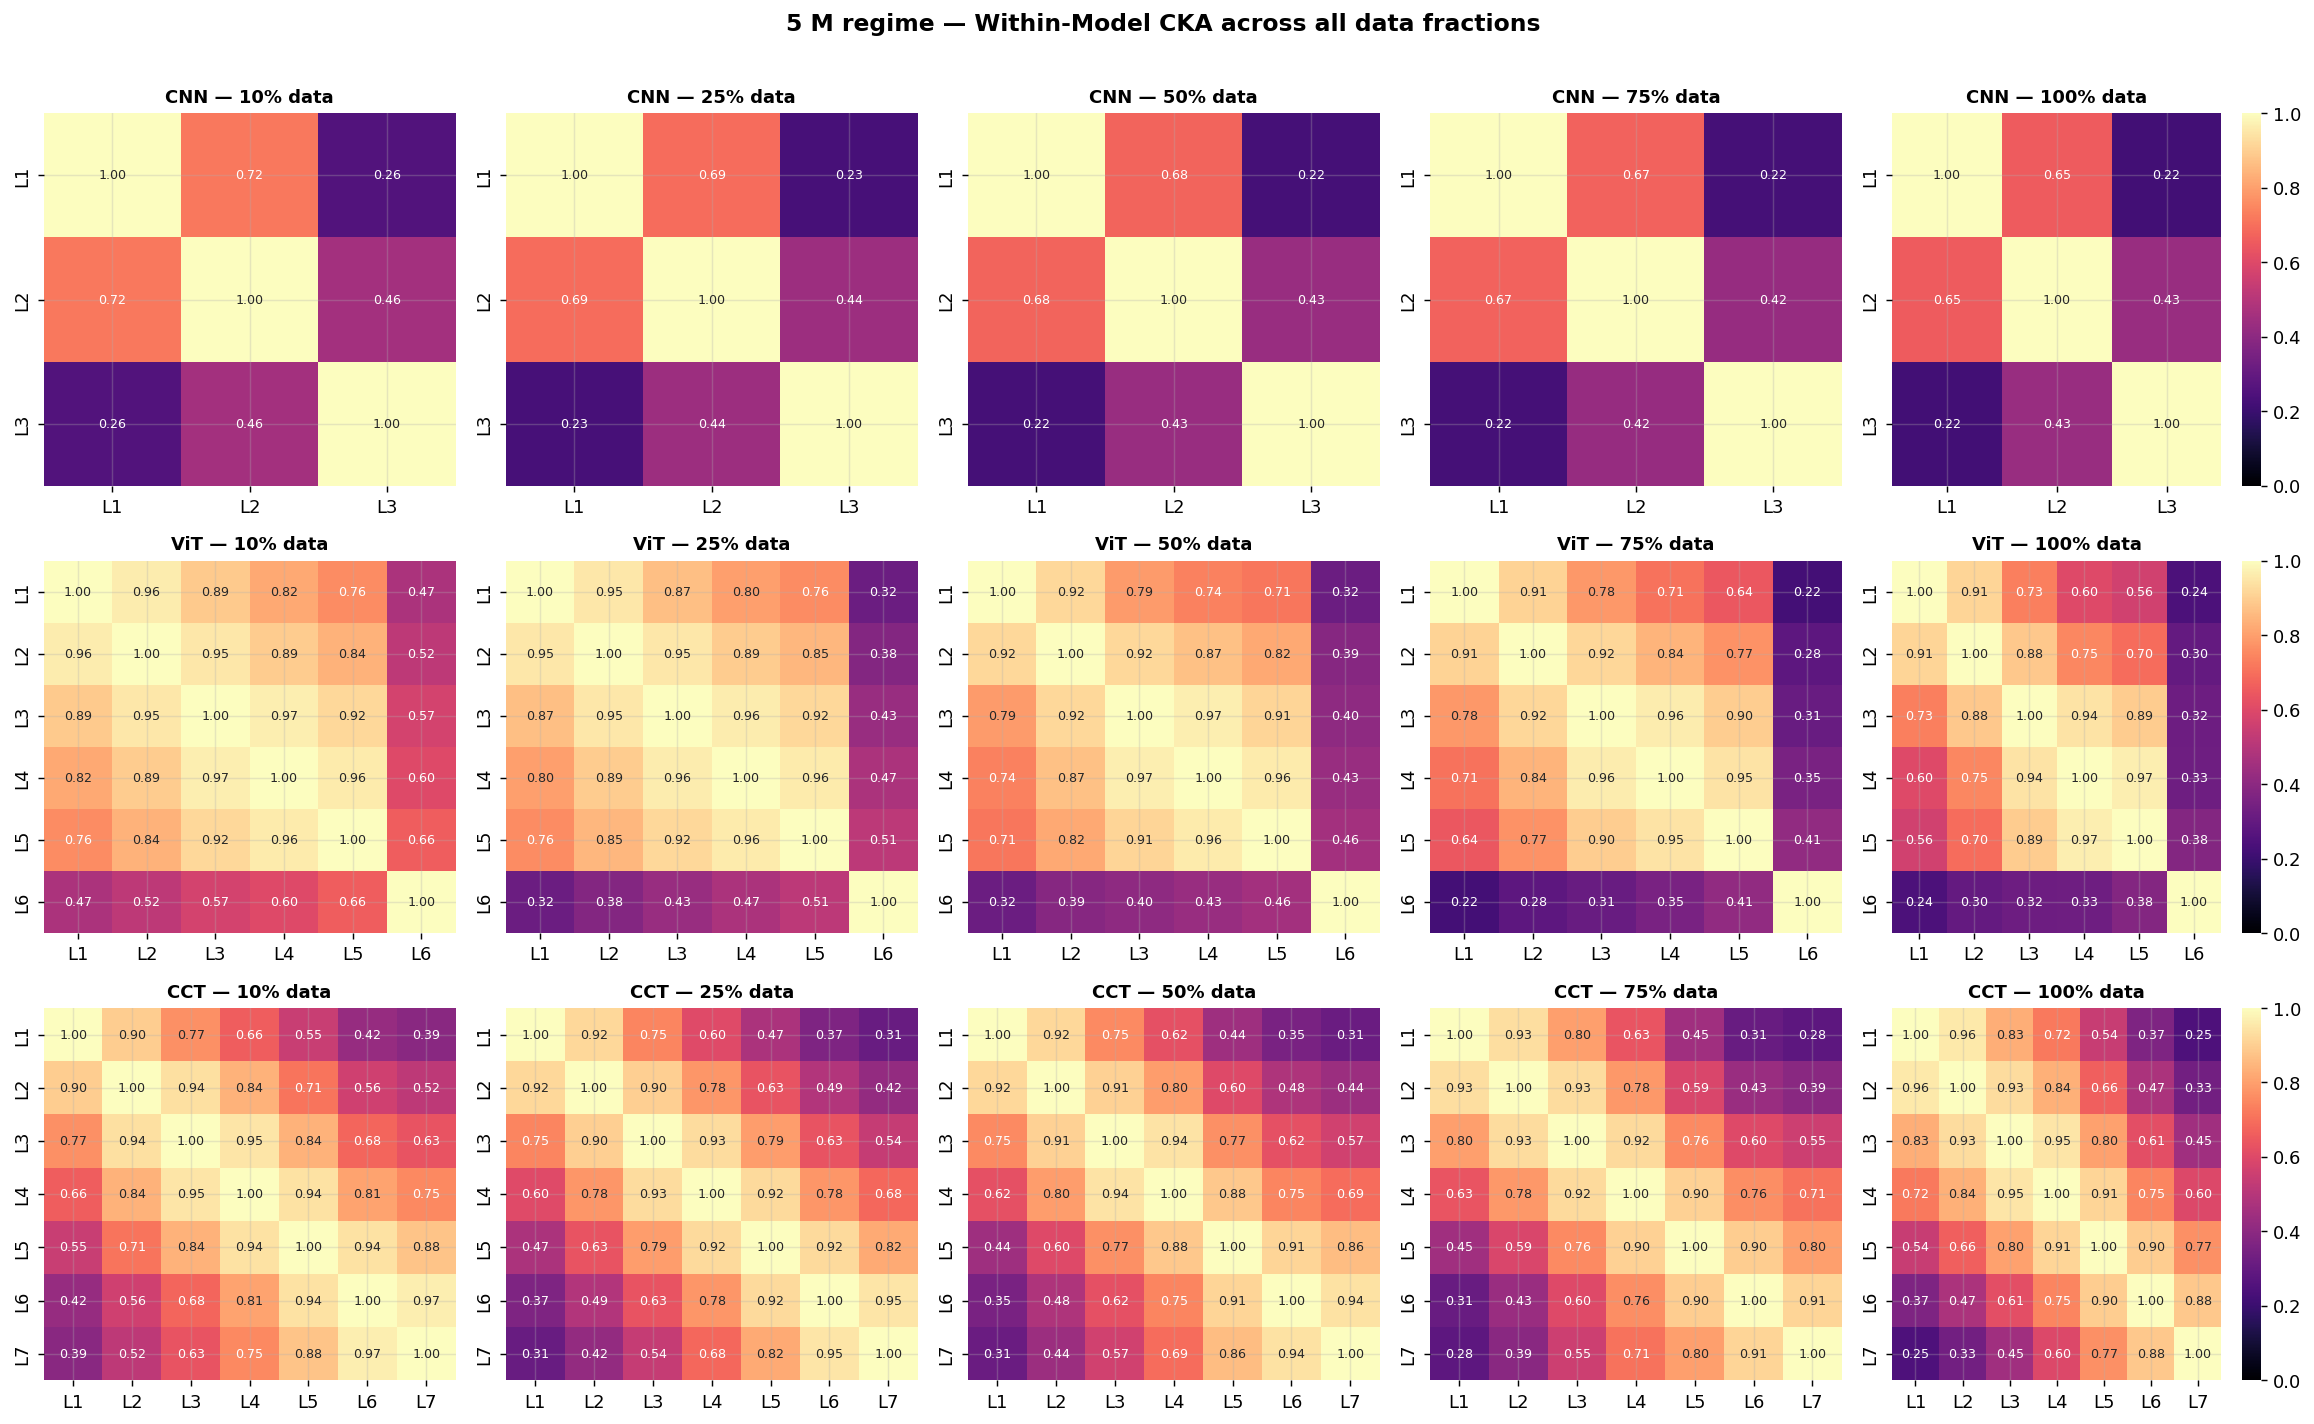

In [17]:
# ── Within-model CKA at 5 M — layers × layers per model, ALL fractions ───────
fig, axes = plt.subplots(len(LARGE_MODELS), len(FRACTIONS),
                         figsize=(3.6 * len(FRACTIONS), 3.6 * len(LARGE_MODELS)))

for row, model_name in enumerate(LARGE_MODELS):
    for col, frac in enumerate(FRACTIONS):
        ax = axes[row, col]
        model  = load_model(model_name, frac)
        layers = get_internal_layers(model, model_name)
        reps   = get_reps(model, test_loader, layers, max_batches=6)

        n   = len(reps)
        mat = np.zeros((n, n))
        for i in range(n):
            for j in range(n):
                mat[i, j] = linear_cka(reps[i], reps[j])

        lbls = [f'L{i+1}' for i in range(n)]
        sns.heatmap(mat, ax=ax, vmin=0, vmax=1, cmap='magma',
                    annot=True, fmt='.2f', xticklabels=lbls, yticklabels=lbls,
                    cbar=(col == len(FRACTIONS) - 1), annot_kws={'size': 7})
        ax.set_title(f'{DISPLAY[model_name]} — {int(frac*100)}% data',
                     fontsize=10, fontweight='bold')
        del model
        torch.cuda.empty_cache() if torch.cuda.is_available() else None

fig.suptitle('5 M regime — Within-Model CKA across all data fractions',
             fontsize=13, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('fig6_cka_within_5M.pdf', bbox_inches='tight')
plt.show()


**Cross-architecture CKA matrices**: each cell measures how similar the representation at layer $i$
of model $\mathcal A$ is to layer $i$ of model $\mathcal B$. High off-diagonal similarity suggests the two architectures
converge to similar solutions despite different inductive biases.

/opt/anaconda3/envs/project13/lib/python3.11/site-packages/torch/nn/modules/transformer.py:379: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  warnings.warn(


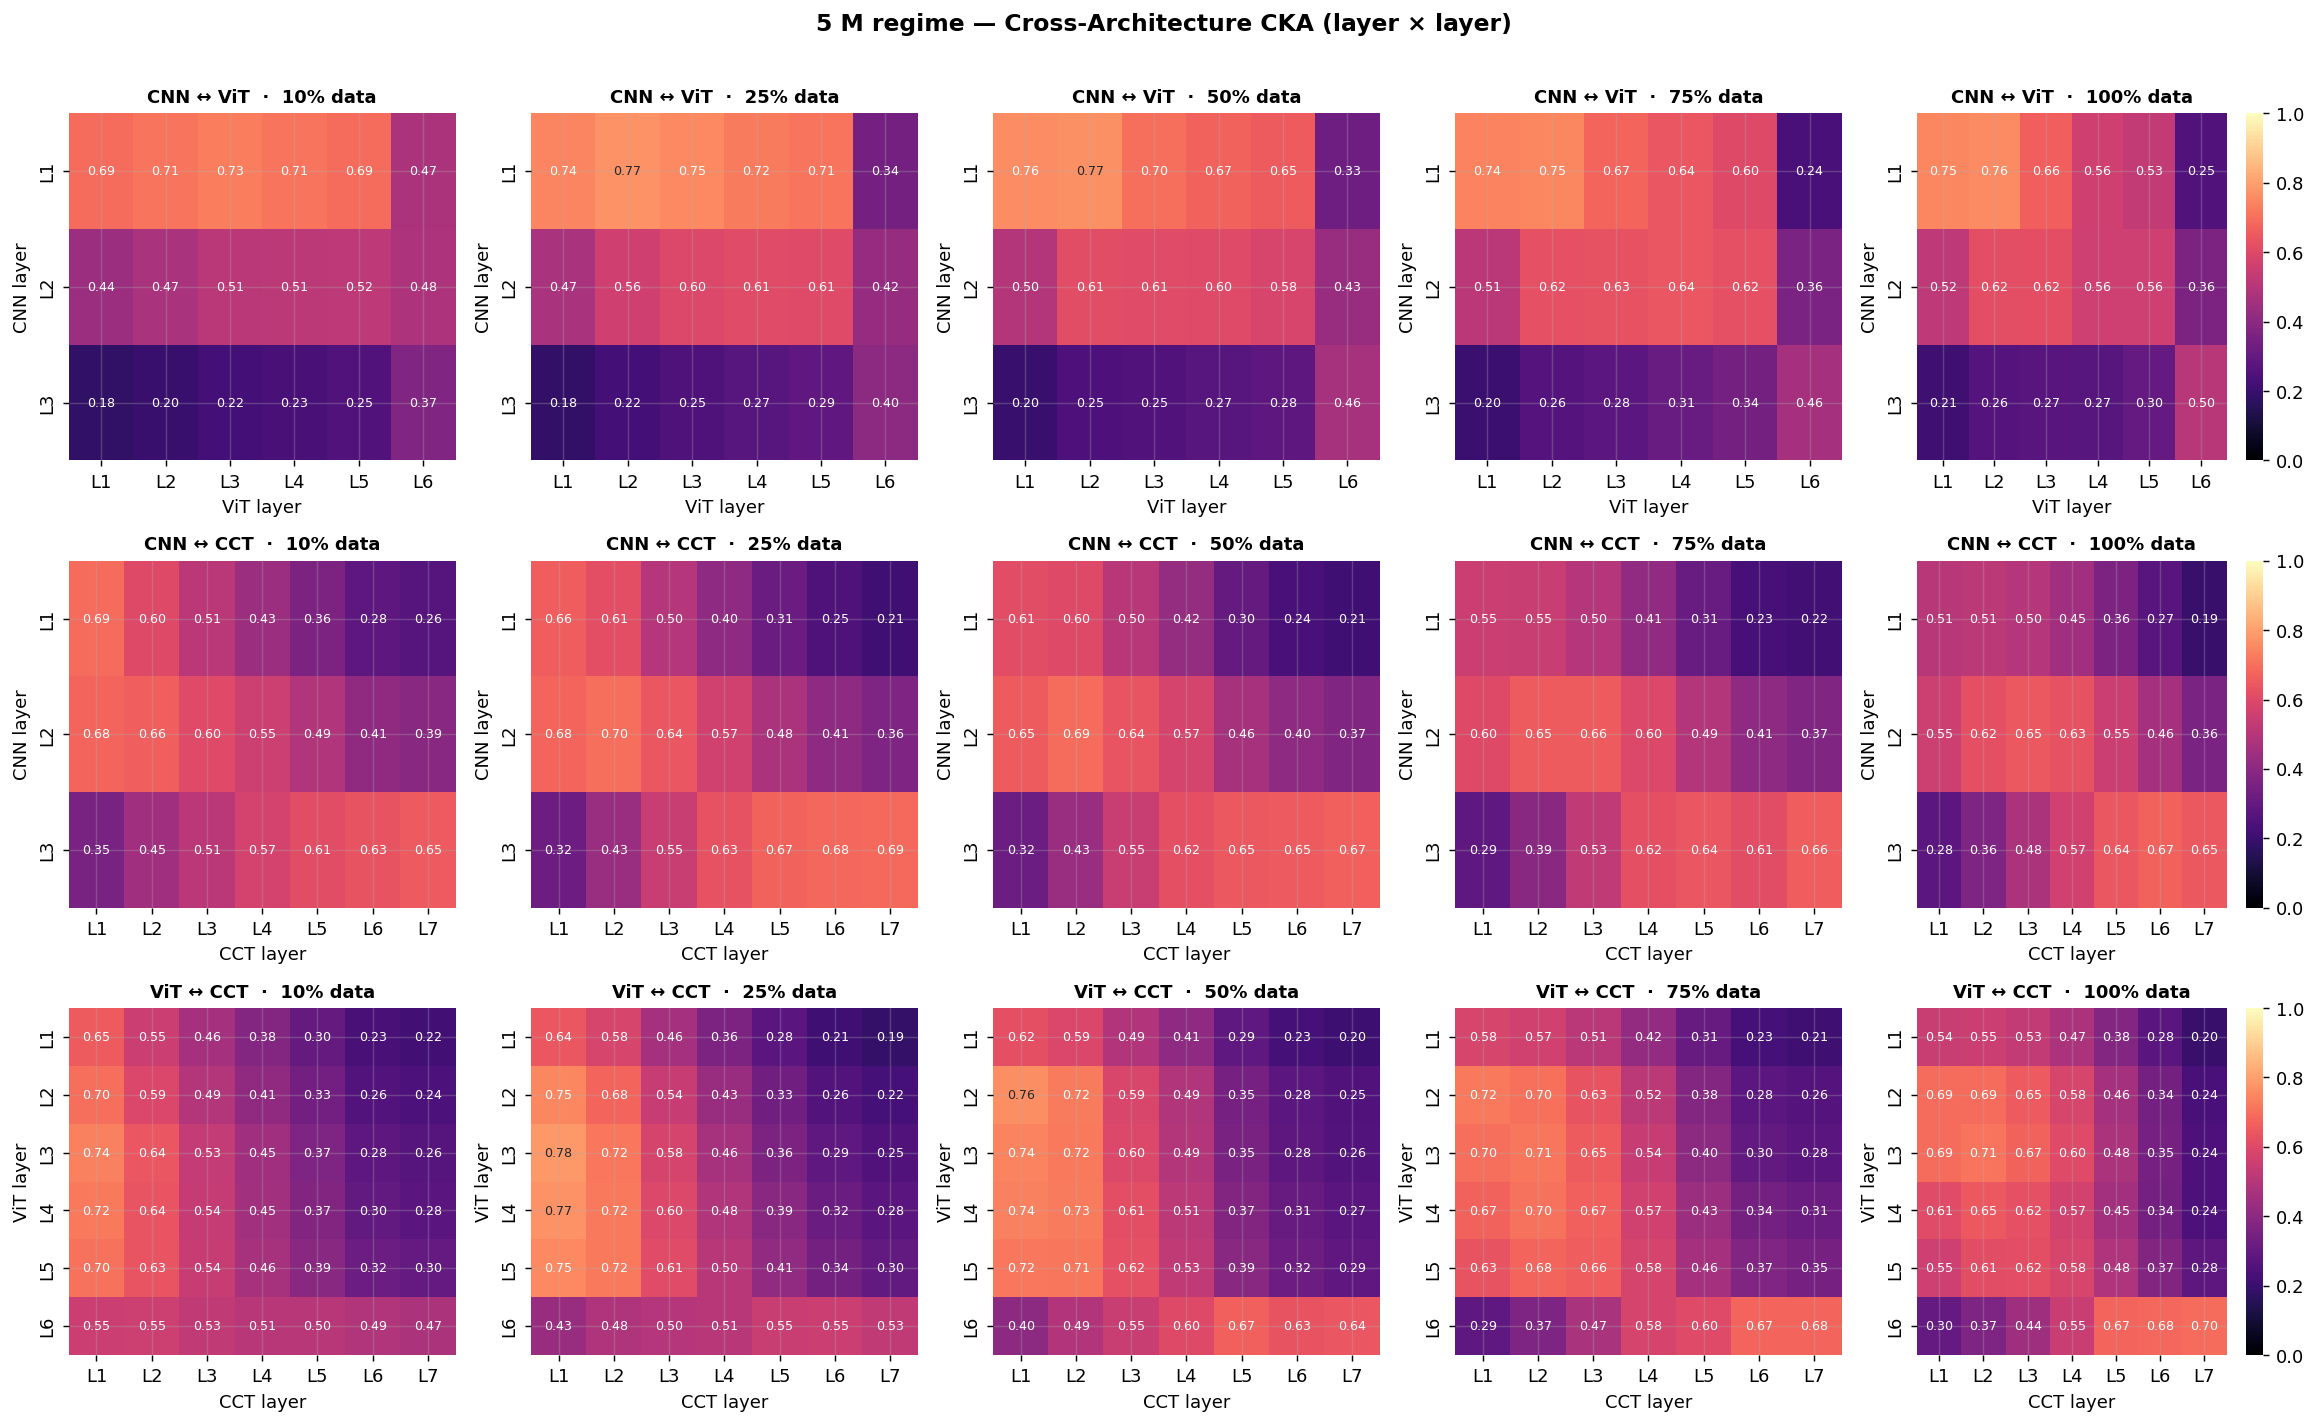

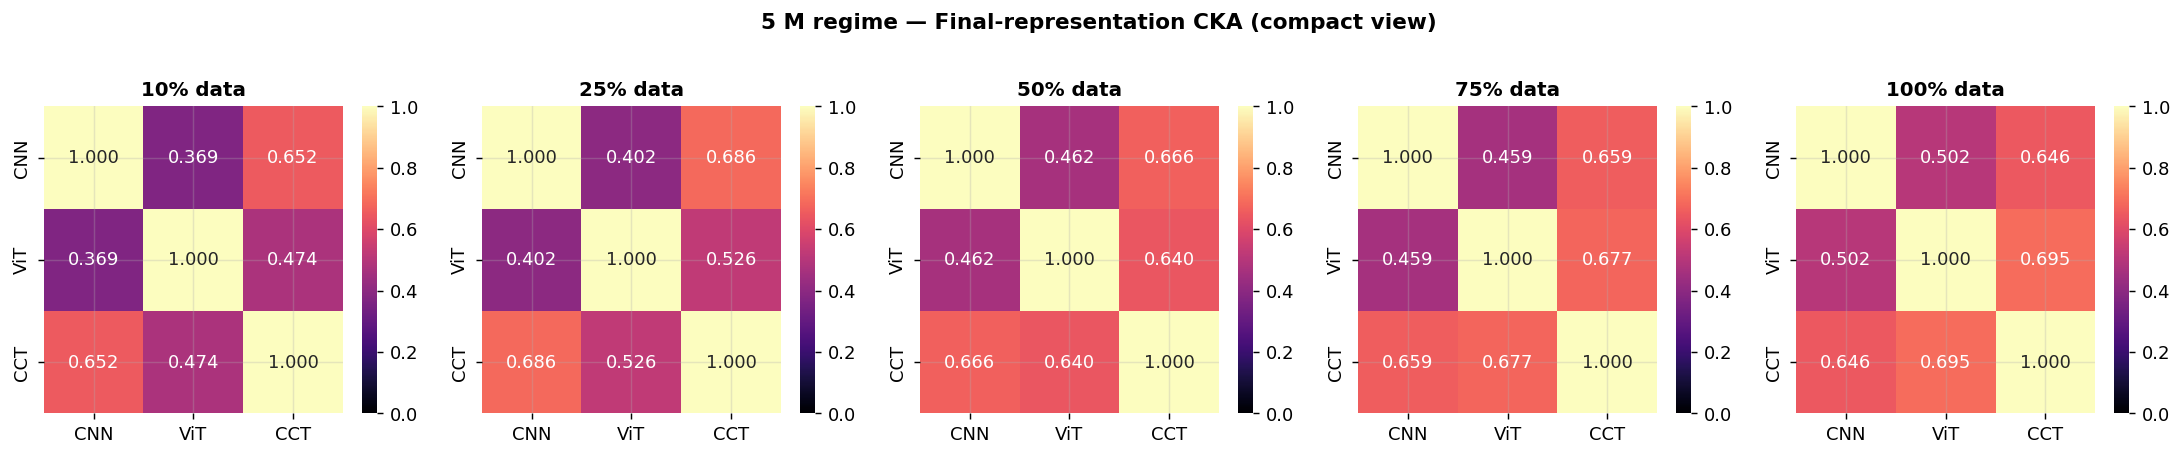

In [18]:

# ── Cross-architecture CKA at 5 M — layer × layer between architectures ──────
# For each pair of architectures we extract internal-layer activations and
# compute a full layer×layer CKA matrix (rows = arch A layers, cols = arch B
# layers), repeated for every data fraction.

def collect_layer_reps(model_name, frac):
    model = load_model(model_name, frac)
    layers = get_internal_layers(model, model_name)
    reps   = get_reps(model, test_loader, layers, max_batches=6)
    del model
    if torch.cuda.is_available(): torch.cuda.empty_cache()
    return reps

PAIRS_L = [('cnn_large', 'vit_large'),
           ('cnn_large', 'cct_large'),
           ('vit_large', 'cct_large')]

# Pre-compute per-fraction reps once per model to save compute
reps_by_frac_L = {f: {m: collect_layer_reps(m, f) for m in LARGE_MODELS}
                  for f in FRACTIONS}

fig, axes = plt.subplots(len(PAIRS_L), len(FRACTIONS),
                         figsize=(3.6 * len(FRACTIONS), 3.6 * len(PAIRS_L)))

for row, (mA, mB) in enumerate(PAIRS_L):
    for col, frac in enumerate(FRACTIONS):
        ax = axes[row, col]
        rA = reps_by_frac_L[frac][mA]
        rB = reps_by_frac_L[frac][mB]
        mat = np.zeros((len(rA), len(rB)))
        for i, x in enumerate(rA):
            for j, y in enumerate(rB):
                mat[i, j] = linear_cka(x, y)
        xlbls = [f'L{j+1}' for j in range(len(rB))]
        ylbls = [f'L{i+1}' for i in range(len(rA))]
        sns.heatmap(mat, ax=ax, vmin=0, vmax=1, cmap='magma',
                    annot=True, fmt='.2f', xticklabels=xlbls, yticklabels=ylbls,
                    cbar=(col == len(FRACTIONS) - 1), annot_kws={'size': 7})
        ax.set_xlabel(f'{DISPLAY[mB]} layer'); ax.set_ylabel(f'{DISPLAY[mA]} layer')
        ax.set_title(f'{DISPLAY[mA]} ↔ {DISPLAY[mB]}  ·  {int(frac*100)}% data',
                     fontsize=10, fontweight='bold')

fig.suptitle('5 M regime — Cross-Architecture CKA (layer × layer)',
             fontsize=13, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('fig7_cka_cross_5M.pdf', bbox_inches='tight')
plt.show()

# ── Compact summary: final-representation CKA between architectures ──────────
fig, axes = plt.subplots(1, len(FRACTIONS), figsize=(3.4 * len(FRACTIONS), 3.4))
lbls = [DISPLAY[m] for m in LARGE_MODELS]

for ax, frac in zip(axes, FRACTIONS):
    mat = np.zeros((3, 3))
    for i, mi in enumerate(LARGE_MODELS):
        for j, mj in enumerate(LARGE_MODELS):
            # use the LAST internal layer activation as the "final representation"
            mat[i, j] = linear_cka(reps_by_frac_L[frac][mi][-1],
                                   reps_by_frac_L[frac][mj][-1])
    sns.heatmap(mat, ax=ax, vmin=0, vmax=1, cmap='magma',
                annot=True, fmt='.3f', xticklabels=lbls, yticklabels=lbls)
    ax.set_title(f'{int(frac*100)}% data', fontsize=11, fontweight='bold')

fig.suptitle('5 M regime — Final-representation CKA (compact view)',
             fontsize=12, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


---
### Interpretation — CKA — Representational Similarity (5 M)
The CKA analysis reveals that the three architectures not only achieve different accuracy levels — they build $internal$ $representations$ in fundamentally different ways, and these differences persist even as data grows.

The CNN's representation evolves most substantially across its $processing$ $stages$. While adjacent layers remain geometrically close — each stage refines the representation incrementally — the first and last stages are considerably dissimilar, confirming genuine feature specialisation: what the CNN encodes in its early layers is meaningfully different from what it produces at the end. This is the hallmark of $hierarchical$, $progressive$ $feature$ $extraction$.

The ViT's profile is qualitatively different. Its intermediate blocks produce representations that cluster tightly together in similarity space, with the most pronounced transformation reserved for the final layer. This pattern suggests that the $ViT's$ $depth$ $is$ $not$ $being$ $used$ $efficiently$: the middle blocks largely preserve and forward representations rather than transform them — a consequence of having no architectural guidance about how features should evolve with depth.

The CCT's behaviour is intermediate in a meaningful sense. Its early layers bear a closer resemblance to the CNN, reflecting the convolutional tokenizer's influence; as depth increases and the transformer blocks dominate, the representation takes on the more uniform character typical of self-attention processing.

The cross-architecture view adds a further nuance: the CNN-CCT final-representation similarity is notably higher than the CNN-ViT similarity across all data fractions, and it remains stable even as training data grows. The ViT-CCT similarity, by contrast, increases substantially with data — suggesting that the shared transformer backbone creates an affinity between ViT and CCT that data can amplify, while the CNN's fundamentally different processing pathway keeps it structurally distinct from both Transformer-based models.


---
# 6 · Secondary Analysis — ~0.75 M Parameters
---
## CNN vs. CCT in the Low-Capacity Regime

At ~0.75 M parameters the vanilla ViT is effectively out of its element: without any locality
prior it cannot make efficient use of so few weights, and the deficit compounds as training
data shrink. The informative comparison here is **CNN vs. CCT** — both carry an explicit
locality bias (the CCT through its convolutional tokenizer), so any performance gap between
them isolates the value of **global attention** over pure convolution, at the scale where
that trade-off actually matters. The ViT is included for reference, but its results should
be read as a lower bound on what attention alone can achieve at this capacity.

### Reading Guide: 0.75M Regime (CNN vs. CCT)

*   **Accuracy Gap (CNN − CCT)**: we anticipate a slight initial performance advantage for the CNN, which is expected to diminish or potentially invert as the volume of available data increases. The CCT should outperform the CNN at higher data fractions.
*   **Learning Curve Dynamics**: the CCT may exhibit slower initial convergence compared to the CNN under extreme data scarcity, yet it often achieves a superior final plateau. This behavior reflects the period required for the attention layers to begin effectively extracting global relationships from the local features provided by the convolutional tokenizer.
*   **Within-Model CKA (Representational Hierarchy)**: both the CNN and the CCT are expected to demonstrate distinct layer-wise hierarchies. In the CCT, a "flat" matrix characterized by high inter-layer similarity would indicate a lack of specialization in the Transformer blocks—a classic hallmark of data starvation rather than a limitation in model capacity.
*   **Cross-Architecture CKA**: a high degree of representational similarity between the CNN and CCT at low data fractions is considered a functional characteristic of the architecture. It suggests that the CCT’s convolutional tokenizer is performing the primary feature extraction. As data scales, the CCT’s representation should progressively diverge from the CNN's as the self-attention mechanism begins to contribute unique global priors.

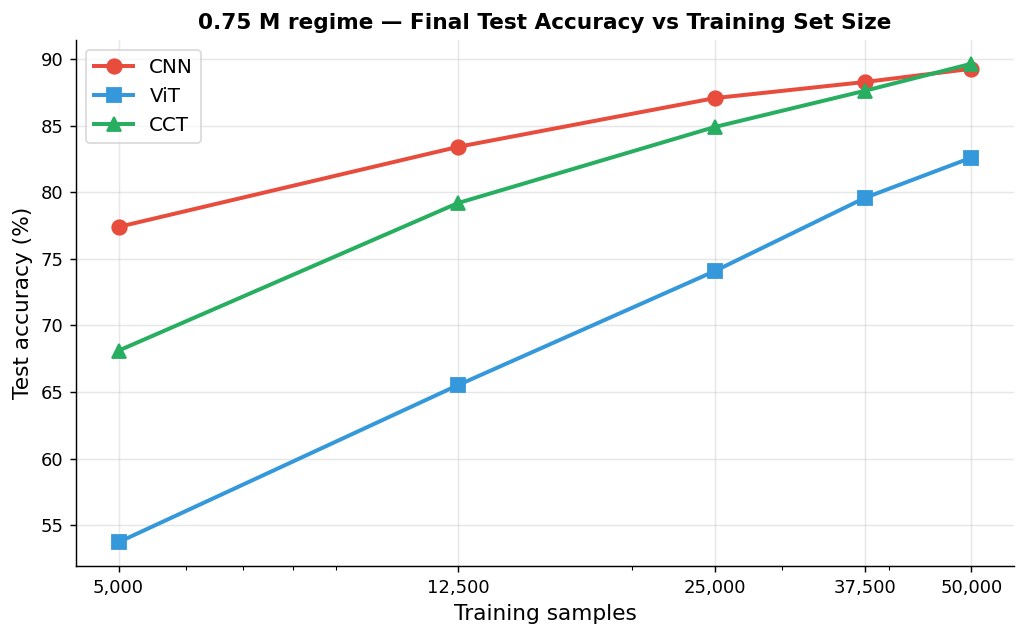

In [19]:
# ── Final test accuracy vs data fraction — small (0.75M) regime ───────────────
fig, ax = plt.subplots(figsize=(8, 5))

for model in SMALL_MODELS:
    accs = [final_acc(model, f) for f in FRACTIONS]
    ax.plot(SAMPLES, accs, color=COLORS[model], marker=MARKERS[model],
            linewidth=2.2, markersize=8, label=DISPLAY[model])

ax.set_xscale('log')
ax.set_xticks(SAMPLES)
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{int(x):,}'))
ax.set_xlabel('Training samples', fontsize=12)
ax.set_ylabel('Test accuracy (%)', fontsize=12)
ax.set_title('0.75 M regime — Final Test Accuracy vs Training Set Size', fontsize=12, fontweight='bold')
ax.legend(fontsize=11, framealpha=0.7)
plt.tight_layout()
plt.savefig('fig8_acc_075M.pdf', bbox_inches='tight')
plt.show()

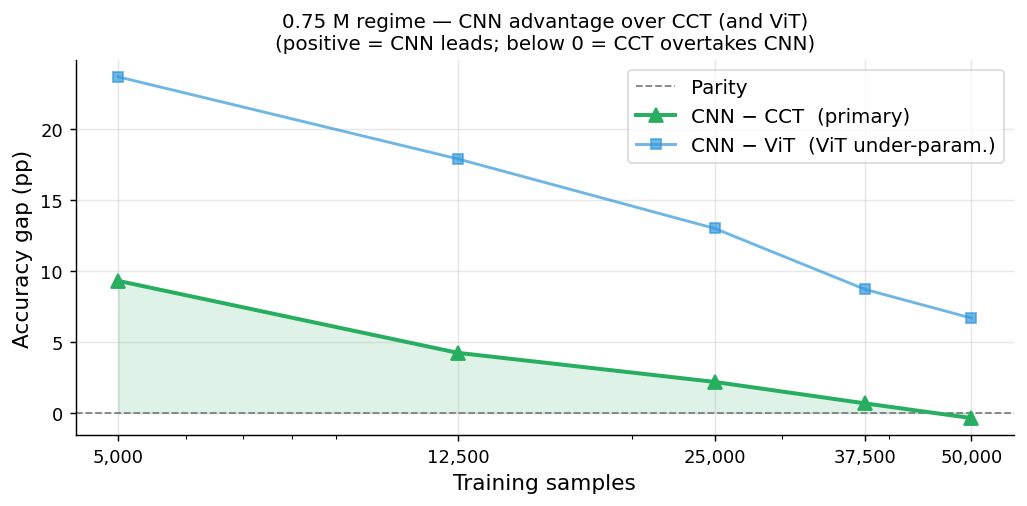

In [20]:
# ── CNN vs CCT gap (primary comparison at 0.75 M) ─────────────────────────────
cnn_s = np.array([final_acc('cnn_small', f) for f in FRACTIONS])
vit_s = np.array([final_acc('vit_small', f) for f in FRACTIONS])
cct_s = np.array([final_acc('cct_small', f) for f in FRACTIONS])

fig, ax = plt.subplots(figsize=(8, 4))
ax.axhline(0, color='gray', linewidth=1.0, linestyle='--', label='Parity')
ax.fill_between(SAMPLES, 0, cnn_s - cct_s, alpha=0.15, color='#27AE60')
ax.plot(SAMPLES, cnn_s - cct_s, color='#27AE60', marker='^',
        linewidth=2.2, markersize=8, label='CNN − CCT  (primary)')
ax.plot(SAMPLES, cnn_s - vit_s, color='#3498DB', marker='s',
        linewidth=1.6, markersize=6, alpha=0.7, label='CNN − ViT  (ViT under-param.)')

ax.set_xscale('log')
ax.set_xticks(SAMPLES)
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{int(x):,}'))
ax.set_xlabel('Training samples', fontsize=12)
ax.set_ylabel('Accuracy gap (pp)', fontsize=12)
ax.set_title('0.75 M regime — CNN advantage over CCT (and ViT)\n'
             '(positive = CNN leads; below 0 = CCT overtakes CNN)', fontsize=11)
ax.legend(fontsize=11, framealpha=0.7)
plt.tight_layout()
plt.savefig('fig9_gap_075M.pdf', bbox_inches='tight')
plt.show()

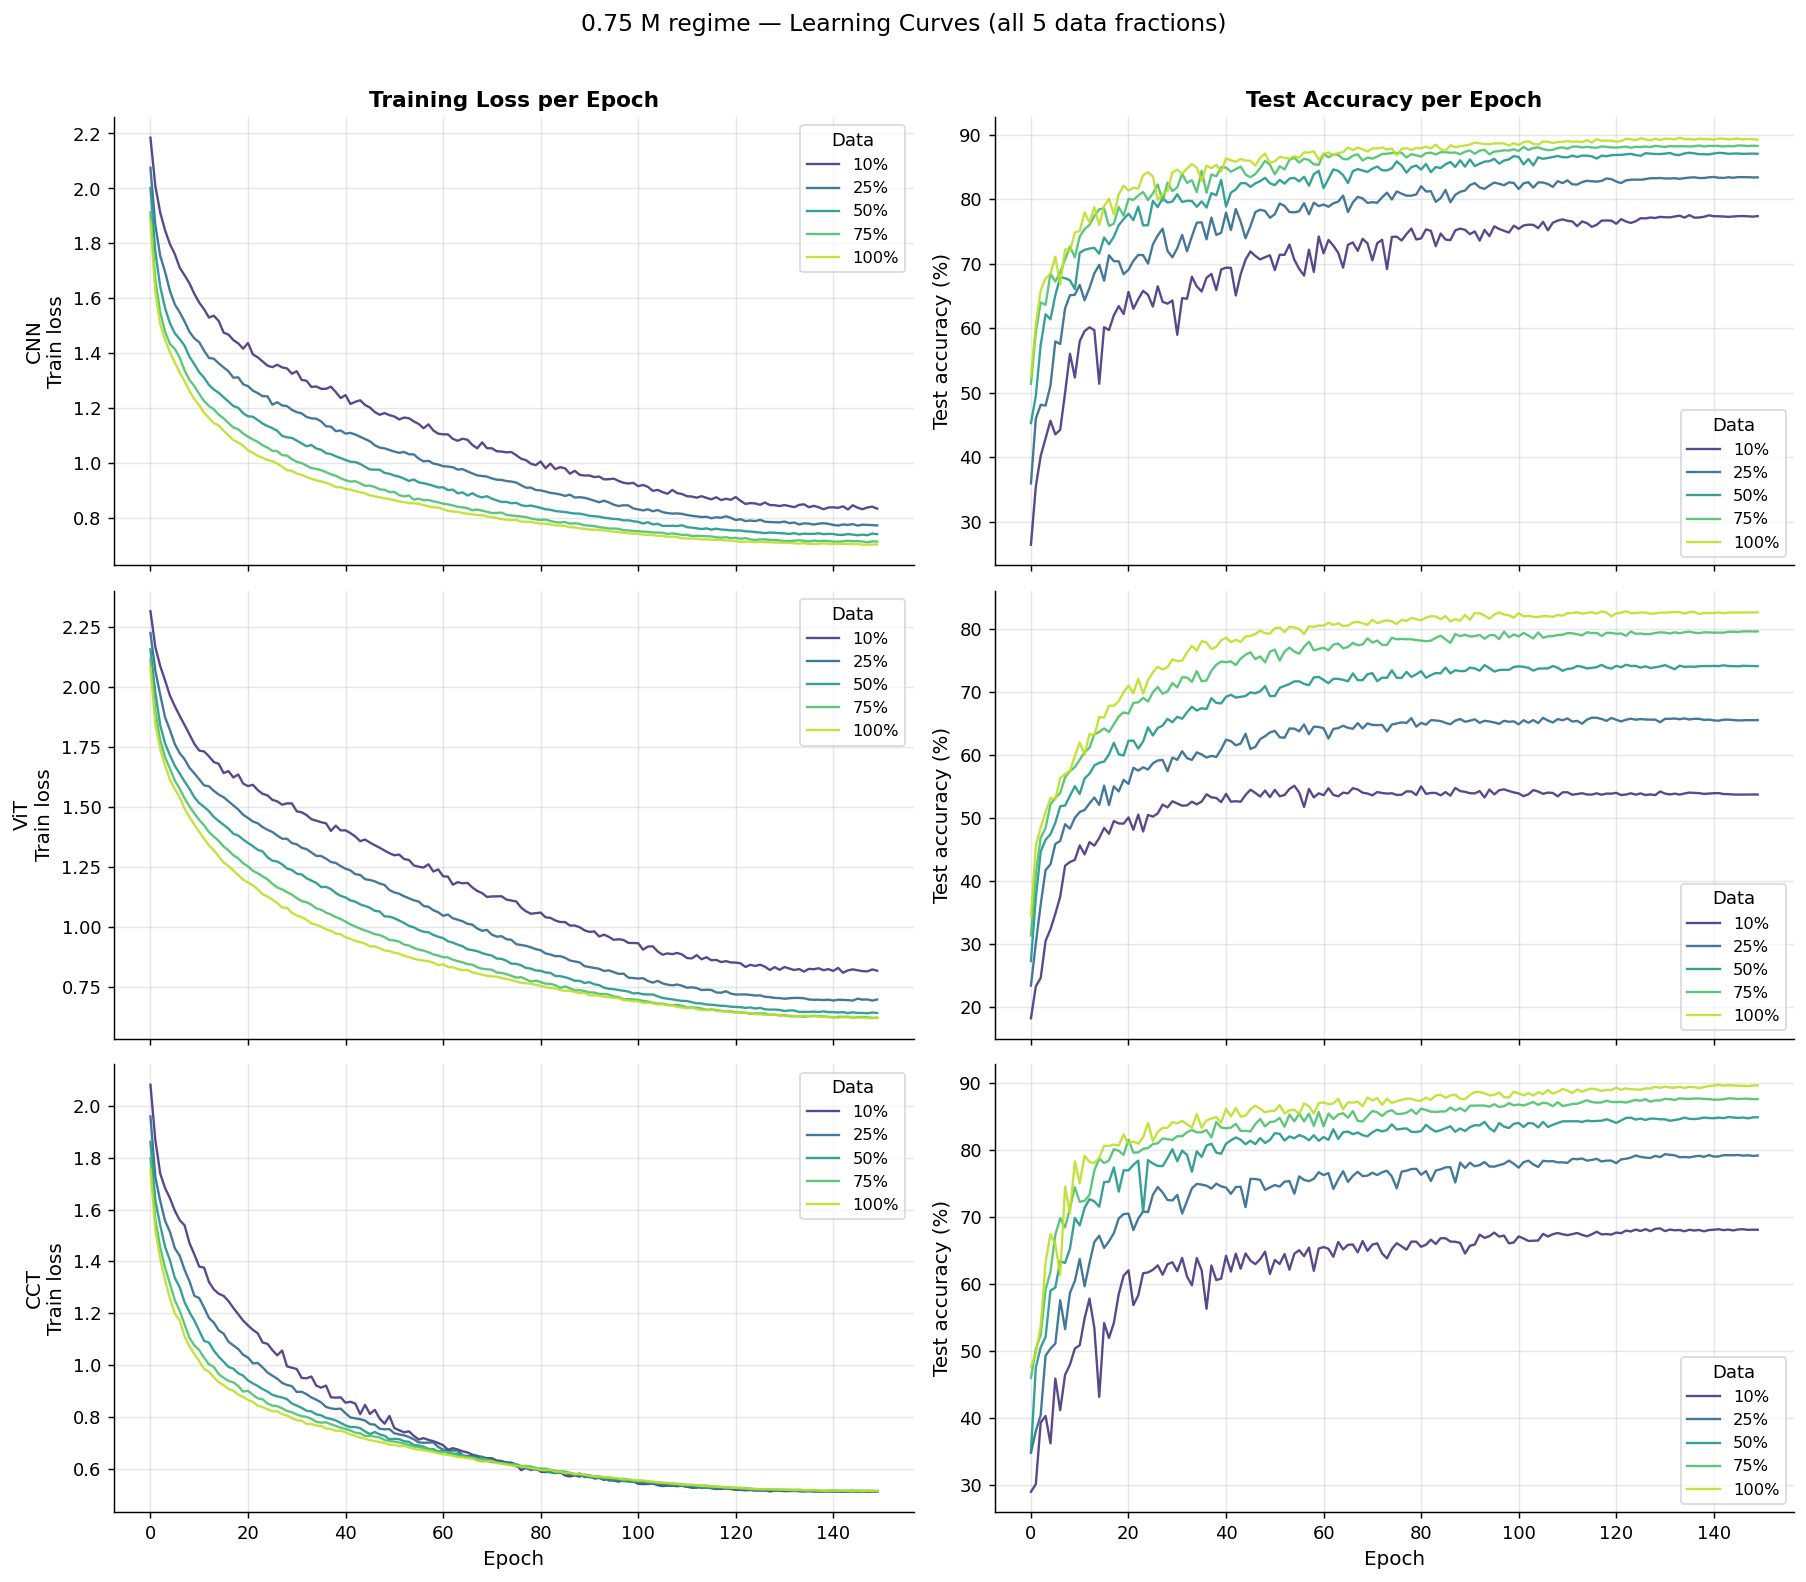

In [21]:
# ── Learning curves at 0.75 M — one row per architecture, all 5 fractions ─────
fig, axes = plt.subplots(3, 2, figsize=(14, 12), sharex=True)
frac_colors = plt.cm.viridis(np.linspace(0.15, 0.9, len(FRACTIONS)))

for row, model in enumerate(SMALL_MODELS):
    ax_loss, ax_acc = axes[row, 0], axes[row, 1]
    arch_name = DISPLAY[model]

    for frac, fc in zip(FRACTIONS, frac_colors):
        ep = epochs(model, frac)
        ax_loss.plot(ep, train_loss(model, frac), color=fc, linewidth=1.3,
                     alpha=0.9, label=f'{int(frac*100)}%')
        ax_acc.plot( ep, test_acc(model, frac),   color=fc, linewidth=1.3,
                     alpha=0.9, label=f'{int(frac*100)}%')

    ax_loss.set_ylabel(f'{arch_name}\nTrain loss', fontsize=11)
    ax_acc.set_ylabel('Test accuracy (%)', fontsize=11)
    ax_loss.legend(title='Data', fontsize=9, framealpha=0.7)
    ax_acc.legend( title='Data', fontsize=9, framealpha=0.7)

for ax in axes[-1]:
    ax.set_xlabel('Epoch', fontsize=11)

axes[0, 0].set_title('Training Loss per Epoch', fontsize=12, fontweight='bold')
axes[0, 1].set_title('Test Accuracy per Epoch', fontsize=12, fontweight='bold')

fig.suptitle('0.75 M regime — Learning Curves (all 5 data fractions)', fontsize=13, y=1.01)
plt.tight_layout()
plt.savefig('fig10_lc_per_arch_075M.pdf', bbox_inches='tight')
plt.show()

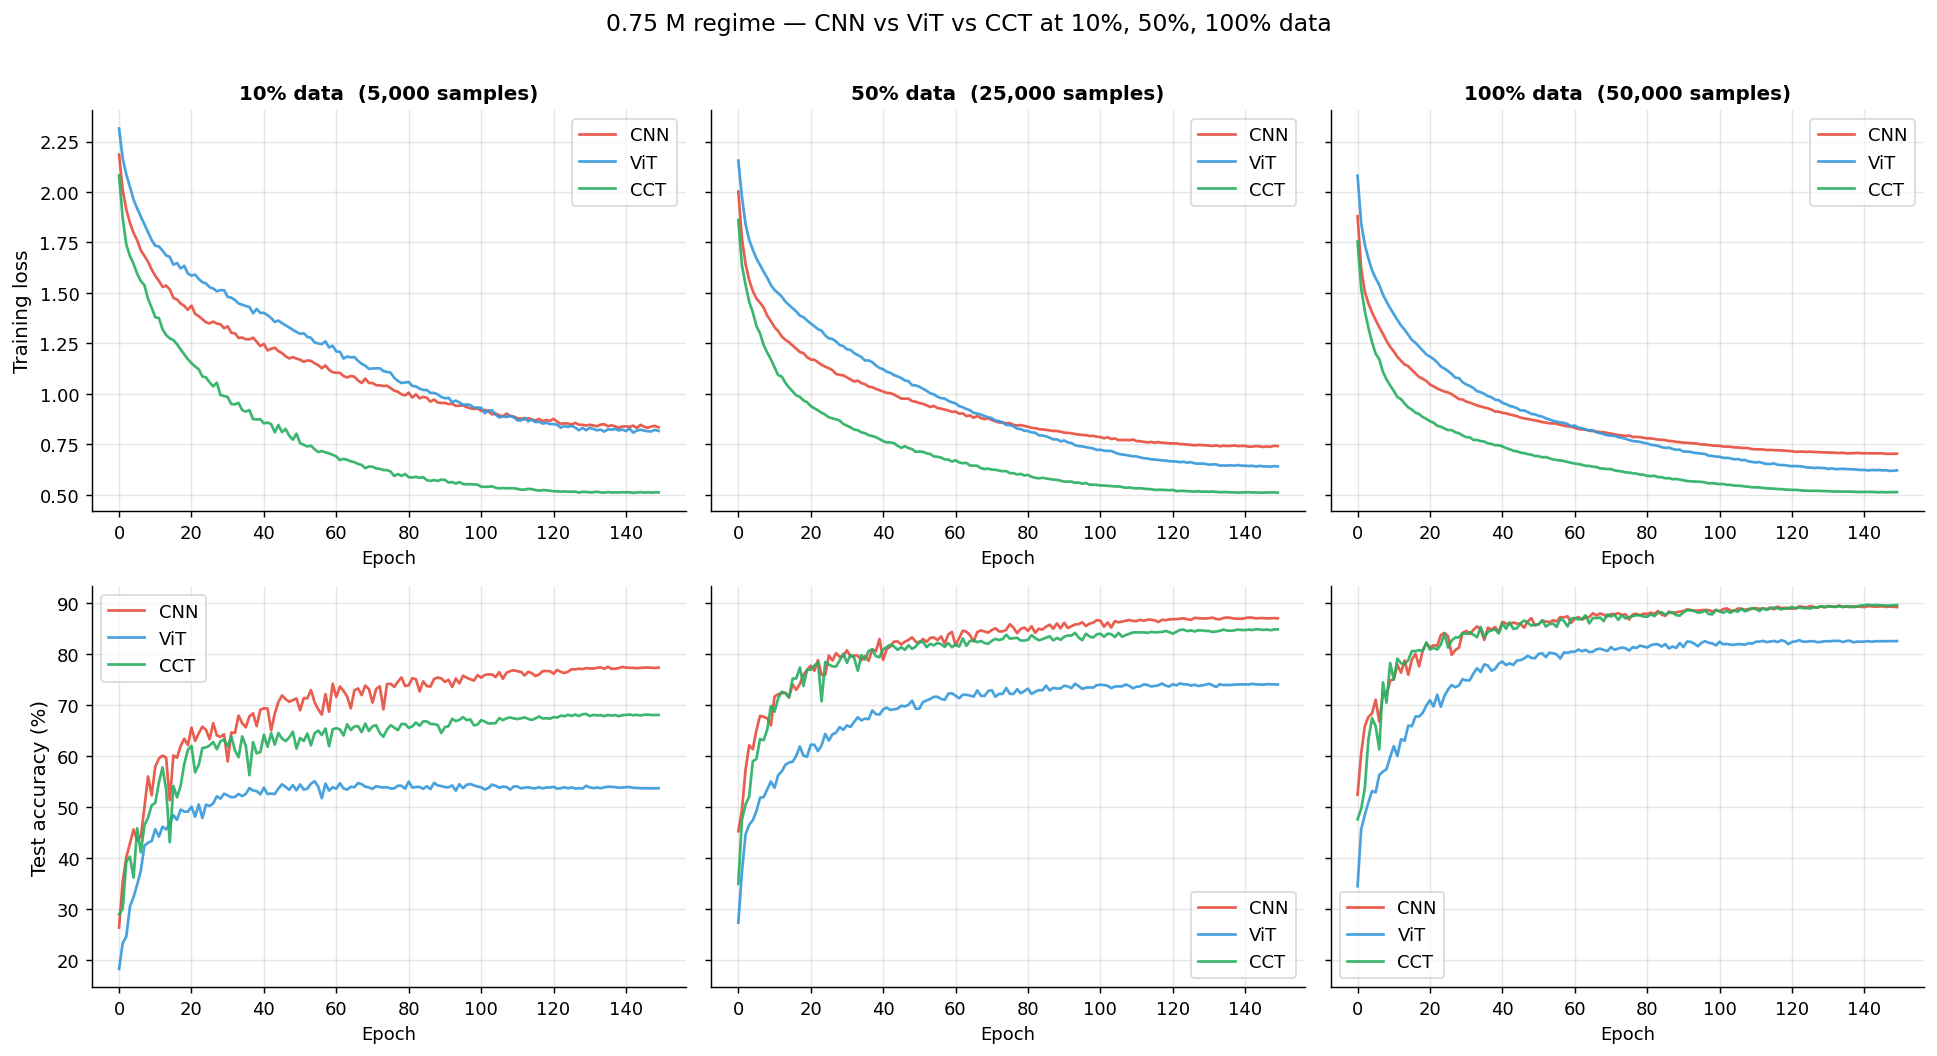

In [22]:
# ── Cross-architecture comparison at 0.75 M, key fractions ────────────────────
fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharey='row')

for col, frac in enumerate(KEY_FRACS):
    ax_loss, ax_acc = axes[0, col], axes[1, col]
    title = f'{int(frac*100)}% data  ({int(N_TRAIN*frac):,} samples)'

    for model in SMALL_MODELS:
        ep = epochs(model, frac)
        ax_loss.plot(ep, train_loss(model, frac), color=COLORS[model],
                     linewidth=1.5, label=DISPLAY[model], alpha=0.9)
        ax_acc.plot( ep, test_acc(model, frac),   color=COLORS[model],
                     linewidth=1.5, label=DISPLAY[model], alpha=0.9)

    ax_loss.set_title(title, fontsize=11, fontweight='bold')
    ax_loss.legend(fontsize=10, framealpha=0.7)
    ax_acc.legend( fontsize=10, framealpha=0.7)
    ax_loss.set_xlabel('Epoch', fontsize=10)
    ax_acc.set_xlabel('Epoch', fontsize=10)

axes[0, 0].set_ylabel('Training loss', fontsize=11)
axes[1, 0].set_ylabel('Test accuracy (%)', fontsize=11)

fig.suptitle('0.75 M regime — CNN vs ViT vs CCT at 10%, 50%, 100% data', fontsize=13, y=1.01)
plt.tight_layout()
plt.savefig('fig11_lc_cross_075M.pdf', bbox_inches='tight')
plt.show()

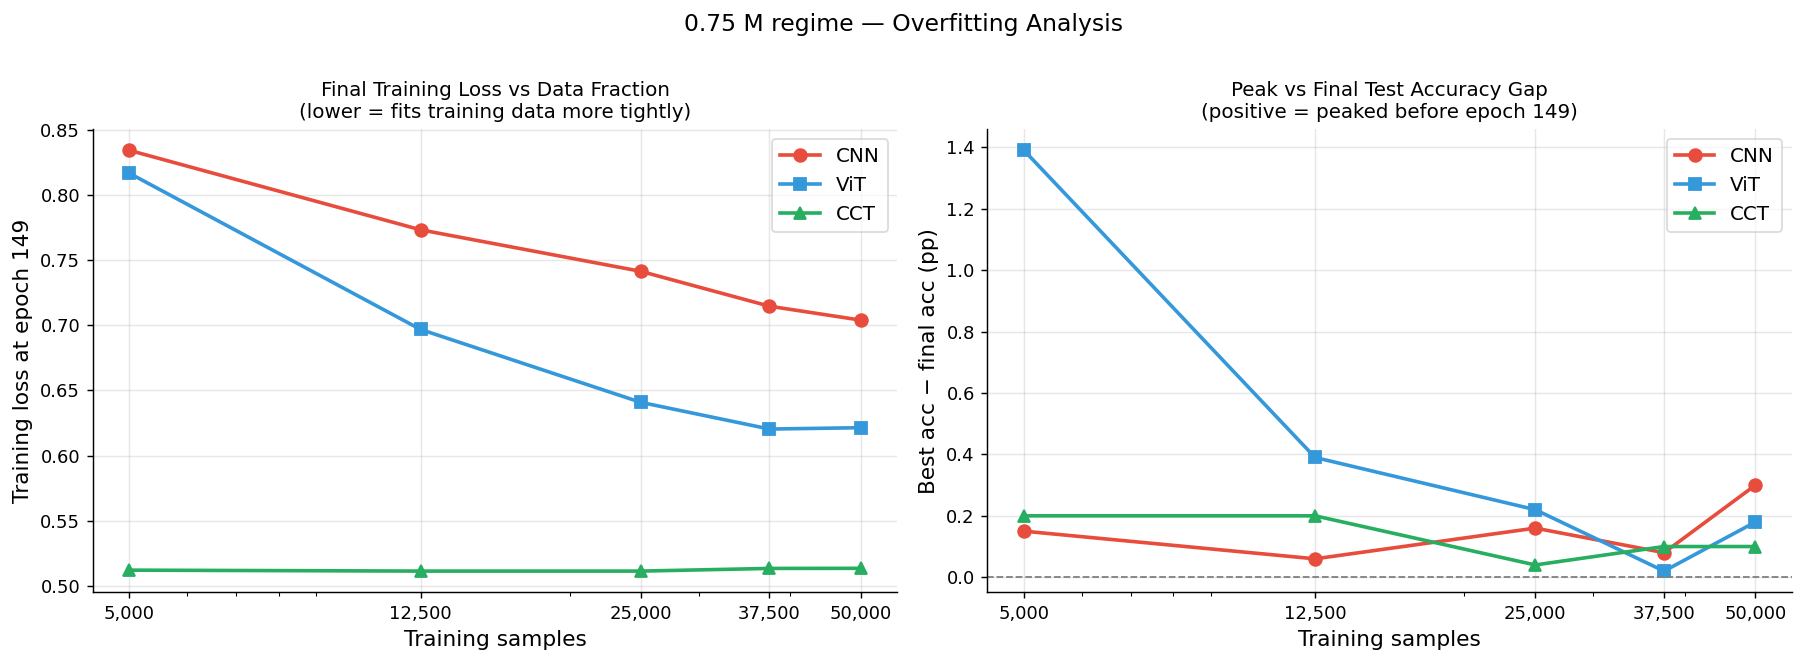

In [23]:
### Interpretation — Secondary Regime — Accuracy & Convergence (0.75 M)

# ── Overfitting analysis at 0.75 M ────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax = axes[0]
for model in SMALL_MODELS:
    final_losses = [results[model][f][-1]['loss'] for f in FRACTIONS]
    ax.plot(SAMPLES, final_losses, color=COLORS[model], marker=MARKERS[model],
            linewidth=2, markersize=7, label=DISPLAY[model])
ax.set_xscale('log')
ax.set_xticks(SAMPLES)
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{int(x):,}'))
ax.set_xlabel('Training samples', fontsize=12)
ax.set_ylabel('Training loss at epoch 149', fontsize=12)
ax.set_title('Final Training Loss vs Data Fraction\n(lower = fits training data more tightly)', fontsize=11)
ax.legend(fontsize=11, framealpha=0.7)

ax = axes[1]
for model in SMALL_MODELS:
    gaps = [best_acc(model, f) - final_acc(model, f) for f in FRACTIONS]
    ax.plot(SAMPLES, gaps, color=COLORS[model], marker=MARKERS[model],
            linewidth=2, markersize=7, label=DISPLAY[model])
ax.axhline(0, color='gray', linewidth=1.0, linestyle='--')
ax.set_xscale('log')
ax.set_xticks(SAMPLES)
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{int(x):,}'))
ax.set_xlabel('Training samples', fontsize=12)
ax.set_ylabel('Best acc − final acc (pp)', fontsize=12)
ax.set_title('Peak vs Final Test Accuracy Gap\n(positive = peaked before epoch 149)', fontsize=11)
ax.legend(fontsize=11, framealpha=0.7)

fig.suptitle('0.75 M regime — Overfitting Analysis', fontsize=13, y=1.01)
plt.tight_layout()
plt.savefig('fig12_overfit_075M.pdf', bbox_inches='tight')
plt.show()

---
### Interpretation — Secondary Regime — Accuracy & Convergence (0.75 M)
The secondary regime is where the complementary strengths and weaknesses of the three architectures become most clearly legible. $At$ $low$ $data$ fractions, the $CNN$ $leads$ convincingly: its $convolutional$ $filters$ impose a strong spatial prior that allows the model to identify useful structure even when examples are scarce. The CCT, despite also having a convolutional tokenizer, starts further behind — its transformer layers require more data to contribute meaningfully above what the tokenizer alone provides.

The most instructive part of the analysis is what happens as data grows. The $gap$ between $CNN$ $and$ $CCT$ $closes$ steadily and eventually disappears: at full dataset size, the two architectures converge to near parity, with the CCT marginally ahead. This crossover is not incidental — it reflects the complementary design of the CCT. The convolutional tokenizer delivers sample efficiency at low data; the transformer layers add the flexibility needed to extract additional value as data grows. Together, they allow the CCT to compete with a pure convolutional model across the entire data range, despite operating under a tight parameter budget.

The ViT's trajectory tells the opposite story. Its gap with the CNN does narrow with data, but far more slowly than the CCT's, and the absolute distance remains large even at full dataset size. When both $data$ and $capacity$ are $limited$ $simultaneously$, the $absence$ of $inductive$ $bias$ is not a marginal disadvantage — it is a $structural$ $bottleneck$ that more data can alleviate but not resolve within the scale of this experiment.

The gap analysis makes this point most directly: the CNN's advantage over the CCT erodes steadily and eventually vanishes, while its advantage over the ViT remains wide and persistent. Inductive bias and architectural flexibility, in this regime, are not interchangeable.


/opt/anaconda3/envs/project13/lib/python3.11/site-packages/torch/nn/modules/transformer.py:379: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  warnings.warn(
/opt/anaconda3/envs/project13/lib/python3.11/site-packages/torch/nn/modules/transformer.py:379: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  warnings.warn(
/opt/anaconda3/envs/project13/lib/python3.11/site-packages/torch/nn/modules/transformer.py:379: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  warnings.warn(
/opt/anaconda3/envs/project13/lib/python3.11/site-packages/torch/nn/modules/transformer.py:379: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  warnings.warn(
/opt/anaconda3/envs/project13/lib/python3.11/site-packages/torch

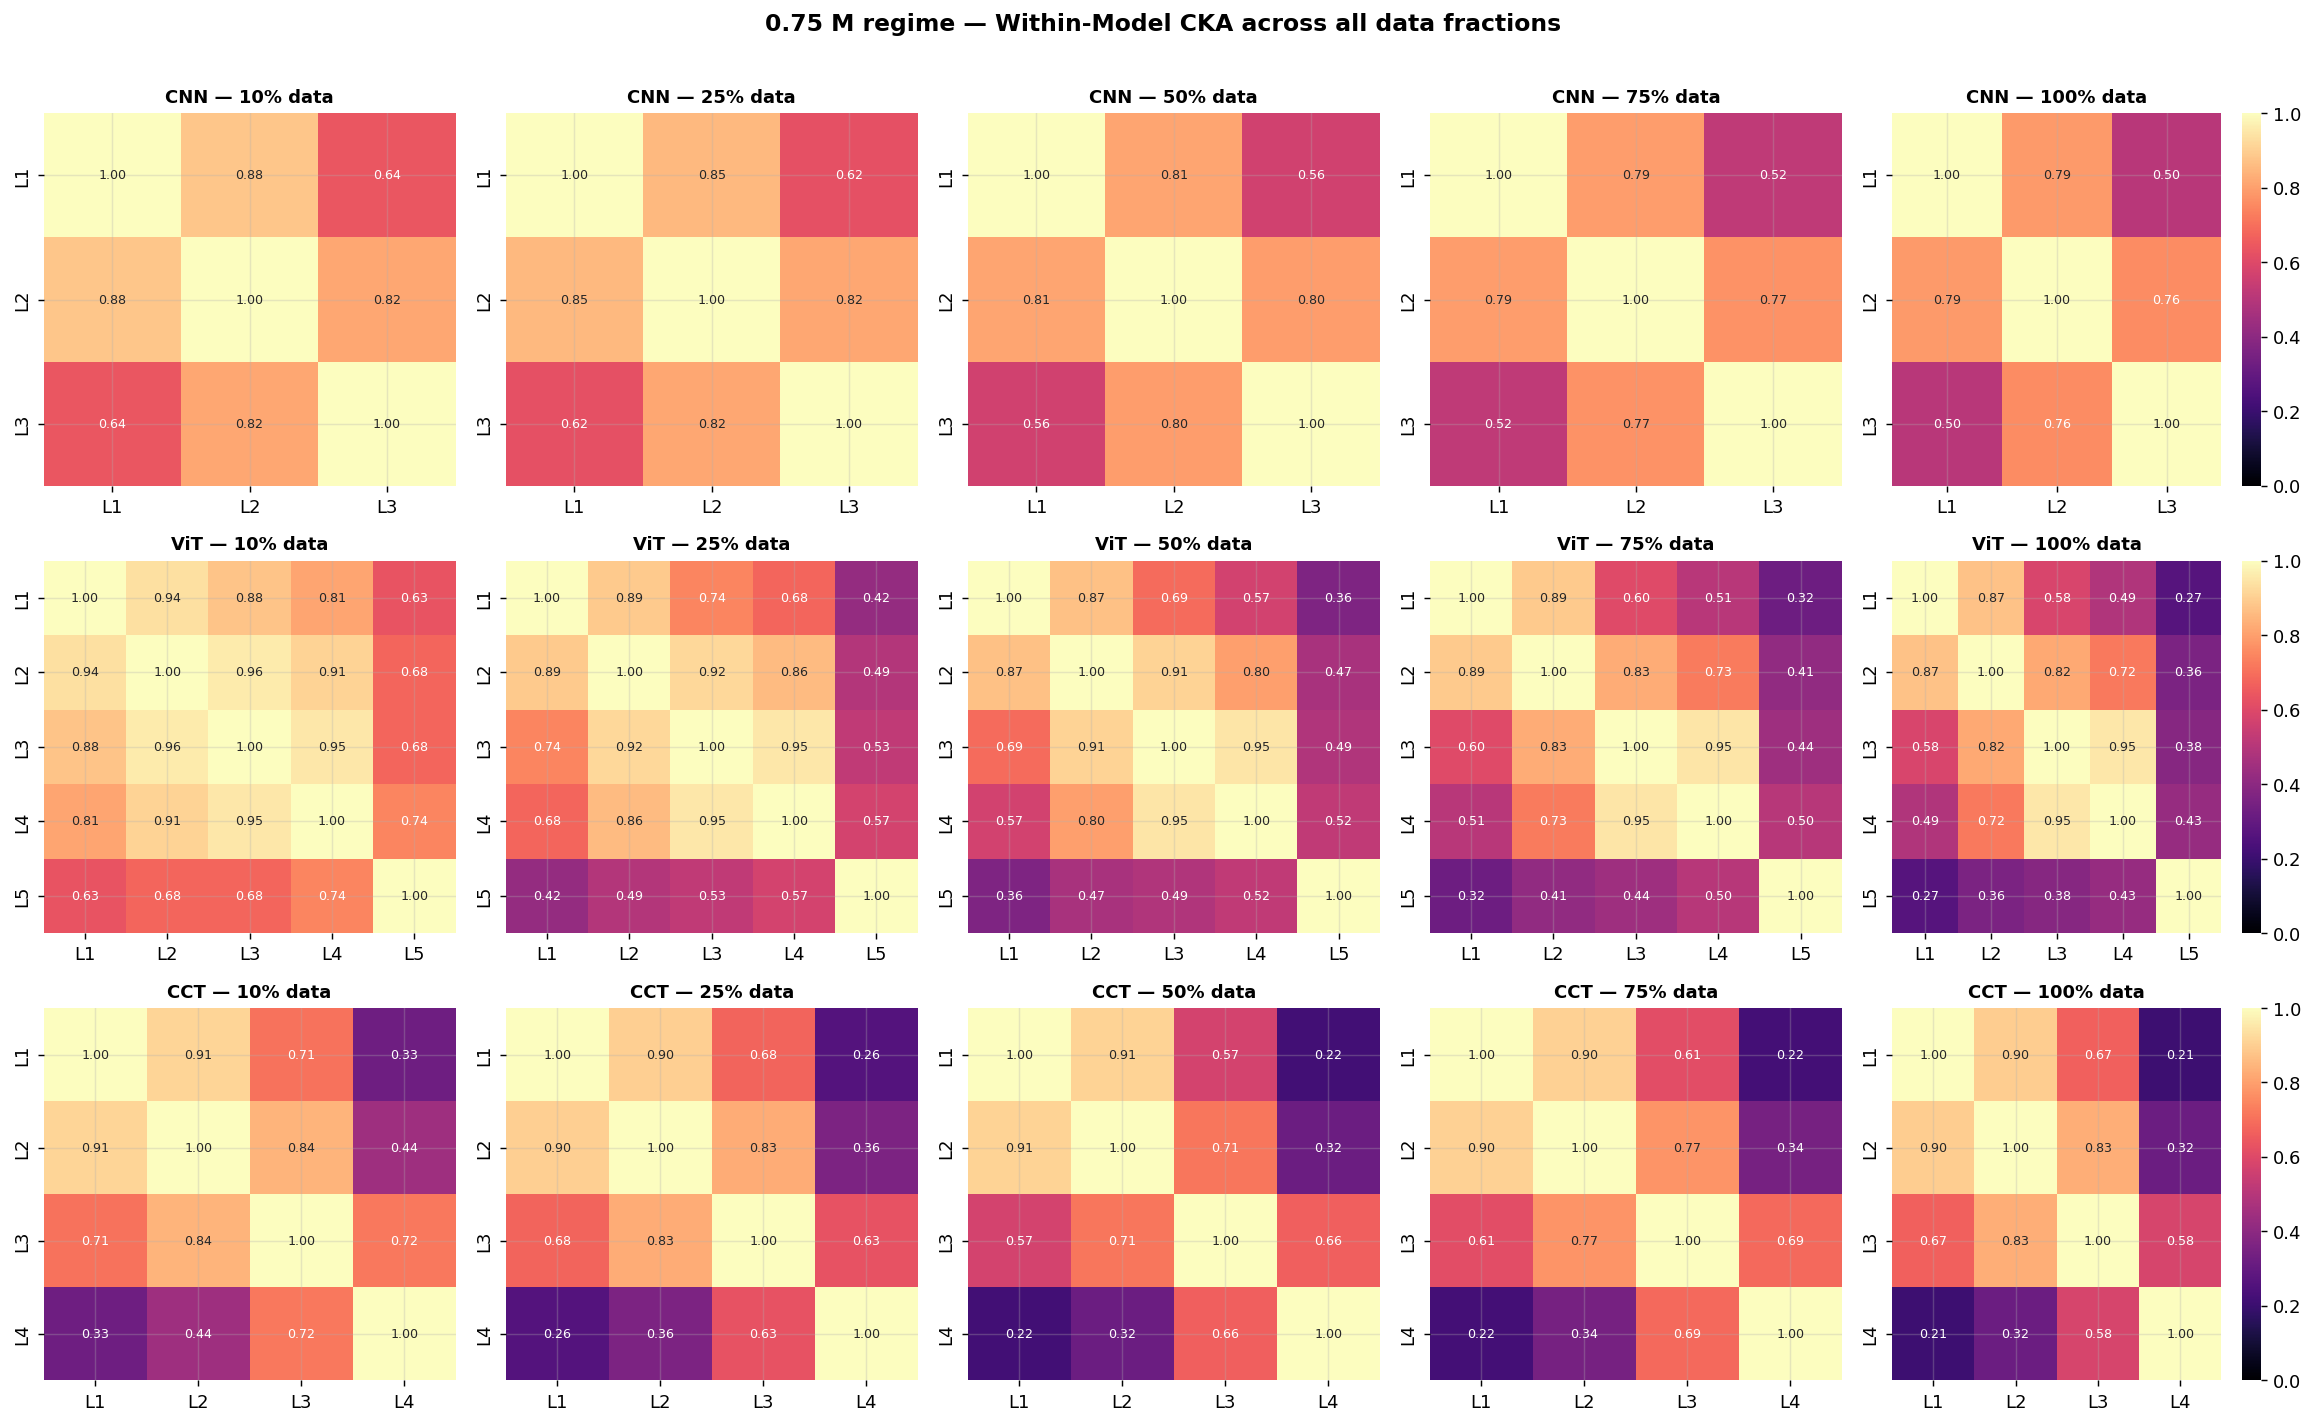

In [24]:
# ── Within-model CKA at 0.75 M — layers × layers, ALL fractions ─────────────
fig, axes = plt.subplots(len(SMALL_MODELS), len(FRACTIONS),
                         figsize=(3.6 * len(FRACTIONS), 3.6 * len(SMALL_MODELS)))

for row, model_name in enumerate(SMALL_MODELS):
    for col, frac in enumerate(FRACTIONS):
        ax = axes[row, col]
        model  = load_model(model_name, frac)
        layers = get_internal_layers(model, model_name)
        reps   = get_reps(model, test_loader, layers, max_batches=6)

        n   = len(reps)
        mat = np.zeros((n, n))
        for i in range(n):
            for j in range(n):
                mat[i, j] = linear_cka(reps[i], reps[j])

        lbls = [f'L{i+1}' for i in range(n)]
        sns.heatmap(mat, ax=ax, vmin=0, vmax=1, cmap='magma',
                    annot=True, fmt='.2f', xticklabels=lbls, yticklabels=lbls,
                    cbar=(col == len(FRACTIONS) - 1), annot_kws={'size': 7})
        ax.set_title(f'{DISPLAY[model_name]} — {int(frac*100)}% data',
                     fontsize=10, fontweight='bold')
        del model
        if torch.cuda.is_available(): torch.cuda.empty_cache()

fig.suptitle('0.75 M regime — Within-Model CKA across all data fractions',
             fontsize=13, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('fig13_cka_within_075M.pdf', bbox_inches='tight')
plt.show()


/opt/anaconda3/envs/project13/lib/python3.11/site-packages/torch/nn/modules/transformer.py:379: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  warnings.warn(


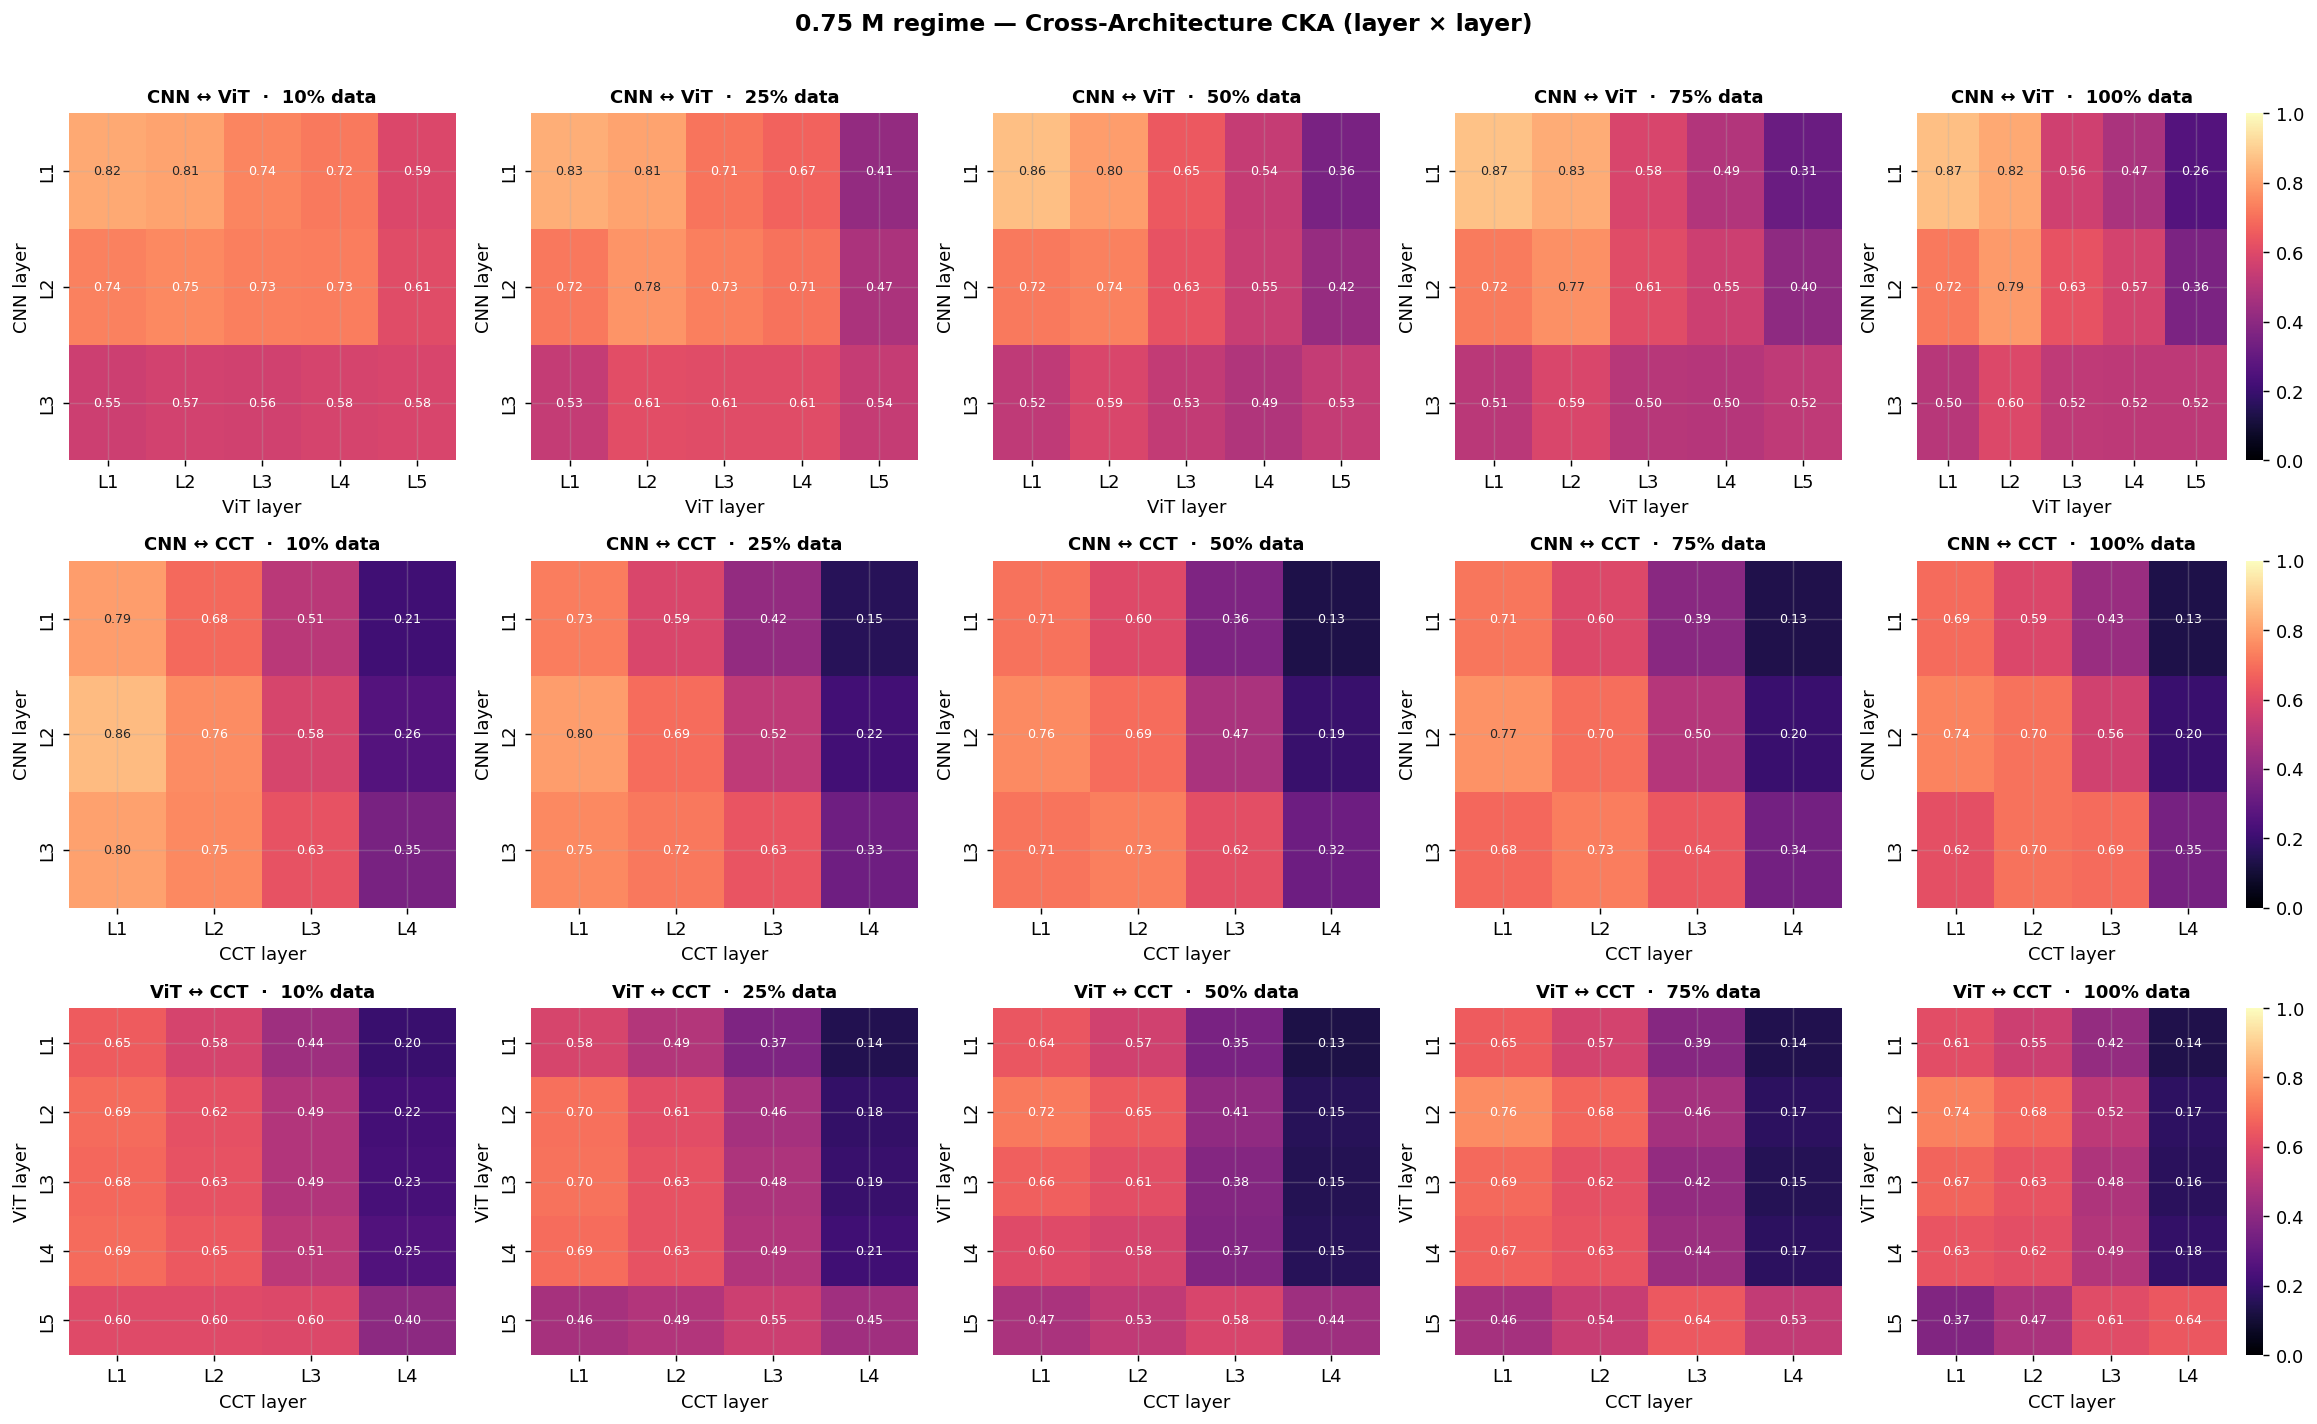

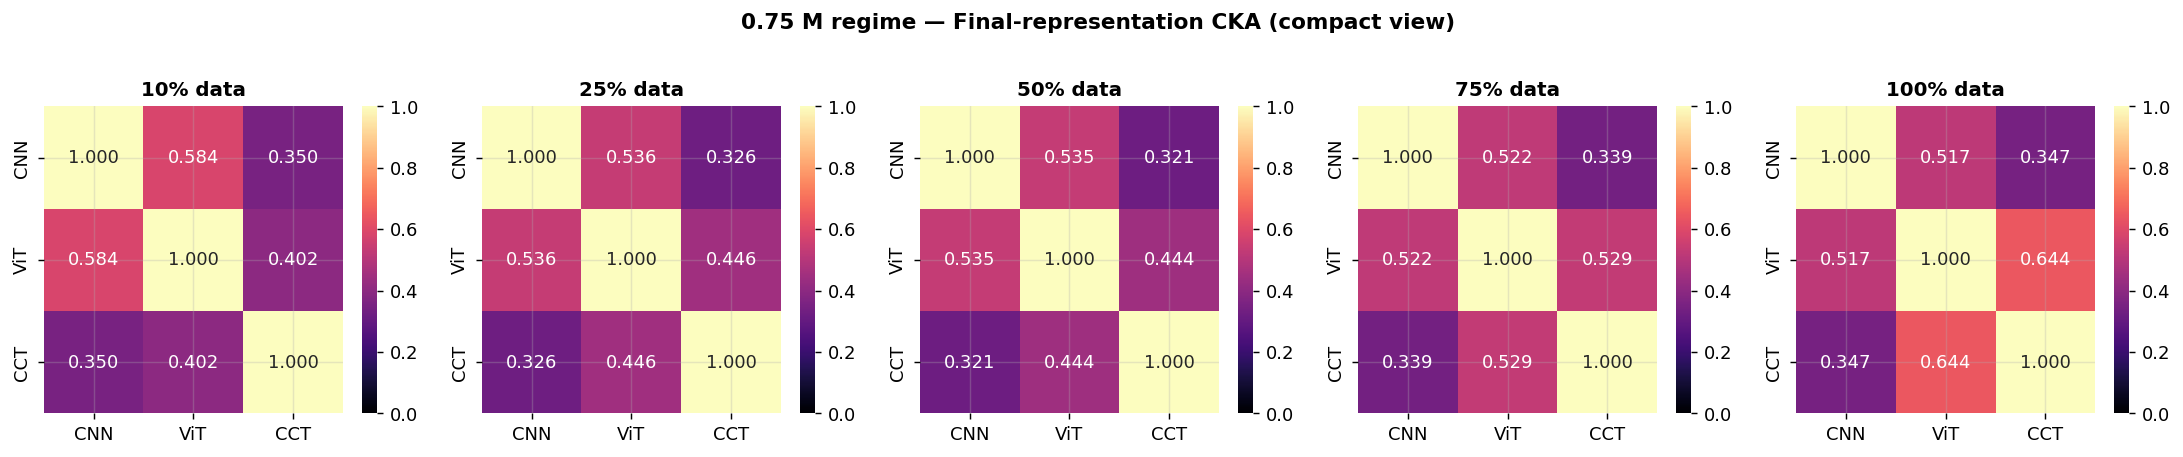

In [25]:
### Interpretation — CKA — Representational Similarity (0.75 M)

# ── Cross-architecture CKA at 0.75 M — layer × layer, all fractions ─────────
PAIRS_S = [('cnn_small', 'vit_small'),
           ('cnn_small', 'cct_small'),
           ('vit_small', 'cct_small')]

reps_by_frac_S = {f: {m: collect_layer_reps(m, f) for m in SMALL_MODELS}
                  for f in FRACTIONS}

fig, axes = plt.subplots(len(PAIRS_S), len(FRACTIONS),
                         figsize=(3.6 * len(FRACTIONS), 3.6 * len(PAIRS_S)))

for row, (mA, mB) in enumerate(PAIRS_S):
    for col, frac in enumerate(FRACTIONS):
        ax = axes[row, col]
        rA = reps_by_frac_S[frac][mA]
        rB = reps_by_frac_S[frac][mB]
        mat = np.zeros((len(rA), len(rB)))
        for i, x in enumerate(rA):
            for j, y in enumerate(rB):
                mat[i, j] = linear_cka(x, y)
        xlbls = [f'L{j+1}' for j in range(len(rB))]
        ylbls = [f'L{i+1}' for i in range(len(rA))]
        sns.heatmap(mat, ax=ax, vmin=0, vmax=1, cmap='magma',
                    annot=True, fmt='.2f', xticklabels=xlbls, yticklabels=ylbls,
                    cbar=(col == len(FRACTIONS) - 1), annot_kws={'size': 7})
        ax.set_xlabel(f'{DISPLAY[mB]} layer'); ax.set_ylabel(f'{DISPLAY[mA]} layer')
        ax.set_title(f'{DISPLAY[mA]} ↔ {DISPLAY[mB]}  ·  {int(frac*100)}% data',
                     fontsize=10, fontweight='bold')

fig.suptitle('0.75 M regime — Cross-Architecture CKA (layer × layer)',
             fontsize=13, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('fig14_cka_cross_075M.pdf', bbox_inches='tight')
plt.show()

# ── Compact summary: final-representation CKA at 0.75 M ──────────────────────
fig, axes = plt.subplots(1, len(FRACTIONS), figsize=(3.4 * len(FRACTIONS), 3.4))
lbls = [DISPLAY[m] for m in SMALL_MODELS]

for ax, frac in zip(axes, FRACTIONS):
    mat = np.zeros((3, 3))
    for i, mi in enumerate(SMALL_MODELS):
        for j, mj in enumerate(SMALL_MODELS):
            mat[i, j] = linear_cka(reps_by_frac_S[frac][mi][-1],
                                   reps_by_frac_S[frac][mj][-1])
    sns.heatmap(mat, ax=ax, vmin=0, vmax=1, cmap='magma',
                annot=True, fmt='.3f', xticklabels=lbls, yticklabels=lbls)
    ax.set_title(f'{int(frac*100)}% data', fontsize=11, fontweight='bold')

fig.suptitle('0.75 M regime — Final-representation CKA (compact view)',
             fontsize=12, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


---
### Interpretation — CKA — Representational Similarity (0.75 M)
At the $lower$ $parameter$ $budget$, the $representational$ $differences$ between architectures are $more$ $pronounced$ than in the primary regime, and the consequences of data scarcity are more visible in the geometry of learned representations.

The $CNN's$ $representation$ structure is $consistent$ regardless of scale: it maintains a clear $layer-wise$ $hierarchy$, with each processing stage producing representations that are meaningfully distinct from those of the previous one. This structural stability confirms that hierarchical feature extraction is an architectural property of the CNN, not a consequence of having more capacity.

The $ViT's$ situation is more revealing at 0.75M than at 5M. At low data fractions, the similarity between consecutive blocks is nearly uniform throughout the network — a $flat$ $similarity$ $matrix$ that signals $data$ $starvation$. The model's blocks are not differentiating: they are passing representations forward with minimal transformation, unable to specialise because the gradient signal is too weak and the parameter budget too tight to carve out distinct functional roles for different depths.

The $CCT's$ representational behaviour shifts between regimes in a telling way. At 0.75M, its representations diverge more from the CNN's than at 5M. With fewer parameters to distribute across the tokenizer and the transformer blocks, the attention mechanism claims a proportionally larger share of the representational budget, pulling the CCT's internal structure further from the CNN's convolutional trajectory. This is not a failure of the hybrid design — it is the attention component playing a larger role precisely when the convolutional prior can no longer carry the full burden alone.

Cross-architecture convergence with more data is also slower and less complete at this scale than in the primary regime, reflecting that capacity constraints limit not only how well models perform but also how far data can reshape the representations they form.


---
# 7 · Augmentation vs. No Augmentation — Who Benefits Most?
---

Every model was re-trained under an identical protocol but with data augmentation disabled
(no `RandomCrop`, no `RandomHorizontalFlip`). Comparing the two runs isolates the contribution
of augmentation from that of architecture, and reveals whether that contribution changes with
dataset size.

**Hypotheses:**
- **CNN** — strong inductive biases (locality, weight sharing) reduce reliance on augmentation;
  the performance gap between augmented and unaugmented runs should be the smallest.
- **ViT** — no locality prior and high data hunger make augmentation a near-necessity,
  especially at low data fractions, where it acts as a substitute for the missing spatial prior.
- **CCT** — the convolutional tokenizer recovers part of the locality bias, so the augmentation
  gain should be intermediate: smaller than the ViT's, larger than the CNN's.


### Reading Guide: Data Augmentation Impact Analysis

**Hypothesis going in:** CCT would benefit least (convolutional tokenizer provides invariance), CNN moderately, ViT the most (no spatial prior, highest data hunger).

**What the data actually shows — a crossover pattern:**
- At **low data fractions (10 %)**, the CNN benefits *more* from augmentation than the ViT, not less. The CNN can immediately exploit the additional invariances; the ViT at 10 % is so underfitted that augmentation barely moves the needle.
- At **high data fractions (75–100 %)**, the pattern inverts: ViT gains the most because it finally has enough data to leverage the extra diversity.
- **CCT benefits the least at every fraction** — the convolutional tokenizer already encodes the shift and flip invariances that augmentation would otherwise provide.

The most diagnostic column is **10 %**: a large value there signals augmentation-dependence; a small value means the model's inductive bias is already handling the invariance.


**Final test accuracy with and without augmentation**, for every model and data fraction.
The gap between the two bars is the augmentation benefit.

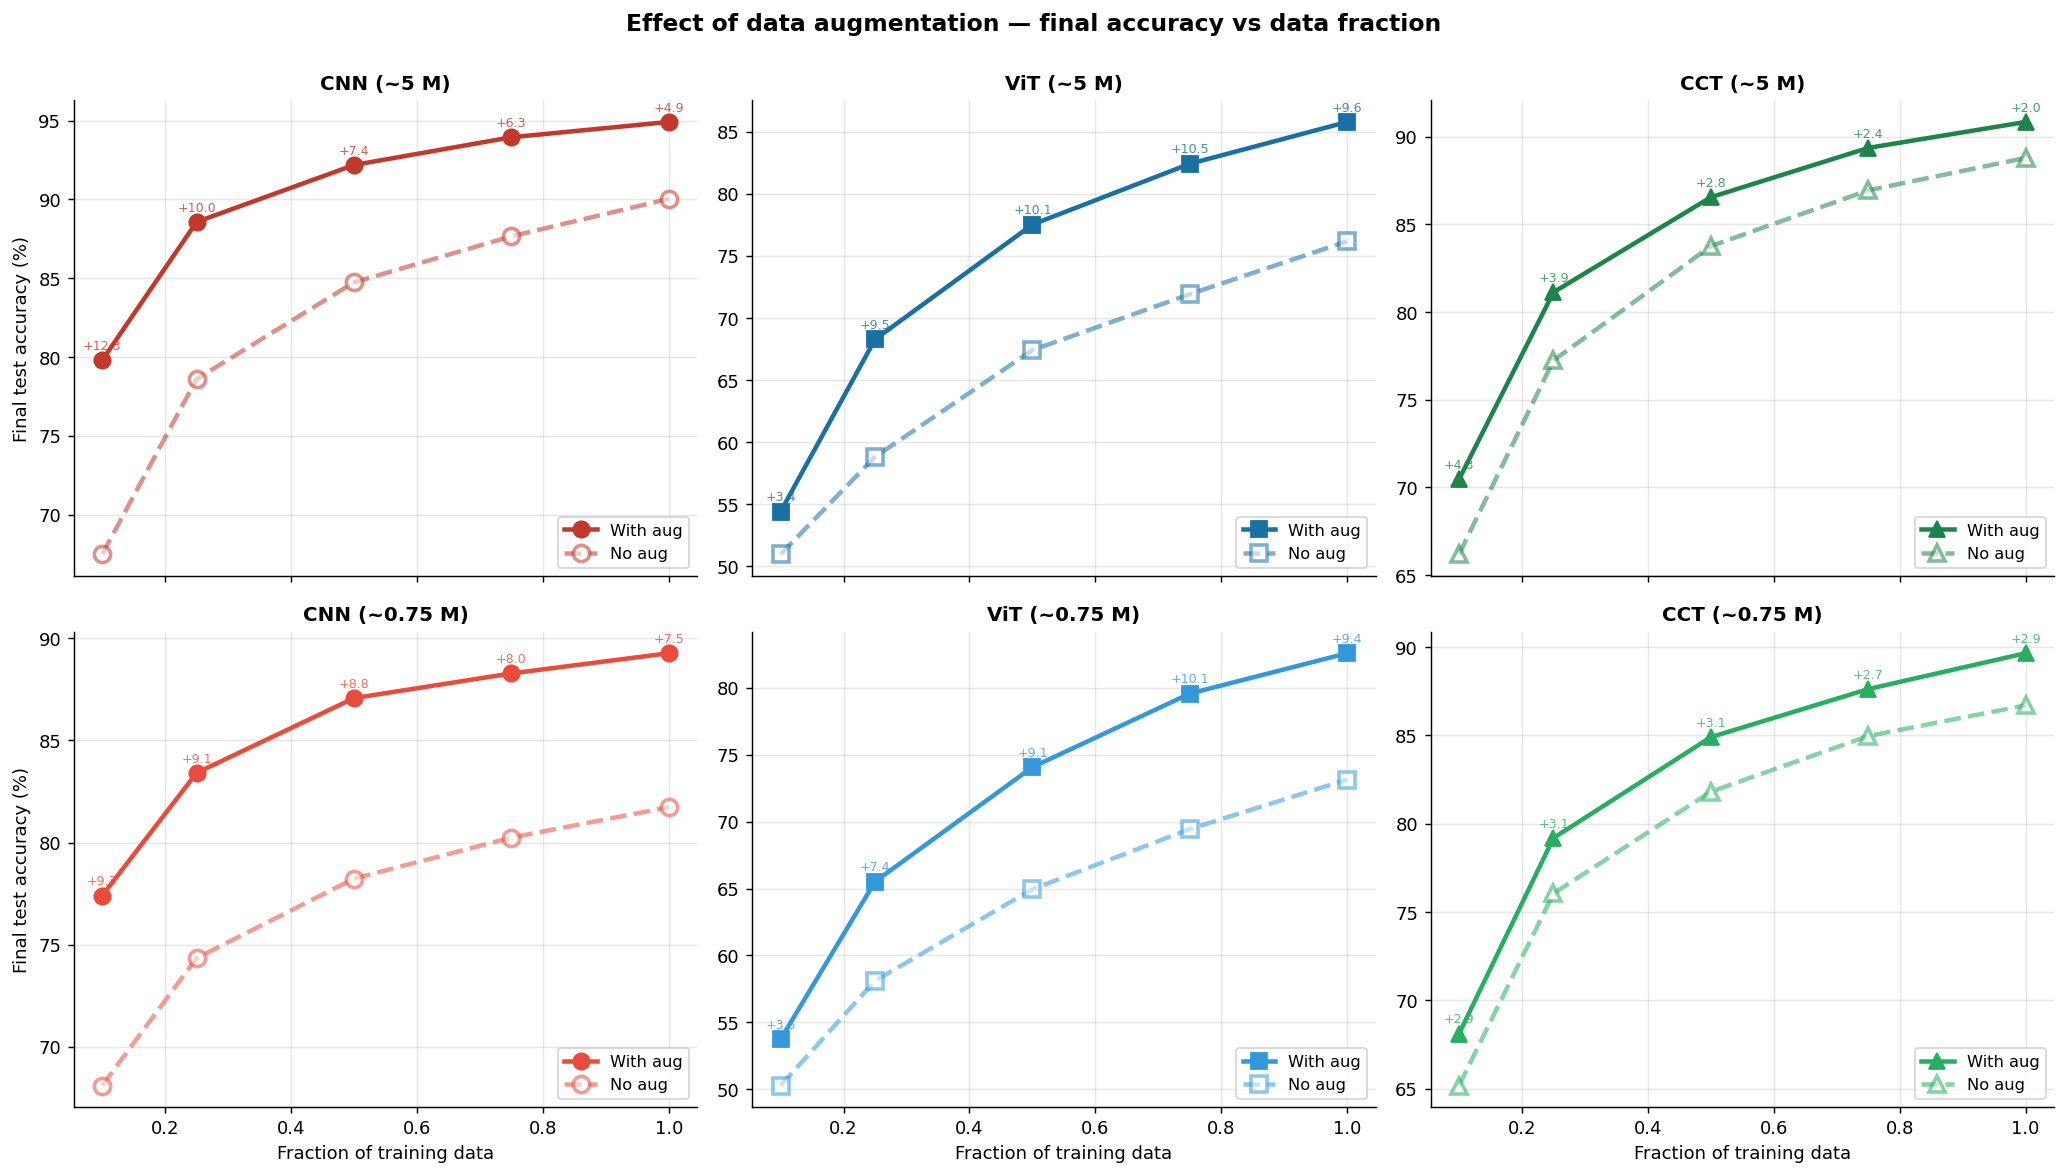

In [26]:
# ── Aug vs no-aug: final accuracy across fractions, per model ────────────────
fig, axes = plt.subplots(2, 3, figsize=(16, 9), sharex=True)

for col, mname in enumerate(['cnn', 'vit', 'cct']):
    for row, size in enumerate(['large', 'small']):
        ax = axes[row, col]
        model = f'{mname}_{size}'
        aug_vals   = [final_acc(model, f)       for f in FRACTIONS]
        noaug_vals = [final_acc_noaug(model, f) for f in FRACTIONS]
        ax.plot(FRACTIONS, aug_vals,   marker=MARKERS[model], color=COLORS[model],
                lw=2.5, ms=9, label='With aug')
        ax.plot(FRACTIONS, noaug_vals, marker=MARKERS[model], color=COLORS[model],
                lw=2.5, ms=9, ls='--', alpha=0.55, label='No aug',
                markerfacecolor='white', markeredgewidth=2)
        for f, va, vn in zip(FRACTIONS, aug_vals, noaug_vals):
            ax.annotate(f'+{va-vn:.1f}', xy=(f, va), xytext=(0, 6),
                        textcoords='offset points', ha='center', fontsize=7,
                        color=COLORS[model], alpha=0.8)
        title_size = '~5 M' if size == 'large' else '~0.75 M'
        ax.set_title(f'{DISPLAY[model]} ({title_size})', fontsize=11, weight='bold')
        ax.grid(alpha=0.3); ax.legend(loc='lower right', fontsize=9)
        if col == 0: ax.set_ylabel('Final test accuracy (%)')
        if row == 1: ax.set_xlabel('Fraction of training data')

fig.suptitle('Effect of data augmentation — final accuracy vs data fraction',
             fontsize=13, weight='bold', y=1.00)
plt.tight_layout(); plt.show()


**Augmentation gain (percentage points) as a heatmap**: rows are models, columns are data
fractions. Darker cells indicate larger benefit from augmentation. The 10% column is the most diagnostic: a large value there
  signals that the model cannot generalise from 5 000 images alone and relies on augmentation
  to fill the gap.

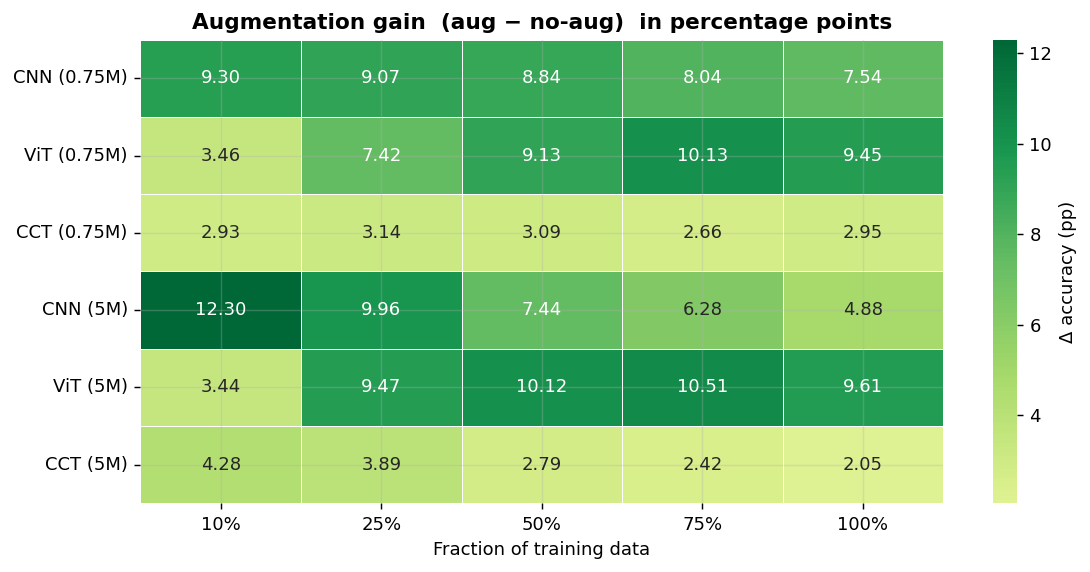


Mean gain across fractions:
CNN (0.75M)    8.56
ViT (0.75M)    7.92
CCT (0.75M)    2.95
CNN (5M)       8.17
ViT (5M)       8.63
CCT (5M)       3.09


In [27]:
# ── Augmentation gain heatmap (aug − noaug, percentage points) ───────────────
import pandas as pd

gain_rows = []
for model in ALL_MODELS:
    gain_rows.append([final_acc(model, f) - final_acc_noaug(model, f) for f in FRACTIONS])
gain_df = pd.DataFrame(
    gain_rows,
    index=[f'{DISPLAY[m]} ({"5M" if "large" in m else "0.75M"})' for m in ALL_MODELS],
    columns=[f'{int(f*100)}%' for f in FRACTIONS],
)

fig, ax = plt.subplots(figsize=(9, 4.5))
sns.heatmap(gain_df, annot=True, fmt='.2f', cmap='RdYlGn', center=0,
            cbar_kws={'label': 'Δ accuracy (pp)'}, ax=ax,
            linewidths=0.5, linecolor='white')
ax.set_title('Augmentation gain  (aug − no-aug)  in percentage points',
             fontsize=12, weight='bold')
ax.set_xlabel('Fraction of training data'); ax.set_ylabel('')
plt.tight_layout(); plt.show()

print('\nMean gain across fractions:')
print(gain_df.mean(axis=1).round(2).to_string())


**Augmentation gain as grouped bars, split by regime**. Makes it easy to compare which
architecture benefits most and whether the gain decays as data grow.

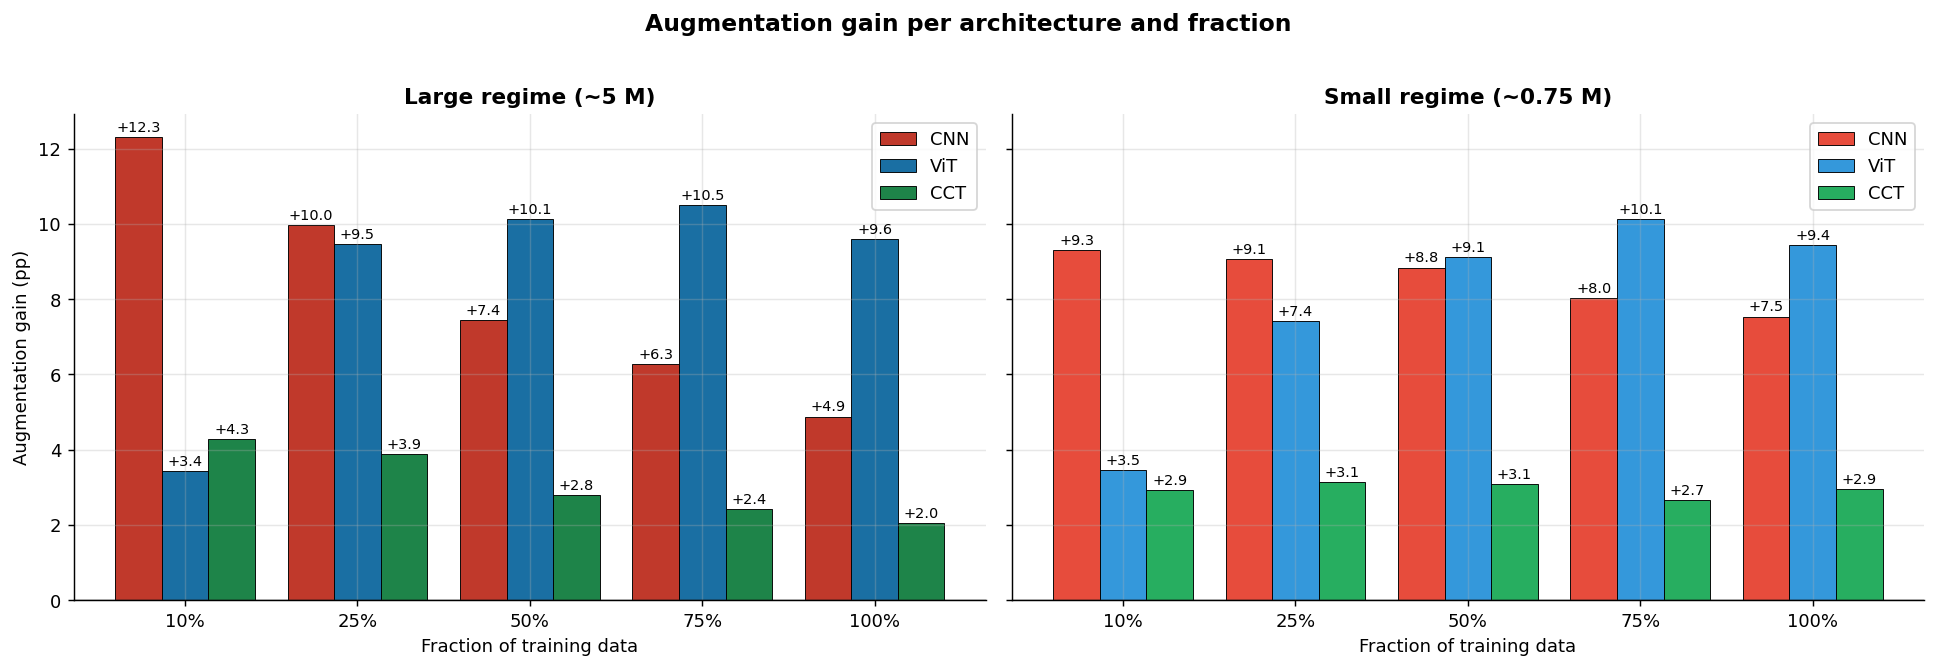

In [28]:
# ── Per-architecture bar chart: gain at each fraction (large + small) ────────
fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharey=True)

x = np.arange(len(FRACTIONS))
width = 0.27

for ax, models, title in zip(
        axes,
        [LARGE_MODELS, SMALL_MODELS],
        ['Large regime (~5 M)', 'Small regime (~0.75 M)']):
    for i, model in enumerate(models):
        gains = [final_acc(model, f) - final_acc_noaug(model, f) for f in FRACTIONS]
        ax.bar(x + (i - 1) * width, gains, width,
               label=DISPLAY[model], color=COLORS[model], edgecolor='black', lw=0.5)
        for xi, g in zip(x + (i - 1) * width, gains):
            ax.text(xi, g + (0.15 if g >= 0 else -0.5), f'{g:+.1f}',
                    ha='center', fontsize=8)
    ax.axhline(0, color='black', lw=0.7)
    ax.set_xticks(x); ax.set_xticklabels([f'{int(f*100)}%' for f in FRACTIONS])
    ax.set_xlabel('Fraction of training data')
    ax.set_title(title, fontsize=12, weight='bold')
    ax.grid(axis='y', alpha=0.3); ax.legend()

axes[0].set_ylabel('Augmentation gain (pp)')
fig.suptitle('Augmentation gain per architecture and fraction',
             fontsize=13, weight='bold', y=1.02)
plt.tight_layout(); plt.show()


**Test accuracy curves over epochs** — solid lines trained with augmentation, dashed without —
at three data fractions. Shows when and how quickly augmentation's benefit materialises
during training. 

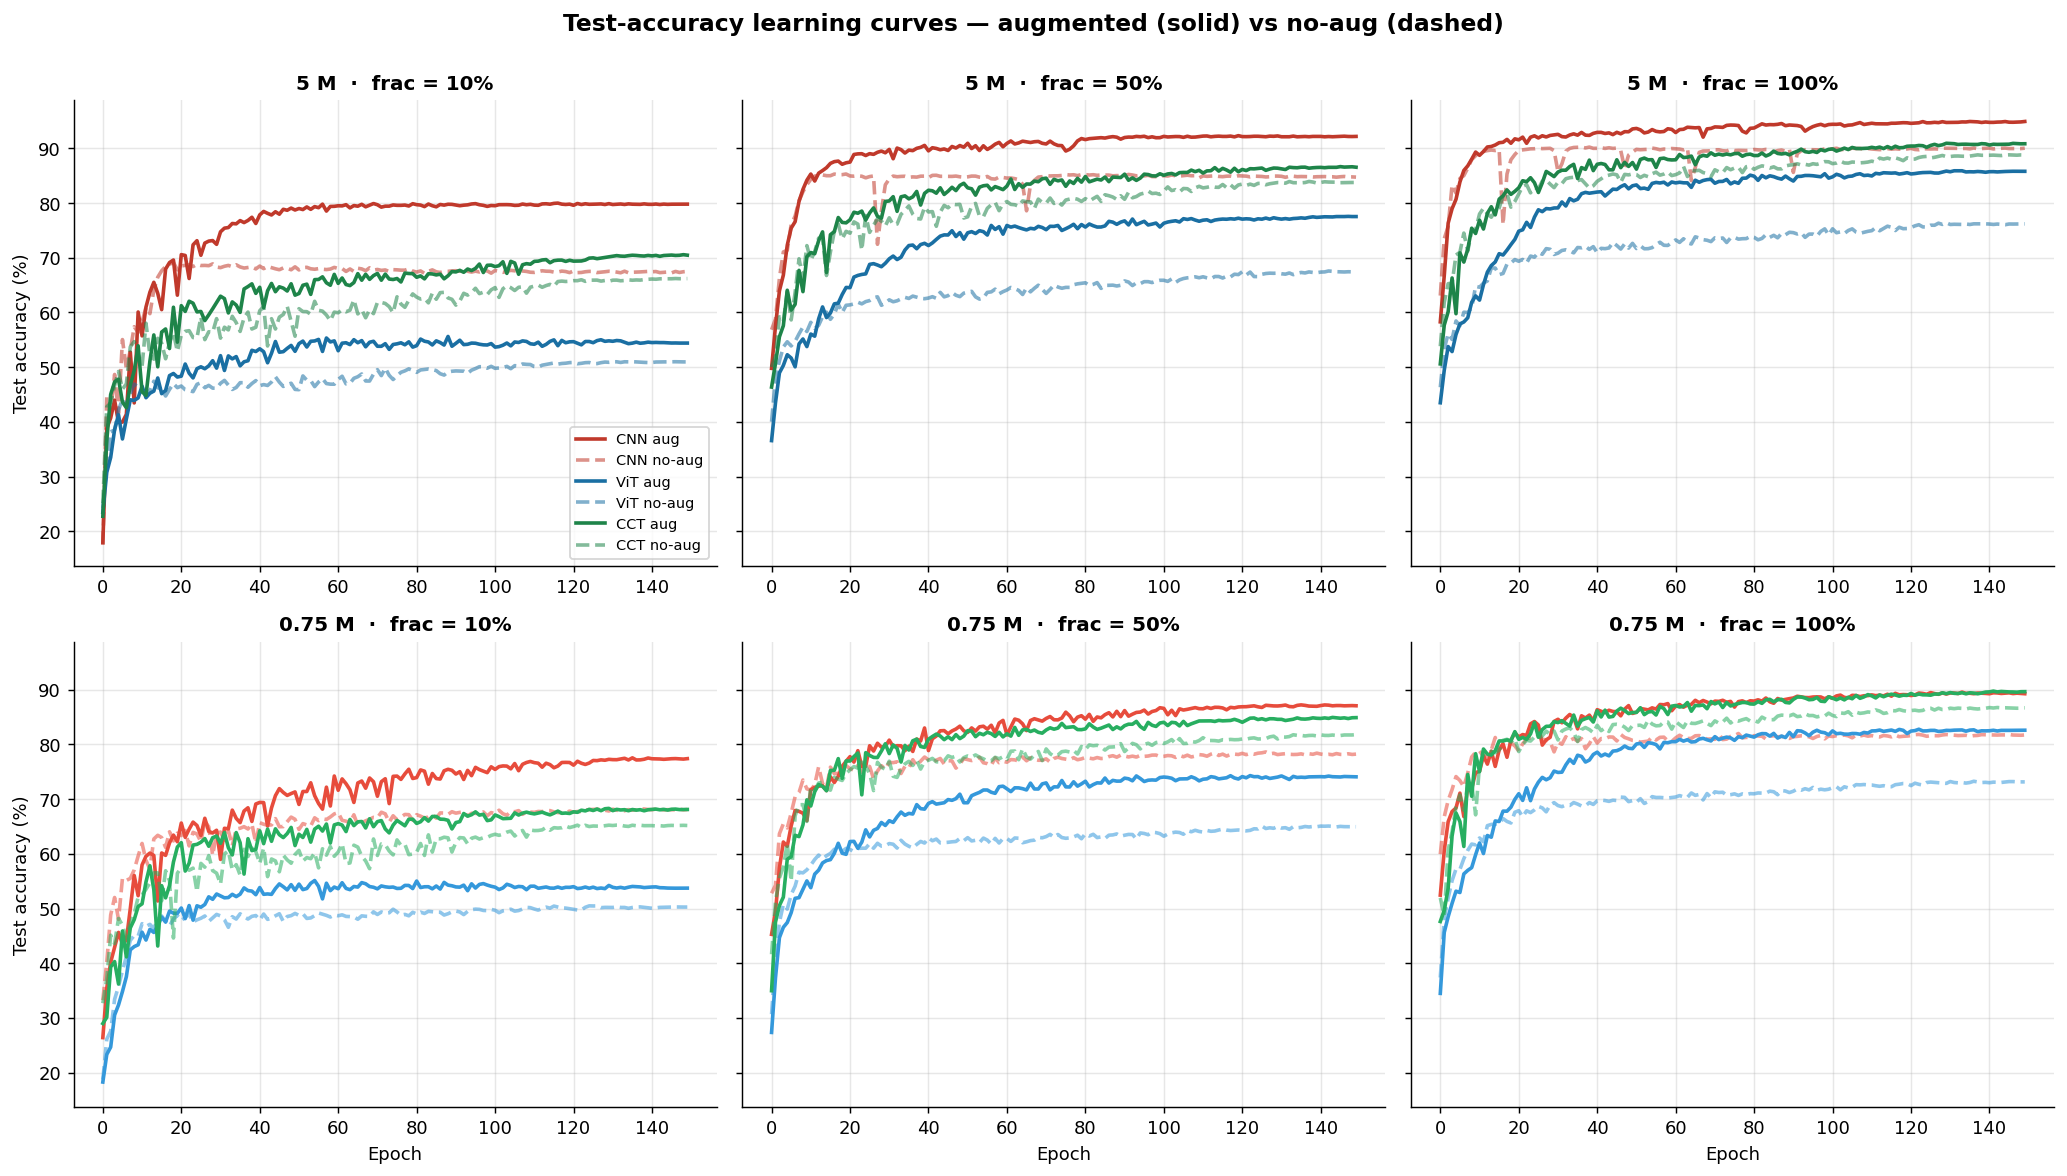

In [29]:
# ── Learning curves: aug vs noaug overlay at the most contrastive fractions ──
KEY_FRACS_AUG = [0.1, 0.5, 1.0]
fig, axes = plt.subplots(2, 3, figsize=(16, 9), sharey=True)

for row, models in enumerate([LARGE_MODELS, SMALL_MODELS]):
    for col, frac in enumerate(KEY_FRACS_AUG):
        ax = axes[row, col]
        for model in models:
            ax.plot(epochs(model, frac), test_acc(model, frac),
                    color=COLORS[model], lw=2.0, label=f'{DISPLAY[model]} aug')
            ax.plot(range(len(test_acc_noaug(model, frac))),
                    test_acc_noaug(model, frac),
                    color=COLORS[model], lw=2.0, ls='--', alpha=0.55,
                    label=f'{DISPLAY[model]} no-aug')
        size_lbl = '5 M' if row == 0 else '0.75 M'
        ax.set_title(f'{size_lbl}  ·  frac = {int(frac*100)}%', fontsize=11, weight='bold')
        ax.grid(alpha=0.3)
        if col == 0: ax.set_ylabel('Test accuracy (%)')
        if row == 1: ax.set_xlabel('Epoch')
        if row == 0 and col == 0: ax.legend(fontsize=8, loc='lower right')

fig.suptitle('Test-accuracy learning curves — augmented (solid) vs no-aug (dashed)',
             fontsize=13, weight='bold', y=1.00)
plt.tight_layout(); plt.show()


**Training loss without augmentation at 10 % data**. Fast loss collapse relative to the
augmented run is a signature of memorisation: this effect should be most visible for ViT, which has no locality prior to constrain it.

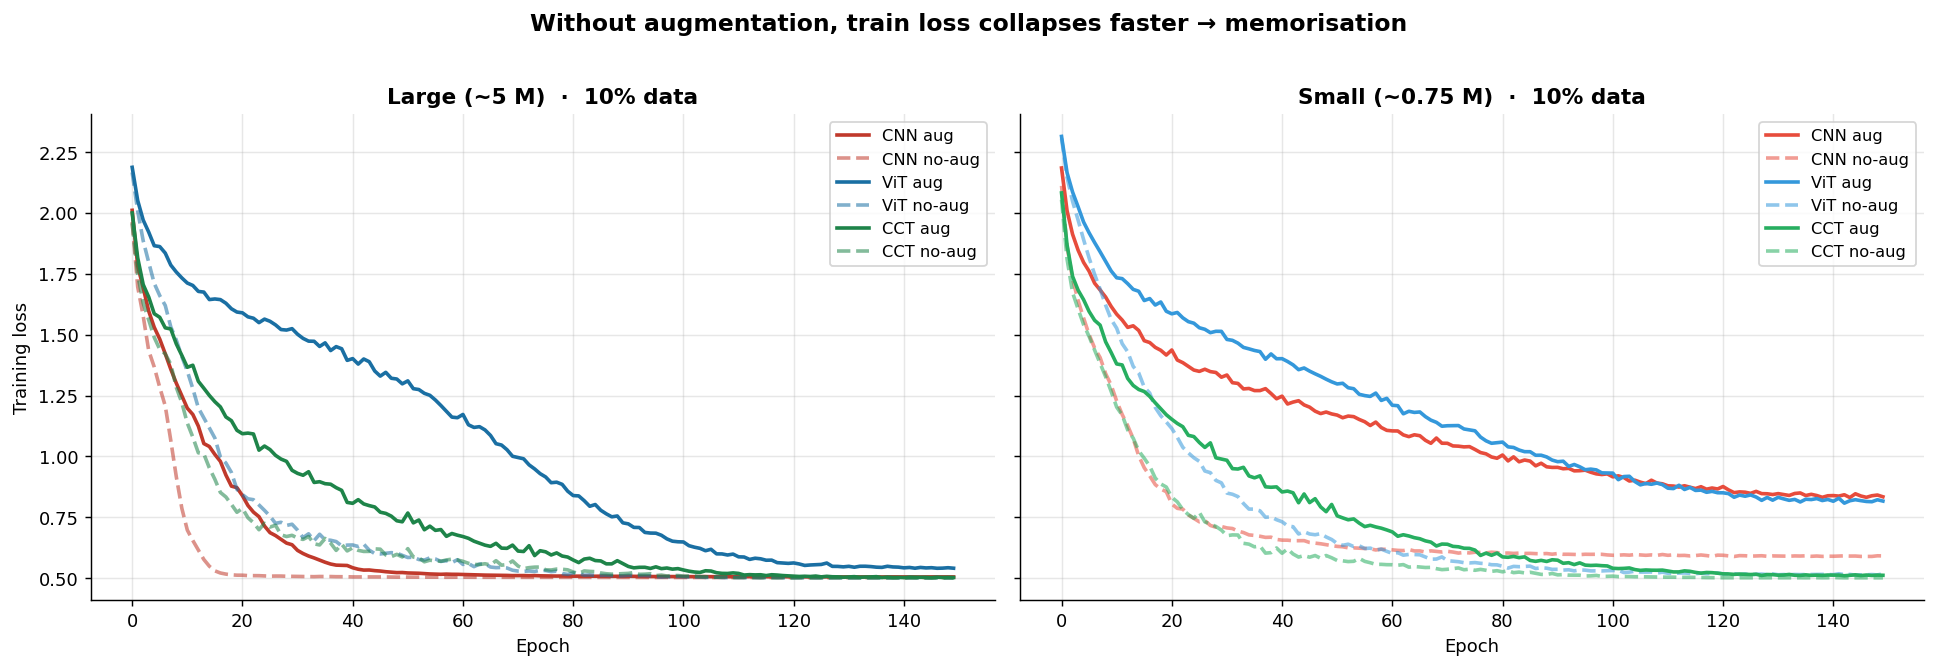

In [30]:
# ── Overfitting view: train-loss curves aug vs no-aug at frac=0.1 ────────────
fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharey=True)

for ax, models, title in zip(
        axes,
        [LARGE_MODELS, SMALL_MODELS],
        ['Large (~5 M)  ·  10% data', 'Small (~0.75 M)  ·  10% data']):
    for model in models:
        ax.plot(epochs(model, 0.1), train_loss(model, 0.1),
                color=COLORS[model], lw=2.0, label=f'{DISPLAY[model]} aug')
        ax.plot(range(len(train_loss_noaug(model, 0.1))),
                train_loss_noaug(model, 0.1),
                color=COLORS[model], lw=2.0, ls='--', alpha=0.55,
                label=f'{DISPLAY[model]} no-aug')
    ax.set_xlabel('Epoch'); ax.set_title(title, fontsize=12, weight='bold')
    ax.grid(alpha=0.3); ax.legend(fontsize=9)
axes[0].set_ylabel('Training loss')
fig.suptitle('Without augmentation, train loss collapses faster → memorisation',
             fontsize=13, weight='bold', y=1.02)
plt.tight_layout(); plt.show()


**Late-epoch stability**: best-minus-final validation accuracy for augmented vs. unaugmented
models. Large values mean the model peaked early and then degraded, which is a sign of overfitting. Augmentation should compress this gap, especially for ViT
  at 10–25 % data.

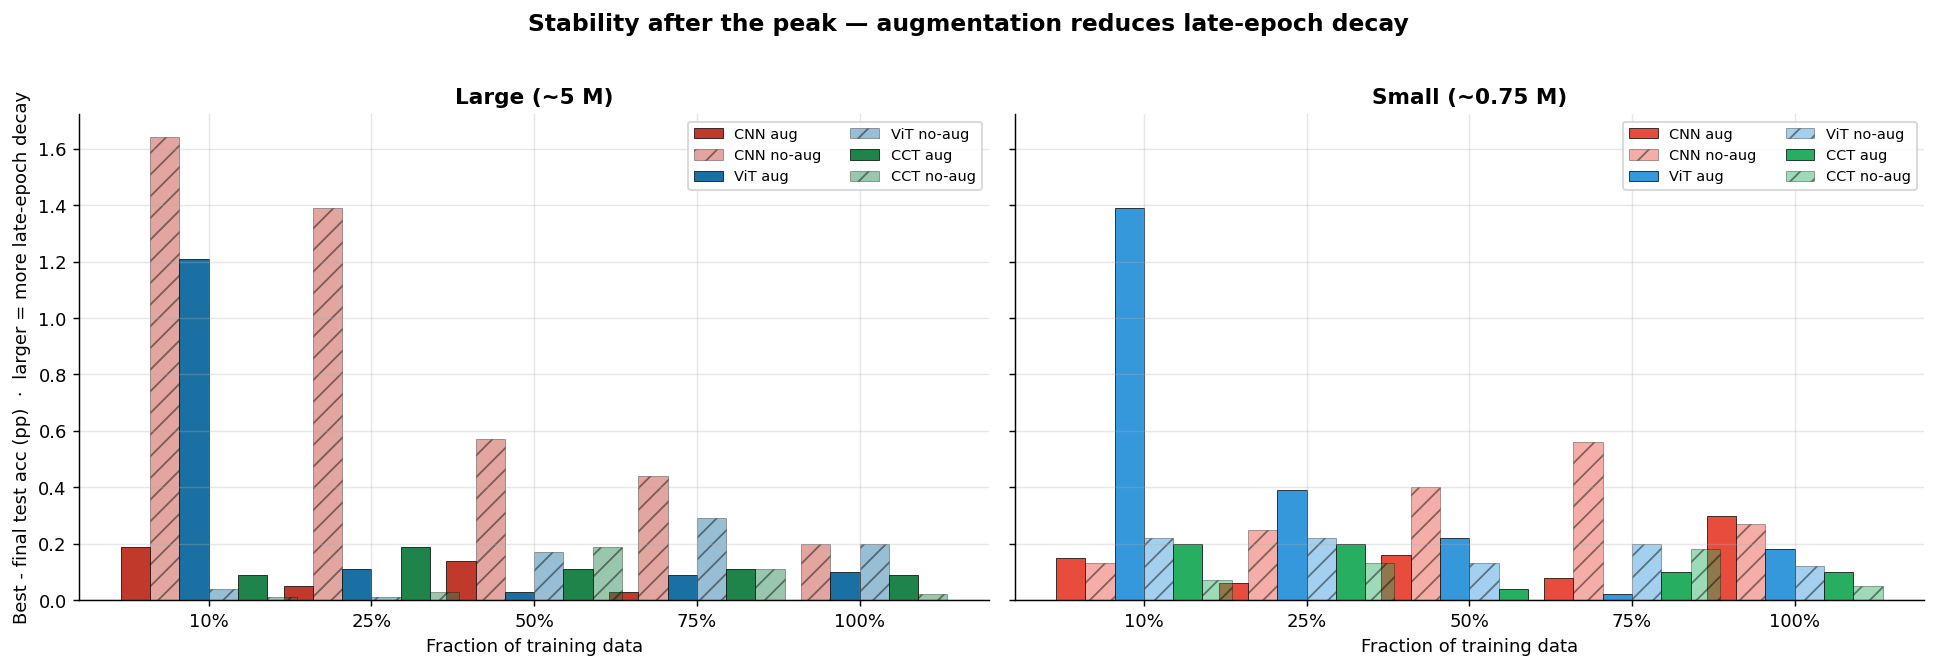

In [31]:
### Interpretation — Augmentation Analysis

# ── Generalisation gap (best test acc − final train acc proxy) per regime ────
def final_train_acc_proxy(history):
    # No train acc stored; use 1 - normalised_loss as a rough proxy via min-loss epoch
    # Better: report the final-epoch test accuracy gap to the best one seen.
    return None

# Instead: report best_acc - final_acc as a stability/overfitting indicator.
fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharey=True)
for ax, models, title in zip(
        axes,
        [LARGE_MODELS, SMALL_MODELS],
        ['Large (~5 M)', 'Small (~0.75 M)']):
    width = 0.18
    x = np.arange(len(FRACTIONS))
    for i, model in enumerate(models):
        aug_drop   = [best_acc(model, f)       - final_acc(model, f)       for f in FRACTIONS]
        noaug_drop = [best_acc_noaug(model, f) - final_acc_noaug(model, f) for f in FRACTIONS]
        ax.bar(x + (i - 1) * 2 * width - width/2, aug_drop, width,
               color=COLORS[model], label=f'{DISPLAY[model]} aug', edgecolor='black', lw=0.4)
        ax.bar(x + (i - 1) * 2 * width + width/2, noaug_drop, width,
               color=COLORS[model], alpha=0.45, hatch='//',
               label=f'{DISPLAY[model]} no-aug', edgecolor='black', lw=0.4)
    ax.set_xticks(x); ax.set_xticklabels([f'{int(f*100)}%' for f in FRACTIONS])
    ax.set_title(title, fontsize=12, weight='bold')
    ax.grid(axis='y', alpha=0.3); ax.legend(fontsize=8, ncol=2)
    ax.set_xlabel('Fraction of training data')

axes[0].set_ylabel('Best - final test acc (pp)  ·  larger = more late-epoch decay')
fig.suptitle('Stability after the peak — augmentation reduces late-epoch decay',
             fontsize=13, weight='bold', y=1.02)
plt.tight_layout(); plt.show()


---
### Interpretation — Augmentation Analysis
The $augmentation$ $analysis$ produces the $most$ $counterintuitive$ $result$ of this study. The conventional expectation — that models without inductive bias benefit most from augmentation, because augmentation substitutes for the missing spatial prior — is reversed at low data fractions. At the smallest training set, the CNN is the largest beneficiary of augmentation, by a margin that is not marginal but substantial. The ViT, the architecture with the weakest spatial prior, gains the least.

Understanding this reversal requires distinguishing between two different roles that augmentation can play. At very low data fractions, augmentation primarily acts as a $signal$ $amplifier$: it increases the effective diversity of the training distribution, allowing the model to see more spatial configurations of the same underlying patterns. For this amplification to translate into better performance, the model must already be in a state coherent enough to exploit additional diversity. The CNN, with its convolutional filters and weight sharing, identifies useful local patterns from the earliest epochs; each augmented view directly reinforces an already-coherent spatial representation. The ViT, at the smallest data fraction, has not yet found any stable signal to reinforce — augmentation's additional variety lands on representations too disorganised to make use of it.

As data grows, this dynamic inverts. The ViT gradually builds a functional spatial understanding, and augmentation shifts from being a signal amplifier to being a $regulariser$ — providing geometric invariances that the architecture does not encode and preventing overfitting to specific spatial configurations. At this point, the ViT gains more, because it has more to gain from regularisation.

The CCT's stability across all fractions and regimes is the clearest single finding of this section. Its convolutional tokenizer already encodes the same invariances — translation and reflection — that random crop and horizontal flip introduce, and augmentation adds what the architecture has already accounted for structurally. This consistency holds regardless of data scale or model size.

The overall pattern is a $crossover$, not a fixed ranking: augmentation is most valuable at low data for models that can immediately exploit it, and most valuable at high data for models that most need regularisation. The initial hypothesis — ViT benefits most — captures the high-data end of this crossover but misses the low-data reversal entirely.


---
# 8 · Linear Probes — How Linearly Separable Is Each Layer?
---

*(Alain & Bengio, ICLR Workshop 2017; Raghu et al., NeurIPS 2021)*

### Why linear probes?

CKA tells us *whether* two layers look alike. It does not tell us *how useful* those representations are for classification. A layer could be highly similar to another model's layer — yet both could be encoding useless noise.

**Linear probes answer a different question: at each layer, how much of the final answer is already there?**

The method is simple: freeze the model completely (no fine-tuning), extract the activations at an intermediate layer, and train a plain logistic regression on top of them. If the probe achieves high accuracy, it means the features at that layer are already linearly separable by class — the network has effectively "solved" the classification problem at that depth, even without the final head.


This is especially informative for our comparison:
- A CNN that builds features hierarchically should show a steady, monotonic probe accuracy increase across layers.
- A ViT that struggles with low data might show weak early-layer probing and a late jump, reflecting that useful features only emerge in the deepest attention blocks.
- A CCT, with its convolutional tokenizer, should show high probe accuracy even at intermediate depths.

---

### Protocol
To compare architectures fairly, every feature map or token sequence is pooled to a fixed-size vector before fitting the probe:

- **CNN** — spatial features `(B, C, H, W)` → global average pool → `(B, C)`
- **ViT / CCT** — token sequences `(B, T, D)` → mean over tokens → `(B, D)`

Probes are trained on a fixed 8 000-image subset of the CIFAR-10 training split and evaluated on the full 10 000-image test set.


### Reading Guide: Linear Probing Analysis
*   **CNNs**: Expected to maintain a more consistent, nearly linear improvement in probing accuracy across layers regardless of data volume(Raghu et al., 2021).
*   **Transformers (ViT/CCT)**: Expected to show a more "U-shaped" or late-recovery profile when data is scarce, transitioning toward a more monotonic rise as data availability allows for better feature specialization in the early and middle blocks.

In [32]:
# ── Probe utilities ──────────────────────────────────────────────────────────
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
import warnings
warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', message='.*lbfgs failed to converge.*')
from torch.utils.data import Subset

# Fixed train subset for the probes (independent of the model's training fraction)
PROBE_TRAIN_N = 8000
probe_train_indices = np.random.RandomState(SEED).choice(
    len(raw_train), size=PROBE_TRAIN_N, replace=False
)

probe_train_dataset = datasets.CIFAR10(
    root='./dataset', train=True, download=False, transform=test_transform,
)
probe_train_subset = Subset(probe_train_dataset, probe_train_indices)
probe_train_loader = DataLoader(probe_train_subset, batch_size=256,
                                shuffle=False, num_workers=0)

def _pool(rep: torch.Tensor) -> np.ndarray:
    # rep is (B, ...); pool to (B, D)
    if rep.ndim == 4:           # CNN feature map (B, C, H, W)
        return rep.mean(dim=(2, 3)).numpy()
    if rep.ndim == 3:           # token sequence (B, T, D)
        return rep.mean(dim=1).numpy()
    return rep.numpy()           # already (B, D)

def _gather_layer_features(model, model_name, loader, layers):
    """Return list (one per layer) of pooled activations stacked across the loader."""
    buffers = [[] for _ in layers]
    handles = []
    for buf, layer in zip(buffers, layers):
        def _hook(m, inp, out, b=buf):
            val = out[0] if isinstance(out, tuple) else out
            b.append(val.detach().cpu())
        handles.append(layer.register_forward_hook(_hook))

    ys = []
    model.eval()
    with torch.no_grad():
        for x, y in loader:
            model(x.to(device))
            ys.append(y.numpy())
    for h in handles: h.remove()

    feats = [_pool(torch.cat(b, dim=0)) for b in buffers]
    return feats, np.concatenate(ys)

def linear_probe_curve(model_name: str, frac: float):
    model  = load_model(model_name, frac)
    layers = get_internal_layers(model, model_name)

    f_tr, y_tr = _gather_layer_features(model, model_name, probe_train_loader, layers)
    f_te, y_te = _gather_layer_features(model, model_name, test_loader,        layers)

    accs = []
    for Xtr, Xte in zip(f_tr, f_te):
        clf = make_pipeline(
            StandardScaler(with_mean=True, with_std=True),
            LogisticRegression(max_iter=2000, C=1.0, solver='lbfgs'),
        )
        clf.fit(Xtr, y_tr)
        accs.append(clf.score(Xte, y_te) * 100)

    del model
    if torch.cuda.is_available(): torch.cuda.empty_cache()
    return accs

print('Probe utilities ready.')


Probe utilities ready.


/opt/anaconda3/envs/project13/lib/python3.11/site-packages/torchvision/datasets/cifar.py:83: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  entry = pickle.load(f, encoding="latin1")


In [33]:
# ── Linear-probe curves: all 6 models × all 5 fractions ──────────────────────
probe_results = {
    model: {frac: linear_probe_curve(model, frac) for frac in FRACTIONS}
    for model in ALL_MODELS
}
print('Probe results ready.')


/opt/anaconda3/envs/project13/lib/python3.11/site-packages/torch/nn/modules/transformer.py:379: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  warnings.warn(
/opt/anaconda3/envs/project13/lib/python3.11/site-packages/torch/nn/modules/transformer.py:379: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  warnings.warn(
/opt/anaconda3/envs/project13/lib/python3.11/site-packages/torch/nn/modules/transformer.py:379: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  warnings.warn(
/opt/anaconda3/envs/project13/lib/python3.11/site-packages/torch/nn/modules/transformer.py:379: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  warnings.warn(
/opt/anaconda3/envs/project13/lib/python3.11/site-packages/torch

Probe results ready.


**Logistic regression accuracy on frozen activations at each layer, plotted against normalised depth.**  
 Steep early rise means useful features form early; a plateau indicates diminishing
returns from additional depth.

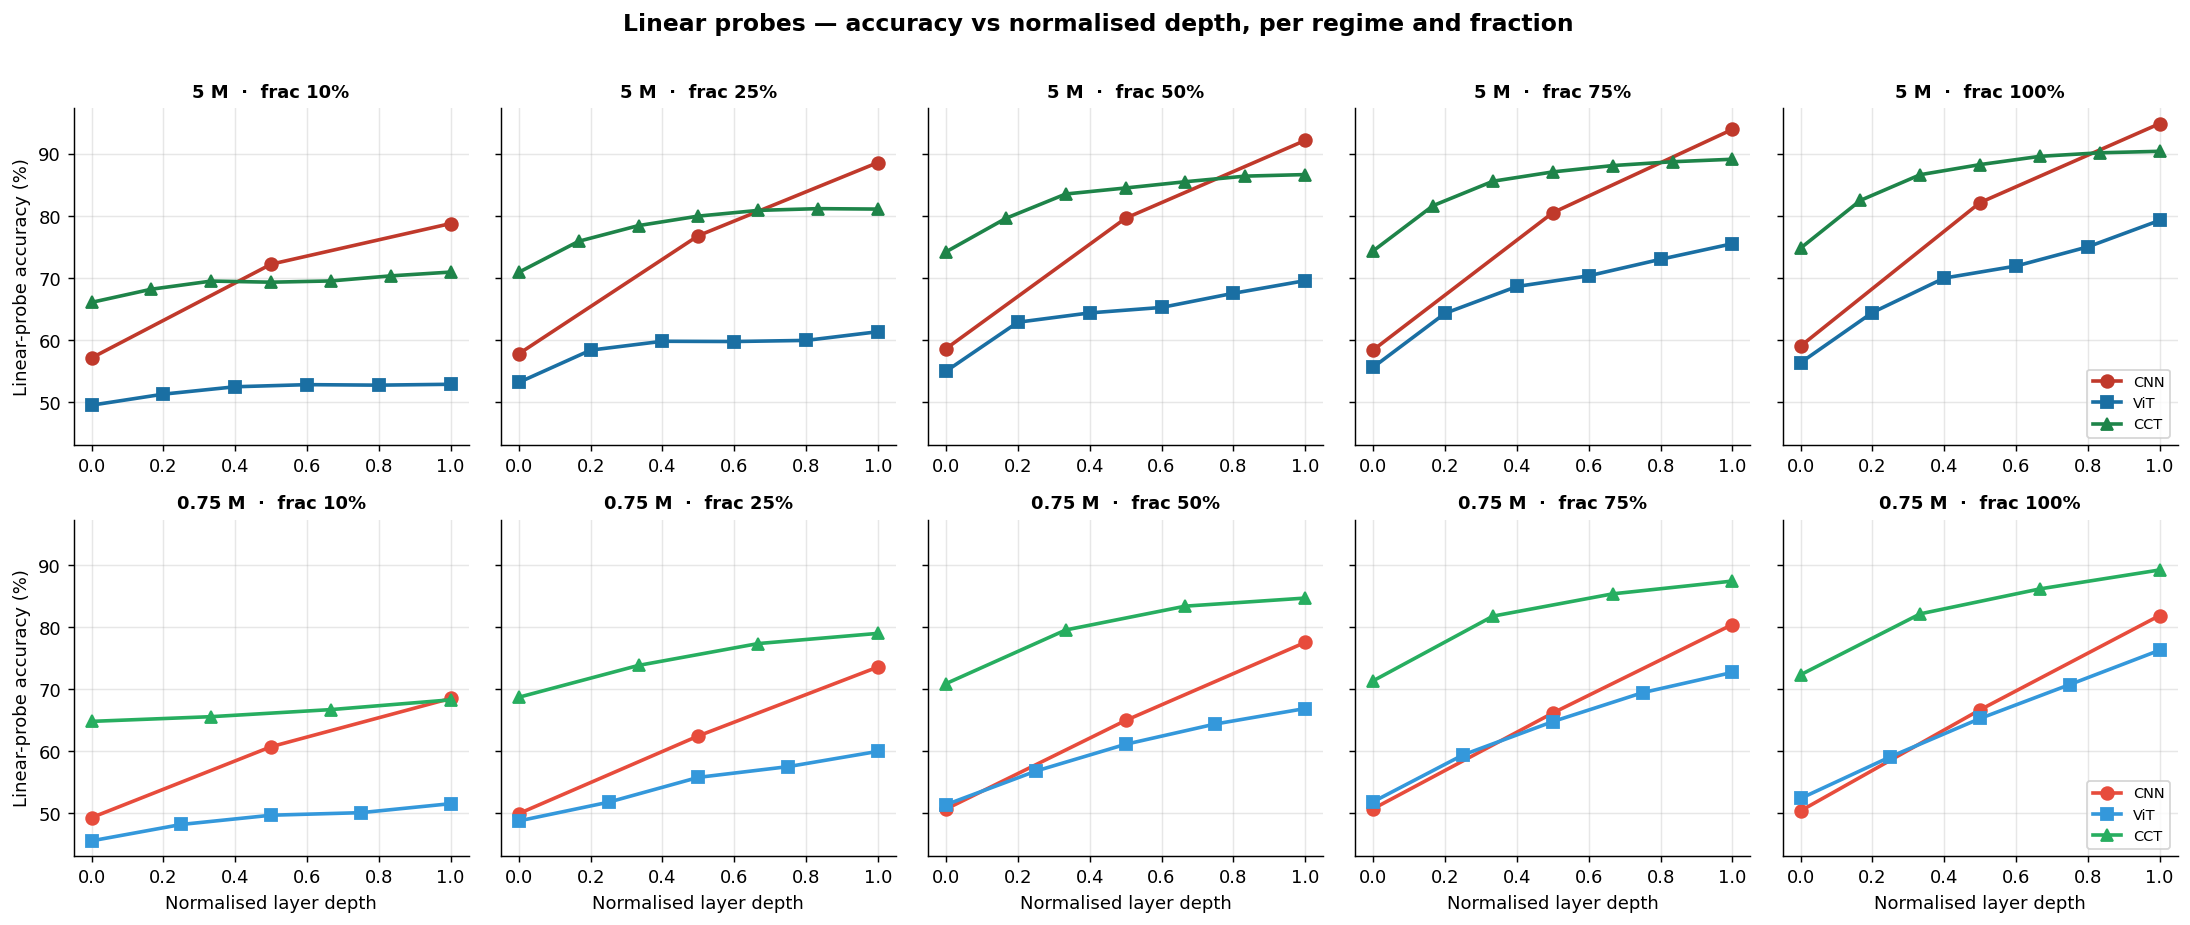

In [34]:
# ── Plot probe curves: 2 rows (regime) × 5 cols (frac) ───────────────────────
fig, axes = plt.subplots(2, len(FRACTIONS), figsize=(3.4 * len(FRACTIONS), 7),
                         sharey=True)

for row, models in enumerate([LARGE_MODELS, SMALL_MODELS]):
    for col, frac in enumerate(FRACTIONS):
        ax = axes[row, col]
        for model in models:
            accs = probe_results[model][frac]
            xs = np.linspace(0, 1, len(accs))
            ax.plot(xs, accs, marker=MARKERS[model], color=COLORS[model],
                    lw=2.0, ms=7, label=DISPLAY[model])
        ax.set_title(f'{"5 M" if row==0 else "0.75 M"}  ·  frac {int(frac*100)}%',
                     fontsize=10, fontweight='bold')
        ax.grid(alpha=0.3)
        if col == 0: ax.set_ylabel('Linear-probe accuracy (%)')
        if row == 1: ax.set_xlabel('Normalised layer depth')
        if col == len(FRACTIONS) - 1: ax.legend(fontsize=8, loc='lower right')

fig.suptitle('Linear probes — accuracy vs normalised depth, per regime and fraction',
             fontsize=13, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('fig_linear_probes.pdf', bbox_inches='tight')
plt.show()


**Deepest-layer probe accuracy** for every model and data fraction — a summary of how
classification-ready the final representation is, independent of the trained head.

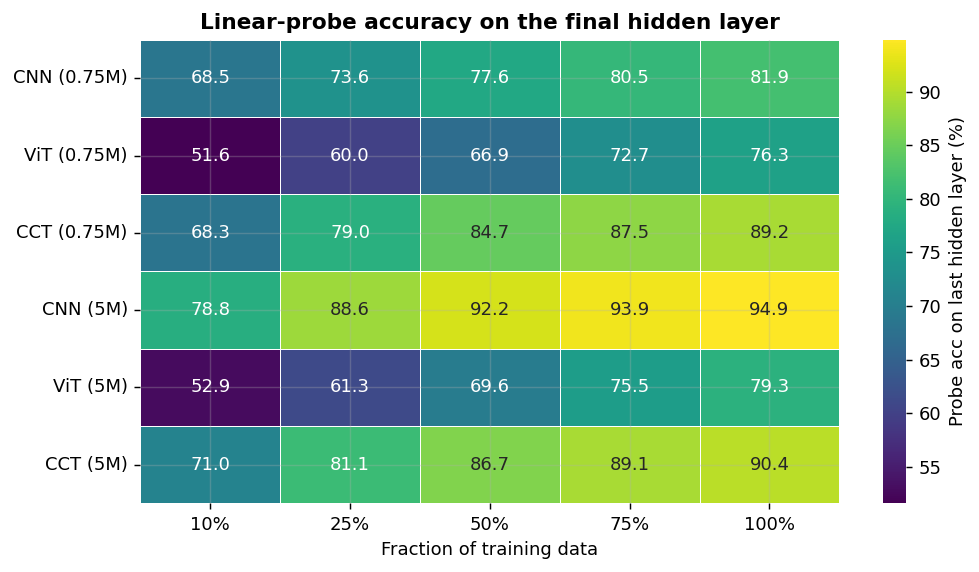

In [35]:
### Interpretation — Linear Probe Analysis

# ── Probe-accuracy heatmap: deepest-layer probe vs fraction ──────────────────
deep = pd.DataFrame(
    [[probe_results[m][f][-1] for f in FRACTIONS] for m in ALL_MODELS],
    index=[f'{DISPLAY[m]} ({"5M" if "large" in m else "0.75M"})' for m in ALL_MODELS],
    columns=[f'{int(f*100)}%' for f in FRACTIONS],
)

fig, ax = plt.subplots(figsize=(8, 4.5))
sns.heatmap(deep, annot=True, fmt='.1f', cmap='viridis',
            cbar_kws={'label': 'Probe acc on last hidden layer (%)'}, ax=ax,
            linewidths=0.5, linecolor='white')
ax.set_title('Linear-probe accuracy on the final hidden layer', fontweight='bold')
ax.set_xlabel('Fraction of training data'); ax.set_ylabel('')
plt.tight_layout()
plt.show()


---
### Interpretation — Linear Probe Analysis
The $linear$ $probe$ results reveal something that accuracy curves and CKA maps leave implicit: not only how well each architecture performs, but at which depth it has already formed representations useful for classification.

The $CNN$ shows the most orderly profile across both regimes. $Probe$ $accuracy$ $rises$ $steadily$ from the first layer to the last, confirming that each convolutional stage genuinely adds classification-relevant structure. Hierarchical feature construction is not merely a theoretical property of CNNs — it is directly observable in the progressive linear separability that accumulates with depth. This behaviour is consistent across all data fractions, suggesting it is structurally enforced rather than learned from data.

The $ViT's$ profile $contrasts$ $sharply$. Its early and intermediate blocks produce representations that a linear classifier cannot exploit well, and improvement across depth is slow and modest. Useful features emerge mainly in the final blocks — and even there, the ViT's representations are less linearly separable than those of the other two models, especially when data is scarce. This late-concentration of representational quality is consistent with the CKA evidence that ViT intermediate layers do not specialise progressively.

The $CCT's$ behaviour is $regime-dependent$ in a revealing way. At the smaller parameter budget, its probe accuracy is high even at intermediate depths, often exceeding the CNN's before the final layer. The convolutional tokenizer delivers linearly separable features early, before the transformer blocks have extensively processed the sequence — the classification structure is partially pre-built into the tokenizer's output. At the larger parameter budget, the CNN's residual architecture overtakes the CCT at the final layer, reversing the ordering.

This regime-dependence is itself informative: the CCT is the most efficient feature-builder per layer when capacity is tight; the CNN leads at full scale. In both cases, the ViT forms the least separable intermediate representations. Inductive bias shapes the internal timeline of feature formation — not just the eventual accuracy ceiling.


---
## 9 · Mean Attention Distance — Local vs. Global Heads
---

*(Raghu et al., NeurIPS 2021)*

### Why attention distance?

Self-attention is the defining operation of Transformer-based models: every token can, in principle, attend to every other token. But *can* does not mean *does*. In practice, different attention heads specialise: some focus tightly on nearby patches (behaving like a local convolution), others scan the entire image globally. Knowing how this mixture of local and global heads distributes across layers is key to understanding what makes ViTs and CCTs different from each other — and from CNNs.

This matters for our comparison because:
- CNNs are *forced* to be local in early layers (kernel size 3×3) and only build global context through stacking. Their receptive field grows deterministically with depth.
- ViTs have no such constraint — they can be global from layer 1. Whether they actually are, and whether this changes with training data, is an empirical question.
- CCTs, with their convolutional tokenizer, are expected to be more local in early layers, gradually shifting to global as depth increases — a behaviour more similar to CNNs.

---

### Mathematical definition

A key structural difference between ViTs and CCTs is *where* each attention head chooses to look. To quantify this, we compute the **mean attention distance** of each head in each layer. For a given head, the attention map $A \in \mathbb{R}^{T \times T}$ (T = 64 patch tokens, CLS dropped) defines a distribution over source tokens for each query token. The mean attention distance for query token $i$ is the expected pixel distance to its attended tokens:

$$d_i = \sum_{j=1}^{T} A_{ij} \cdot \text{dist}(i, j)$$

where $\text{dist}(i, j)$ is the Euclidean distance (in pixels) between the centres of patch $i$ and patch $j$ on the original 32×32 image (patch size = 4 px, so the grid is 8×8 = 64 tokens, maximum distance ≈ 40 px).

The **layer-level distance** is the mean of $d_i$ over all query positions and over a batch of test images. We report one distance per head per layer, sorted within each layer to show the spread of attention behaviours.

**In practice:**
- A head with mean distance **< 8 px** is behaving like a local convolution with a ~2-patch receptive field.
- A head with mean distance **> 20 px** is integrating information from across most of the image.
- High variance across heads within the same layer indicates **head specialisation** — some heads handle local texture while others handle global context simultaneously.


### Reading Guide: Attention Head-Distance Analysis

- **ViT**: typically initializes global attention pathways as early as the first block.
- **CCT**: due to its convolutional tokenizer, it often manifests a higher concentration of **local heads** in early blocks, only broadening its attention span in deeper layers as it moves beyond the inductive bias of the tokenizer.


In [36]:
# ── Capture attention weights ────────────────────────────────────────────────
# ViT models store _captured on self.attn directly in Attention.forward.
# CCT models use nn.TransformerEncoderLayer, so we patch their self_attn.

GRID = 8         # 8x8 patch grid for both ViT (excluding CLS) and CCT
PATCH_PIXELS = 4 # 32 px / 8 grid = 4 px per token

_coords = np.stack(np.meshgrid(np.arange(GRID), np.arange(GRID), indexing='ij'),
                   axis=-1).reshape(-1, 2)  # (64, 2) in (y, x)
PAIRWISE_DIST = np.sqrt(((_coords[:, None, :] - _coords[None, :, :]) ** 2).sum(-1)) * PATCH_PIXELS

def _patch_mha(model):
    handles = []
    for mod in model.modules():
        if isinstance(mod, nn.MultiheadAttention):
            orig = mod.forward
            def make(_orig, _mod):
                def fwd(query, key, value, *args, **kwargs):
                    kwargs['need_weights'] = True
                    kwargs['average_attn_weights'] = False
                    out, w = _orig(query, key, value, *args, **kwargs)
                    _mod._captured = w.detach().cpu()
                    return out, w
                return fwd
            mod.forward = make(orig, mod)
            handles.append((mod, orig))
    return handles

def _unpatch_mha(handles):
    for mod, orig in handles:
        mod.forward = orig

def _list_mha(model_name, model):
    if model_name in ('vit_small', 'vit_large'):
        return [blk.block[0].fn.fn.attn for blk in model.layers]
    if model_name in ('cct_small', 'cct_large'):
        return [layer.self_attn for layer in model.transformer.layers]
    return []

def attention_distances(model_name: str, frac: float, n_batches: int = 4):
    """Return array (n_layers, n_heads) of mean attention distances (px)."""
    model = load_model(model_name, frac)
    mhas  = _list_mha(model_name, model)
    handles = _patch_mha(model)

    weight_acc = [None] * len(mhas)
    model.eval()
    with torch.no_grad():
        for i, (x, _) in enumerate(test_loader):
            if i >= n_batches: break
            model(x.to(device))
            for k, mha in enumerate(mhas):
                w = mha._captured                      # (B, H, T, T)
                if model_name in ('vit_small', 'vit_large'):
                    w = w[:, :, 1:, 1:]                # drop CLS
                weight_acc[k] = w if weight_acc[k] is None else torch.cat([weight_acc[k], w], dim=0)

    _unpatch_mha(handles)
    out = np.zeros((len(mhas), mhas[0]._captured.shape[1]))
    for k, w in enumerate(weight_acc):
        w_np   = w.numpy()
        dists  = (w_np * PAIRWISE_DIST[None, None, :, :]).sum(axis=-1)
        out[k] = dists.mean(axis=(0, 2))

    del model
    if torch.cuda.is_available(): torch.cuda.empty_cache()
    return out

print('Attention-distance utilities ready.')


Attention-distance utilities ready.


In [37]:
# ── Compute attention distances for ViT + CCT, all fractions ─────────────────
ATTN_MODELS = ['vit_small', 'cct_small', 'vit_large', 'cct_large']
attn_dist = {m: {f: attention_distances(m, f) for f in FRACTIONS} for m in ATTN_MODELS}
print('Attention distances ready.')


/opt/anaconda3/envs/project13/lib/python3.11/site-packages/torch/nn/modules/transformer.py:379: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  warnings.warn(


Attention distances ready.


**Mean attention distance (in pixels) per head per layer, for each attention model and data fraction.**  
Each dot is one head; the spread across heads within a layer reveals specialisation: an attention head clustered near zero indicates **local attention** (focusing on immediate neighbors), whereas, a head approaching the theoretical maximum distance (~25 pixels for a 32×32 input) represents **global attention**.

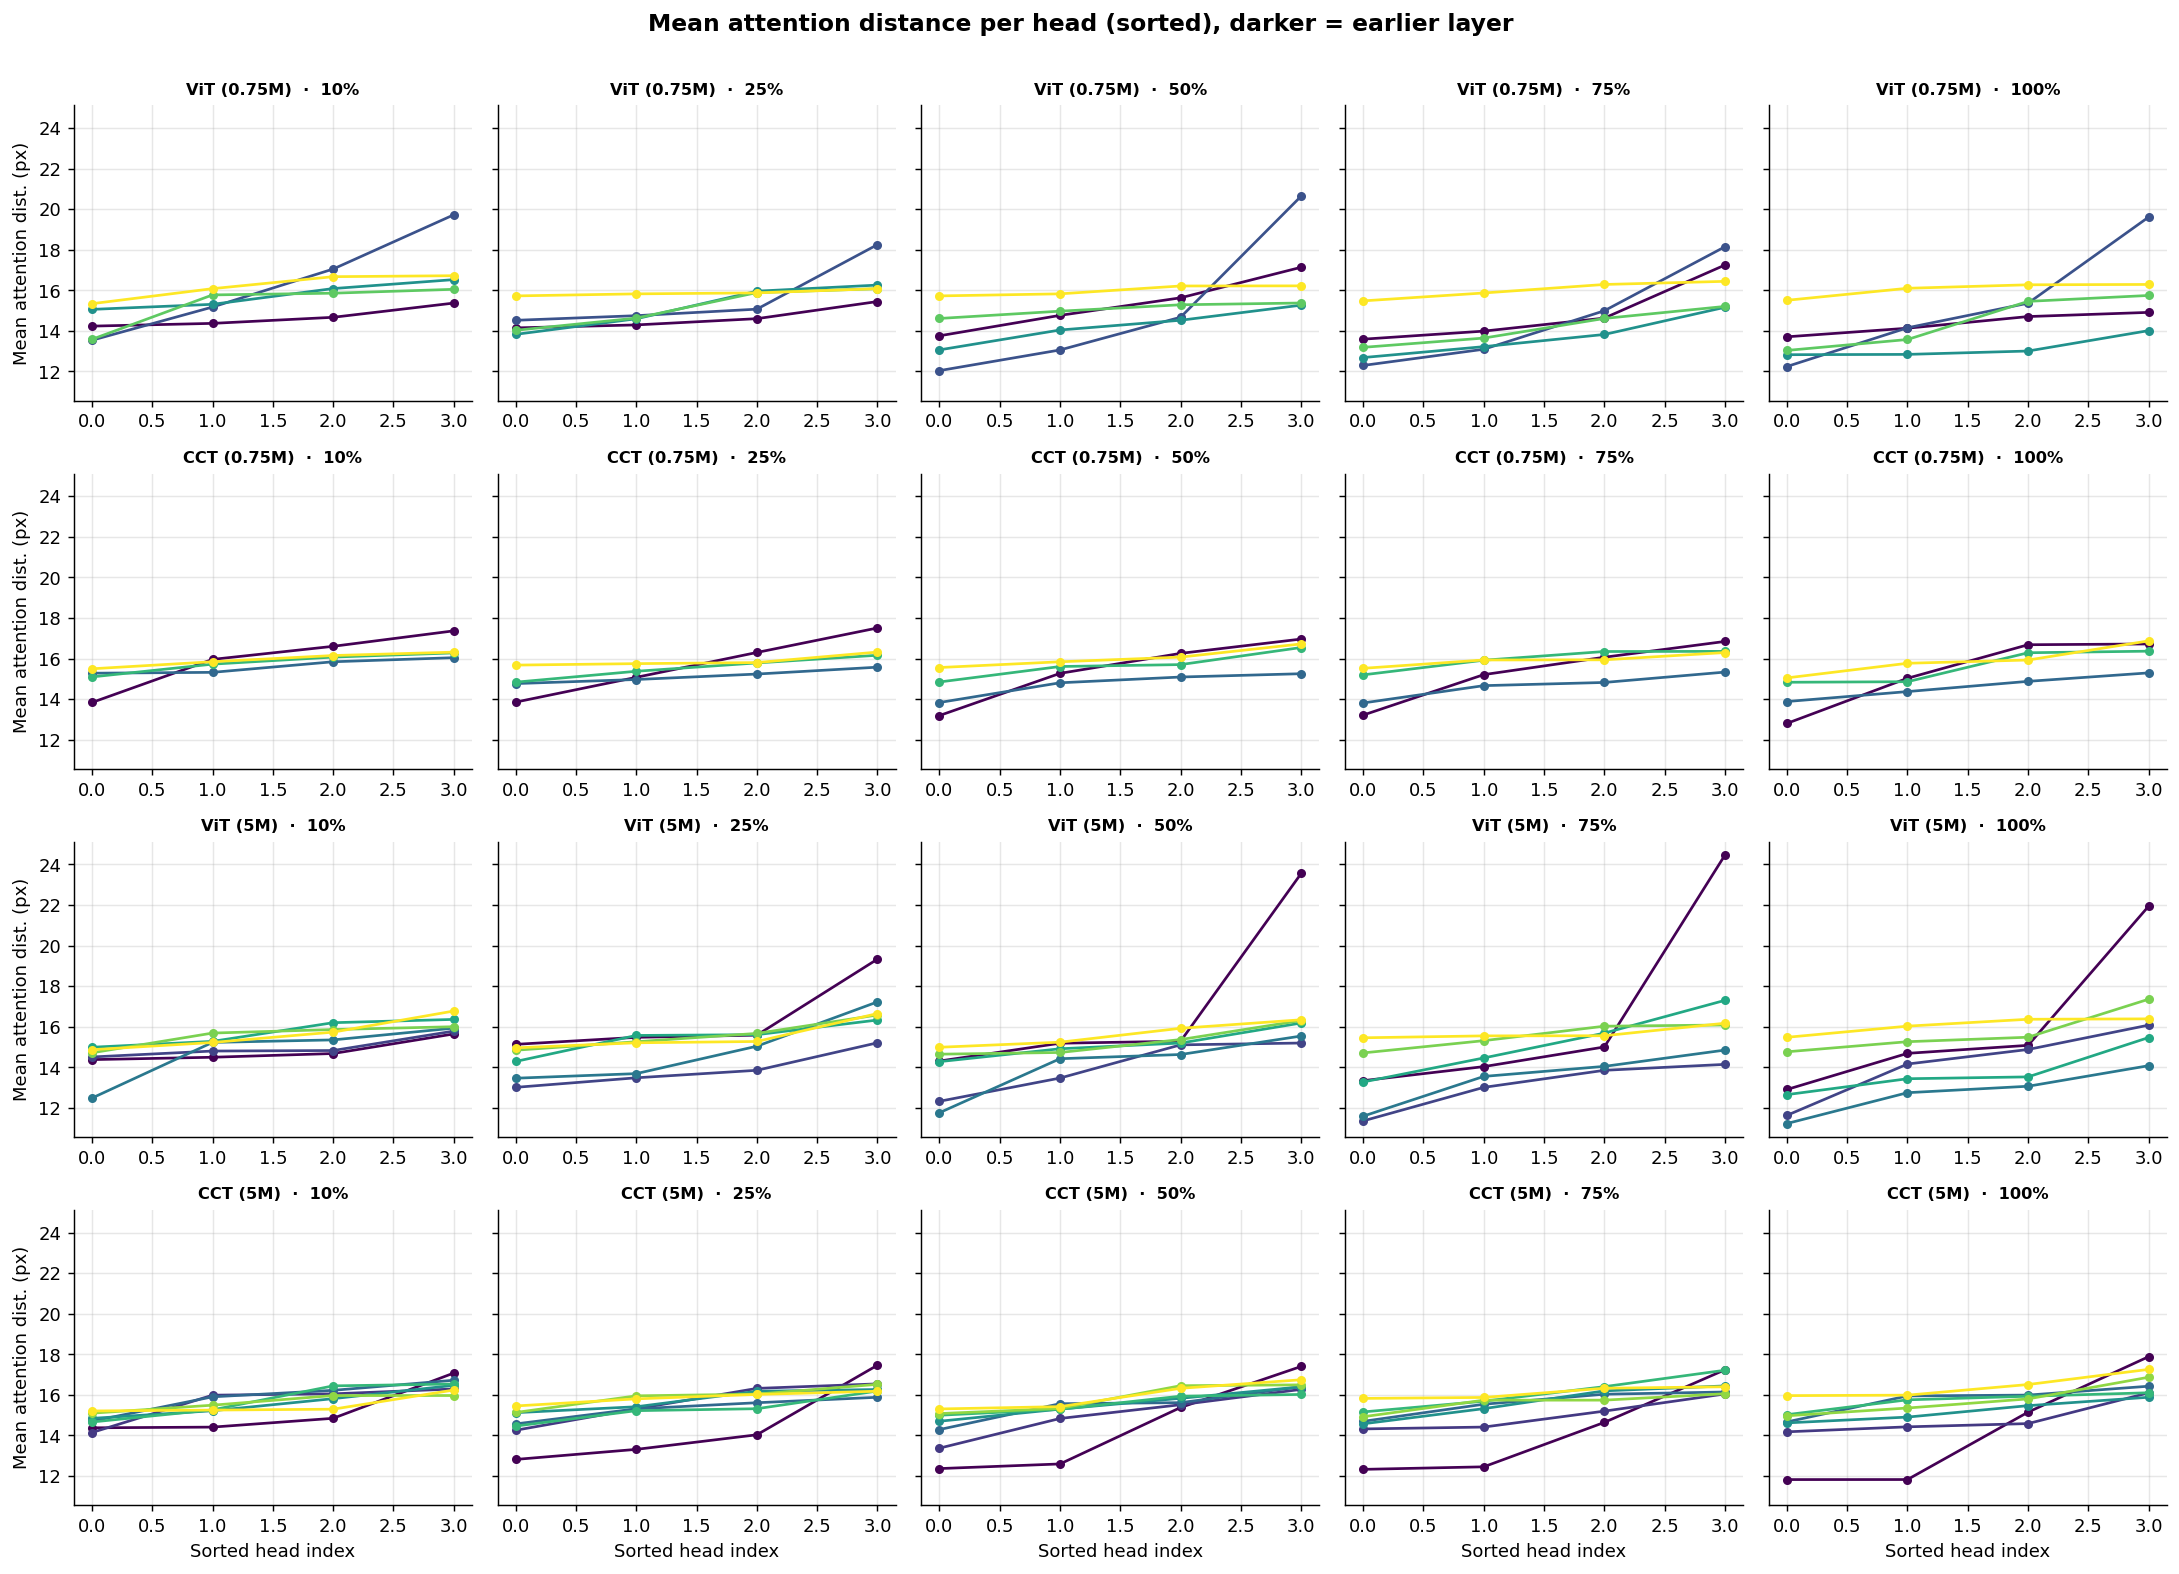

In [43]:
# ── Plot: sorted attention-head distance per layer, one panel per model/frac ─
fig, axes = plt.subplots(len(ATTN_MODELS), len(FRACTIONS),
                         figsize=(3.4 * len(FRACTIONS), 3.0 * len(ATTN_MODELS)),
                         sharey=True)

for row, model in enumerate(ATTN_MODELS):
    for col, frac in enumerate(FRACTIONS):
        ax = axes[row, col]
        D = attn_dist[model][frac]                         # (n_layers, n_heads)
        n_layers, n_heads = D.shape
        cmap = plt.cm.viridis(np.linspace(0, 1, n_layers))
        for L in range(n_layers):
            ax.plot(np.arange(n_heads), np.sort(D[L]),
                    marker='o', ms=4, lw=1.5, color=cmap[L],
                    label=f'L{L+1}' if (row == 0 and col == 0) else None)
        ax.set_title(f'{DISPLAY[model]} ({"5M" if "large" in model else "0.75M"})  ·  '
                     f'{int(frac*100)}%', fontsize=9, fontweight='bold')
        ax.grid(alpha=0.3)
        if col == 0: ax.set_ylabel('Mean attention dist. (px)')
        if row == len(ATTN_MODELS) - 1: ax.set_xlabel('Sorted head index')

fig.suptitle('Mean attention distance per head (sorted), darker = earlier layer',
             fontsize=13, fontweight='bold', y=1.005)
plt.tight_layout()
plt.savefig('fig_attn_distance.pdf', bbox_inches='tight')
plt.show()


**Layer-mean attention distance vs. depth for both regimes.**  
Shows whether attention heads become progressively more global with depth, and whether ViT and CCT differ in how they
allocate local vs. global attention: a flat distribution suggests redundant head behavior, while a steep slope indicates a functional "mix" of local and global feature extraction. An increasing distance with depth shows the network progressively broadening its receptive field, mirroring the hierarchical feature extraction typically seen in CNNs.

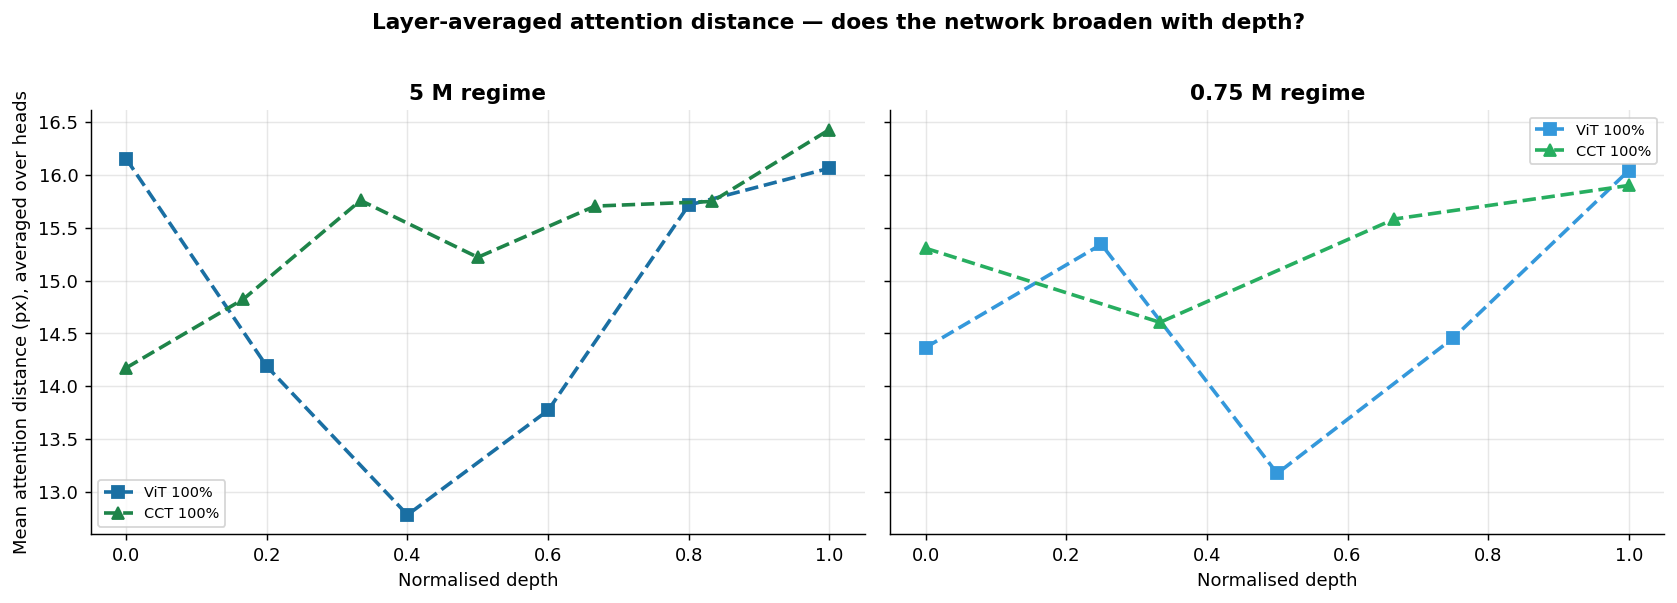

In [39]:
### Interpretation — Mean Attention Distance

# ── Compact view: layer-mean attention distance vs depth at frac=1.0 ─────────
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)

for ax, models, title in zip(
        axes,
        [['vit_large', 'cct_large'], ['vit_small', 'cct_small']],
        ['5 M regime', '0.75 M regime']):
    for model in models:
        for f, ls in zip([1.0], ['--', '-']):
            D = attn_dist[model][f].mean(axis=1)           # mean over heads
            xs = np.linspace(0, 1, len(D))
            ax.plot(xs, D, marker=MARKERS[model], color=COLORS[model], ls=ls,
                    lw=2.0, ms=7, label=f'{DISPLAY[model]} {int(f*100)}%')
    ax.set_xlabel('Normalised depth'); ax.set_title(title, fontweight='bold')
    ax.grid(alpha=0.3); ax.legend(fontsize=8)
axes[0].set_ylabel('Mean attention distance (px), averaged over heads')
fig.suptitle('Layer-averaged attention distance — does the network broaden with depth?',
             fontsize=12, fontweight='bold', y=1.02)
plt.tight_layout(); plt.show()


---
### Interpretation — Mean Attention Distance
The attention distance analysis provides a spatial characterisation of how ViTs and CCTs allocate their processing across depth — and reveals that the difference between the two, while real, is more nuanced than a simple local-versus-global dichotomy.

The $ViT$ operates in a $broadly$ $global$ $attention$ $regime$ throughout its depth. Many of its heads attend to patches far from the query position even in the earliest layers, without any architectural constraint to focus locally. However, the ViT's depth profile is not uniformly monotonic: at the larger parameter scale and with full training data, mean attention distance shows a pronounced non-monotonic pattern, decreasing in intermediate blocks before recovering in the final layers. This suggests that certain intermediate heads spontaneously specialise in more local processing, even without being constrained to do so — a form of $emergent$ $head$ $specialisation$ that reflects the model's lack of a fixed spatial processing hierarchy.

The $CCT$ shows a more $progressive$ $trajectory$. Early layers, shaped by the convolutional tokenizer, produce shorter average attention distances; these increase across depth, reaching ViT-comparable ranges only in the final blocks. This $local-to-global$ progression mirrors, at the level of attention, the spatial hierarchy that CNNs build through stacking convolutions. The important distinction is not where attention ends up, but how it develops: the CCT builds global context progressively, in a way that is more structured and more consistent across heads than the ViT's more variable profile.

In both regimes and across all data fractions, the architectural difference between ViT and CCT dominates the data-scale effect. How much training data a model has seen influences attention distances only mildly; whether the model has a convolutional tokenizer or not determines the structural character of its attention allocation across depth.


---
## 10 · Effective Receptive Fields of ViT Blocks — Gradient Saliency
---

*(Simonyan et al., ICLR Workshop 2014)*

### Why ERF maps?

Attention distance tells us *where* each head looks on average. But average behaviour can be misleading: a head could attend to many tokens with low weight, producing a large mean distance without actually using global context to compute its output.

A more direct question is: **which input pixels actually change the output of a given Transformer block if perturbed?** This is the notion of **effective receptive field (ERF)** — not what the model *can* attend to (all tokens, by definition), but what it *actually depends on* to produce its current representation.


**Why this complements attention distance:**
- Attention distance is a property of the *attention weights* — it tells us the expected displacement in query-key pairs.
- ERF is a property of the *computation graph* — it tells us which pixels causally influence the output, including all non-attention operations (LayerNorm, MLP, residual connections).
- Together, they give a more complete picture: a layer can have global attention weights but still have a local ERF if the residual stream dominates.

---

### Mathematical definition

We estimate the ERF via **gradient saliency**: for each block, we compute the gradient of the mean of its output activations with respect to the input image pixels, then take the absolute value and average over batch and RGB channels:

$$S_\ell(u, v) = \mathbb{E}_{\text{batch}}\left[ \left| \frac{\partial \, \bar{f}_\ell(\mathbf{x})}{\partial \, x_{u,v}} \right| \right]$$

where $\bar{f}_\ell$ is the scalar mean of the $\ell$-th block's output. The resulting 32×32 map $S_\ell$ is normalised to [0, 1] and visualised as a saliency heatmap.

### Reading Guide: Effective Receptive Field (ERF) Maps
We expect the transition from local to global sensitivity differs based on the model's depth:  
- **ViT_large**: with a greater number of blocks, this model is expected to exhibit a more gradual transition from local to global representations.  
- **ViT_small**: due to its shallower depth, this model may transition much faster, potentially exhibiting global integration by Blocks 2 or 3.

In [40]:
def receptive_field_maps_clean(model_name: str, frac: float, n_imgs: int = 32):
    model = load_model(model_name, frac)
    layers = get_internal_layers(model, model_name)
    model.eval()

    batch_x, _ = next(iter(test_loader))
    batch_x = batch_x[:n_imgs].to(device)

    maps = []
    for idx, layer in enumerate(layers):
        x = batch_x.clone().detach().requires_grad_(True)
        layer_output = None

        def hook(module, input, output):
            nonlocal layer_output
            layer_output = (output[0] if isinstance(output, tuple) else output).clone()

        handle = layer.register_forward_hook(hook)
        model.zero_grad()
        model(x)
        handle.remove()

        loss = layer_output.mean()
        loss.backward()

        sal = x.grad.detach().abs().mean(dim=(0, 1)).cpu().numpy()
        maps.append(sal / (sal.max() + 1e-8))

    del model
    if torch.cuda.is_available(): torch.cuda.empty_cache()
    return maps

# Run
print('Computing ViT Large maps...')
rf_maps_vit_large = receptive_field_maps_clean('vit_large', 1.0)

print('Computing ViT Small maps...')
rf_maps_vit_small = receptive_field_maps_clean('vit_small', 1.0)

print(f'ViT Large: {len(rf_maps_vit_large)} maps')
print(f'ViT Small: {len(rf_maps_vit_small)} maps')


Computing ViT Large maps...
Computing ViT Small maps...
ViT Large: 6 maps
ViT Small: 5 maps


The $Effective$ $Receptive$ $Fields$ $(ERF)$ maps visualize spatial influence by showing which input pixels most significantly contribute to the representation at a given Transformer block. These maps are generated using gradient-based saliency techniques for both ViT_small and ViT_large. The following patterns can be observed:\
$1)$ A $structured$ or $concentrated$ $pattern$ — such as a bright central spot or a regular grid tiling the image — indicates that the block's representation is dominated by specific spatial regions or positional encodings rather than the full input context.\
$2)$ A $diffuse$ $'glow'$ extending across the entire 32×32 grid suggests that the block is integrating information from distant parts of the image, characterizing broad spatial sensitivity and global attending behavior.

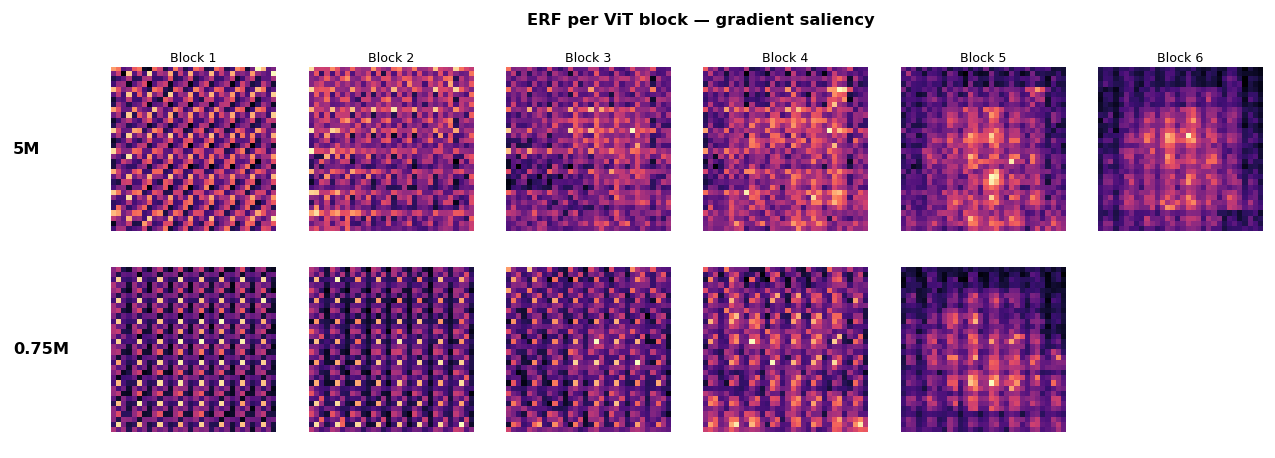

In [41]:
fig, axes = plt.subplots(2, max(len(rf_maps_vit_large), len(rf_maps_vit_small)),
                         figsize=(1.8 * max(len(rf_maps_vit_large), len(rf_maps_vit_small)), 3.5))

plt.subplots_adjust(hspace=0.05, top=0.88, bottom=0.02, left=0.08)

for row, (maps, label) in enumerate([
        (rf_maps_vit_large, '5M'),
        (rf_maps_vit_small, '0.75M')]):
    for col in range(axes.shape[1]):
        ax = axes[row, col]
        if col < len(maps):
            ax.imshow(maps[col], cmap='magma')
            if row == 0:
                ax.set_title(f'Block {col+1}', fontsize=7, pad=3)
        ax.axis('off')

    y_center = axes[row, 0].get_position().y0 + axes[row, 0].get_position().height / 2
    fig.text(0.01, y_center, label, fontsize=9, fontweight='bold', va='center', ha='left')

fig.suptitle('ERF per ViT block — gradient saliency', fontsize=9, fontweight='bold', y=0.97)
plt.savefig('fig_receptive_fields.pdf', bbox_inches='tight', dpi=150)
plt.show()

---
### Interpretation — Effective Receptive Fields
The effective receptive field maps add an important qualification to the attention-distance results: the ability to attend globally from the first block — which ViTs have by design — does not mean that the model's output $functionally$ $depends$ on the full image from the very beginning.

The earliest blocks of both ViT_large and ViT_small display a structured, repetitive pattern that tiles the entire image. This is not random scatter, nor a spatially localised concentration. It reflects the learned positional embedding: before the attention mechanism has had time to mix information across patches, each token's gradient signal is dominated by its fixed spatial encoding. The $early$ $ERF$ maps show $position-driven$ $structure$, not content-driven locality — a meaningful distinction that the straightforward "local-then-global" narrative obscures.

As $depth$ $increases$, this positional signature fades and is replaced by a more diffuse, $globally$ $spread$ $sensitivity$. The intermediate blocks begin to genuinely integrate information across patches, and the gradient maps become less structured but more widespread: the block's output depends on a progressively broader spatial region, consistent with the successive mixing of token representations through attention operations.

By the final blocks, the sensitivity has reorganised into a soft central concentration — a learned statistical prior reflecting the fact that objects in CIFAR-10 images are typically centred. This is not an artifact of the architecture but a genuine signal extracted from the training distribution, made visible through the gradient maps.

ViT_small shows this full progression compressed into fewer blocks: the transition from positional structure to global integration to central concentration happens faster, with global sensitivity appearing already by the third block. ViT_large distributes the same transitions more gradually across its six blocks, consistent with having more processing stages available.

The overarching lesson is that structural capacity and functional sensitivity are not the same. ViTs can attend globally from block one — but they build genuine global effective receptive fields progressively, following a trajectory shaped first by positional encodings and only later by the image content itself.


---
## 11 · Summary Table
---

In [42]:
print(f"{'Model':<12}  {'Params':>10}  {'10%':>7}  {'25%':>7}  {'50%':>7}  {'75%':>7}  {'100%':>7}  {'Best ep':>10}")
print('─' * 80)
# Print large first (primary), then small (secondary)
for model in LARGE_MODELS + SMALL_MODELS:
    n_p = param_counts[model]
    best_eps = []
    for frac in FRACTIONS:
        accs = [h['acc'] for h in results[model][frac]]
        best_eps.append(int(np.argmax(accs)))
    accs_row = '  '.join(f'{best_acc(model, f):7.2f}' for f in FRACTIONS)
    ep_str   = '/'.join(str(e) for e in best_eps)
    print(f'{model:<12}  {n_p:>10,}  {accs_row}  {ep_str:>10}')
    if model == 'cct_large':
        print('─' * 80)
print()
print('Accuracies shown are best test accuracy over 150 epochs.')
print('Top block = primary 5 M regime (CNN vs ViT focus).')
print('Bottom block = secondary 0.75 M regime (CNN vs CCT focus).')

Model             Params      10%      25%      50%      75%     100%     Best ep
────────────────────────────────────────────────────────────────────────────────
cnn_large      4,904,522    79.99    88.62    92.32    93.97    94.91  116/137/119/131/135
vit_large      4,976,970    55.61    68.39    77.56    82.52    85.90  88/115/147/133/131
cct_large      5,261,467    70.56    81.32    86.66    89.47    90.93  148/145/145/139/129
────────────────────────────────────────────────────────────────────────────────
cnn_small        765,546    77.55    83.47    87.23    88.36    89.57  135/140/135/137/133
vit_small        760,906    55.12    65.91    74.30    79.60    82.78  54/115/122/147/122
cct_small        727,467    68.31    79.39    84.94    87.72    89.75  129/130/143/133/141

Accuracies shown are best test accuracy over 150 epochs.
Top block = primary 5 M regime (CNN vs ViT focus).
Bottom block = secondary 0.75 M regime (CNN vs CCT focus).


---
## 12 · Discussion — Why Does the CNN Benefit More from Augmentation at Low Data?
---


The $augmentation$ $crossover$ — $CNN$ $benefits$ $more$ at $low$ $data$, $ViT$ benefits more at $high$ $data$ — is the most surprising finding of this study. Below we provide a mechanistic account of why this happens.

---

### 1 · Weight sharing amplifies each augmented sample

A convolutional filter is applied at $every$ $spatial$ $position$ of the input. When a randomly cropped image feeds into the CNN, the filter receives gradient updates from `H × W` different spatial locations simultaneously. A single augmented image therefore provides far more gradient signal per parameter than the same image passed through a ViT, whose attention heads process specific token pairs without spatial weight sharing.

At 10 % data (5 000 images), this amplification is critical: augmentation effectively multiplies the number of "useful gradient directions" the CNN sees, while for the ViT each augmented view still provides the same number of gradient updates per attention weight.

---

### 2 · Augmentation is aligned with the CNN's inductive bias

Random crop and horizontal flip encode two specific geometric invariances: $translation$ and $reflection$ $symmetry$. These are $precisely$ the invariances that a CNN is architecturally designed to learn (via weight sharing and pooling). Augmentation and architecture point in the same direction: each augmented view reinforces a prior the model already has.

For the ViT, the same augmented views create $new$ $positional$ $configurations$ that the model must learn to handle without any structural guidance. The positional embedding has to generalise to shifted patches without the support of translation equivariance — a harder learning problem that requires more data to resolve.

---

### 3 · Gradient coherence at very low data

At 5 000 images, a ViT's gradient signal is largely dominated by noise: the attention weights have not yet identified any consistent spatial pattern, so gradient updates from different augmented views partially cancel. The CNN, by contrast, finds useful structure (edges, textures) from the very first epoch thanks to its local filters, producing coherent gradients that augmented views can meaningfully reinforce.

This explains why the ViT augmentation gain at 10 % is pretty low despite the model being far from its accuracy ceiling: it is not that augmentation provides no information, but that the model is not yet in a state to absorb it.

---

### 4 · Crossover mechanism at high data

As training data grows, two things change simultaneously:

1. The ViT begins to learn genuine spatial statistics. With 25 000–50 000 images, attention heads start to specialise and gradients become more coherent. Augmentation now adds $meaningful$ $diversity$ rather than noise — and since the ViT has no built-in constraint against overfitting spatial positions, the diversity acts as a strong regulariser.

2. The CNN's augmentation benefit shrinks because its inductive bias already handles most of the invariance. At 50 000 images the CNN can identify the relevant spatial patterns from unaugmented data alone; augmentation provides diminishing returns.

The crossover — empirically at ~25 %–50 % data in both regimes — marks the point where the ViT has enough data to exploit augmentation's regularisation effect more than the CNN can exploit its amplification effect.

---

### 5 · Why CCT is augmentation-independent throughout

The CCT's convolutional tokenizer applies 3×3 convolutions with stride-2 max pooling $before$ the transformer. This pre-processes the image into a feature map that is already locally invariant to small shifts and reflections. Augmentation (random crop = shift, horizontal flip = reflection) operates on the raw pixel input — but the invariance it would introduce is already built into the tokenizer. The gain from augmentation is therefore negligible at every data fraction, because the architecture has absorbed the invariance structurally rather than learning it from data.
